# **Analiza EEG z MNE-Python**: potencjał P3 w danych ERP CORE
---
### Pełny przebieg analizy w jednym notatniku: od pobrania danych BIDS do klasyfikacji i jej weryfikacji

Analiza obejmuje wczytanie danych EEG zgodnie ze standardem BIDS, przygotowanie sygnału, wyznaczenie potencjału **P3** i porównanie warunków na poziomie uczestników. Przygotowanie sygnału obejmuje kanały EOG, zmianę odniesienia, filtrację, epokowanie, ICA i kontrolę jakości. Klasyfikator odróżnia bodźce docelowe od niedocelowych bez wykorzystywania etykiet osób testowych do dopasowania modelu. Indywidualne ICA i kontrola jakości uwzględniają jednak nieoznakowane sygnały tych osób, dlatego przetwarzanie ma charakter transdukcyjny.

**Wersja 1.6.5 | 20 listopada 2026 r.**

Analiza przebiega od opisu metody przez przetwarzanie danych i prezentację wyników do ich interpretacji. Poszczególne etapy zawierają uzasadnienie wyboru parametrów, opis danych wyjściowych i ograniczenia wnioskowania.

Zbiór ERP CORE [1] obejmuje dane 40 zdrowych dorosłych, którzy wykonywali sześć zadań pozwalających analizować siedem klasycznych składowych ERP. W tej analizie wykorzystano zadanie **P3**, oparte na wzrokowym paradygmacie rzadkiego bodźca docelowego (*oddball*). Dane pochodzą z OSF [2].

Do wykonania analizy potrzebny jest Python w wersji co najmniej 3.10 oraz dostęp do internetu przy pierwszym pobieraniu danych. Dane pięciu uczestników zajmują około 300 MB, a 30 uczestników około 1,6 GB. Czas obliczeń zależy od liczby osób i kosztu dekodowania w czasie. Polecenie instalacyjne zapisano w komentarzu pierwszej komórki, dlatego w razie potrzeby należy je wykonać osobno.

Rysunki poglądowe i animacje przedstawiające sztucznie wygenerowane przebiegi są wyraźnie oznaczone. Wyniki dotyczące uczestników powstają wyłącznie po wczytaniu i przetworzeniu danych ERP CORE. Każda analiza wymaga kontroli poprawności kodów zdarzeń, kanałów oraz jakości rejestracji.

| Część | Zakres |
|---|---|
| I | zbiór, pobranie, BIDS, wczytanie, kanały EOG, montaż |
| II | kontrola sygnału, widmo, odniesienie, filtry, zdarzenia, epoki, ICA, jakość |
| III | ERP: średnie, fala różnicowa, topografia, test grupowy |
| IV | uczenie maszynowe: dane, dekodowanie w czasie, okno P3, walidacja, wzorce |
| V | eksport wyników, ograniczenia, bibliografia |

### Jak czytać zapis analizy?
Przy każdym etapie warto oddzielić **pytanie badawcze**, **operację na sygnale**, **wynik** i **ograniczenia jego interpretacji**. Przedstawione fragmenty Pythona pozwalają odtworzyć operacje i sprawdzić ich parametry.

| Pojęcie | Znaczenie |
|---|---|
| **EEG** — elektroencefalogram (zapis), **elektroencefalografia** (metoda) | Zmiany różnicy potencjałów elektrycznych rejestrowane na powierzchni głowy; nie jest to bezpośredni pomiar „ilości uwagi” ani aktywności pojedynczego obszaru mózgu. |
| **ERP** — potencjały związane ze zdarzeniami (ang. *event-related potentials*) | Zwykle uśredniona odpowiedź EEG zsynchronizowana z określonym zdarzeniem, tutaj pojawieniem się litery. |
| **Epoka (fragment zapisu przypisany do próby)** | Krótki odcinek zapisu EEG przypisany do jednego bodźca, np. od 200 ms przed do 800 ms po literze. |
| **EOG** — elektrookulogram; **elektrookulografia** — metoda | Rejestracja zmian potencjału związanych przede wszystkim z ruchami gałek ocznych i mruganiem. |
| **ICA** — analiza składowych niezależnych | Metoda rozdzielania wielokanałowego sygnału na składowe statystyczne, wykorzystywana między innymi do korekcji artefaktów. |
| **BIDS** — standard organizacji danych neuroobrazowych | Reguły nazewnictwa, struktury katalogów i metadanych; nie jest to pojedynczy format pliku EEG. |
| **P3 / P3b** — dodatnia składowa potencjału związanego ze zdarzeniem | Dodatnia składowa ERP, często silniejsza dla istotnych, rzadszych bodźców wymagających rozpoznania. Interpretuje się ją w kontekście selekcji informacji i aktualizacji reprezentacji zadania, nie jako prosty „test uwagi”. |
| **Amplituda [µV]** | Wielkość napięcia w danym kanale i oknie czasowym; zależy również od odniesienia, przetwarzania i właściwości osoby. |
| **Latencja [ms]** — czas wystąpienia składowej | Czas od prezentacji bodźca do punktu charakterystycznego w ERP; nie jest czasem reakcji ręką. |
| **Pz, Cz, Fz** | Elektrody w okolicy ciemieniowej, centralnej i czołowej. Nazwa wskazuje miejsce pomiaru, nie pewne źródło sygnału w korze. |
| **Artefakt** | Niepożądana składowa lub zniekształcenie zapisu, np. po mrugnięciu, ruchu lub zakłóceniu elektrycznym; nie należy interpretować go jako procesu poznawczego. |
| **Walidacja krzyżowa modelu** | Sprawdzenie, czy model wyuczony na danych uczących działa na danych, których nie użyto do uczenia. Tu ważne jest testowanie na **innych osobach**. |

FIR oznacza filtr o skończonej odpowiedzi impulsowej, IIR — filtr o nieskończonej odpowiedzi impulsowej, a AUC — pole pod krzywą ROC. ROC przedstawia zależność odsetka poprawnych wykryć od odsetka fałszywych alarmów przy zmianie progu klasyfikacji. Nazwy bibliotek, funkcji i pól BIDS zachowują oryginalną pisownię.

W badaniu sprawdzamy, czy odpowiedź EEG na literę docelową, wymagającą rozpoznania w danym bloku, różni się od odpowiedzi na pozostałe litery? Operacyjna odpowiedź to przede wszystkim **różnica amplitudy ERP (cel − niecel) na Pz między 300 a 600 ms**. Ujemny wynik, słaby efekt albo brak istotności nie są rozstrzygającym dowodem braku uwagi; należy uwzględnić dokładność pomiaru, liczbę osób, jakość EEG i sposób analizy.

Analizowany jest zapis związany z pojawieniem się bodźca. Notatnik nie obejmuje odrębnej analizy czasów reakcji ani poprawności odpowiedzi. Przykładowe rysunki są ilustracjami metody, a nie wynikami uzyskanymi z rzeczywistych pomiarów.


---

## 0. Przygotowanie środowiska
Pierwsza komórka instaluje wymagane pakiety (jeżeli ich brakuje), wczytuje biblioteki, określa parametry obliczeń i ustala jednolitą kolorystykę wykresów. W środowisku bez dostępu do sieci pakiety muszą być zainstalowane wcześniej.

**Parametr `N_PARTICIPANTS`** określa liczbę analizowanych uczestników (1–40). Walidacja międzyosobnicza wymaga co najmniej dwóch osób; większa próba sprzyja stabilniejszej ocenie wyników. Każda dodatkowa osoba zwiększa ilość pobieranych danych i czas obliczeń.

Kod konfiguruje zależności, parametry analizy i spójne oznaczenia warunków.  
Dostępne są parametry analizy, wersje pakietów i ustawienia kolorystyki wykresów. Na tym etapie nie powstają pliki wynikowe.

### Dlaczego te ustawienia mają znaczenie dla interpretacji?
Liczba analizowanych osób to **liczebność próby**, a nie liczba pojedynczych bodźców. Tysiąc epok od pięciu osób nie zastępuje tysiąca niezależnych uczestników. Oznacza to, że wyniki z domyślnych pięciu osób służą głównie demonstracji procedury. **`SEED`** pozwala odtworzyć losowe elementy obliczeń, ale nie poprawia jakości danych. Parametry `EPOCH_TMIN`, `EPOCH_TMAX` i `P3_TMIN`, `P3_TMAX` określają **kiedy** obserwujemy sygnał, a nie to, czy badana osoba wykonała zadanie poprawnie.

Czy wynik pochodzi z jednego uczestnika, czy z grupy? Czy wszystkie osoby były analizowane z tymi samymi parametrami? Wyniki w sekundach i w milisekundach opisują tę samą oś czasu (0,3 s = 300 ms).


In [1]:
# W Google Colab uruchom jednorazowo przy pierwszym wykonaniu notatnika.
# W środowisku bez internetu przygotuj pakiety wcześniej; polecenie można wtedy pominąć.
# %pip install -q "mne>=1.13,<1.14" "mne-bids>=0.18,<0.19" pooch scikit-learn scipy pandas matplotlib
import os, re, io, json, zlib, base64, warnings, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import scipy.stats as st
import sklearn
import sklearn.model_selection as ms
import sklearn.metrics as sm
import mne, pooch
from mne_bids import BIDSPath, read_raw_bids

mne.set_log_level("WARNING")
print("MNE", mne.__version__, "| NumPy", np.__version__, "| scikit-learn", sklearn.__version__)

# PARAMETRY ANALIZY. Można pracować na jednej osobie; test grupowy i CV wymagają więcej.
N_PARTICIPANTS = 30                  # zakres 1..40 (zalecane >= 5 do walidacji grupowej)
DATA_DIR = Path(os.environ.get("ERP_P3_DATA", "data/ERP_CORE"))
BIDS_ROOT = Path(os.environ.get("ERP_P3_BIDS_ROOT", str(DATA_DIR / "P3")))
SEED = 97
SFREQ_OUT = 128                    # Hz, częstość próbkowania po przeliczeniu zapisu
EPOCH_TMIN, EPOCH_TMAX = -0.2, 0.8
P3_TMIN, P3_TMAX = 0.3, 0.6

# STYL WYKRESÓW: te same kolory oznaczają te same warunki w całym notatniku.
NAVY, ACCENT, STEEL, MIST, PALE, INK, GREY = "#1F3A5F", "#D9731F", "#2F6DB5", "#9DB4D0", "#E6EDF5", "#1E2A38", "#5F6B7A"
TGT, NTG = ACCENT, STEEL
CMAP = LinearSegmentedColormap.from_list("steel_accent", [STEEL, "#FFFFFF", ACCENT])
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 3.2), "font.size": 11,
    "axes.titlesize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.unicode_minus": True})

def sym(v):
    """Zwraca symetryczną, niezerową skalę barw wokół 0."""
    r = float(np.nanmax(np.abs(v)))
    return -max(r, 1e-12), max(r, 1e-12)


c:\Users\matpo\repo\app-eeg-mne\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MNE 1.13.2 | NumPy 2.5.5 | scikit-learn 1.9.1


---

# CZĘŚĆ I. **Dane i wczytanie**

## Cel i kolejne etapy analizy
Analiza obejmuje wyznaczenie potencjału P3 u poszczególnych osób, porównanie grupowe oraz klasyfikację bodźców docelowych i niedocelowych na podstawie EEG. Kolejność operacji ma znaczenie:

```
pobranie BIDS → Raw + EOG → kontrola sygnału → układ odniesienia i filtracja → epoki → ICA → jakość epok
   → ERP (średnie, fala różnicowa, topografia) → test grupowy → dekodowanie → walidacja według uczestników
```
Decyzje o artefaktach zapadają **przed** dekodowaniem, a walidacja dzieli dane **według uczestników**. ICA i próg odrzucania epok są wyznaczane oddzielnie z całego zapisu każdej osoby, także osoby testowej. Nie korzystają z jej etykiet, ale jest to **przetwarzanie transdukcyjne**; nie należy nazywać tej procedury całkowicie niezależnym przetwarzaniem zbioru testowego.

## Zbiór ERP CORE i zadanie P3
- ERP CORE [1]: otwarty zbiór 40 osób, sześć zadań wywołujących siedem klasycznych składowych ERP.
- **Zadanie P3**: litery A–E; jedna z nich jest celem (rzadka), pozostałe to bodźce niedocelowe.
- W konfiguracji ERP CORE stosowanej w pakiecie `mne-bids-pipeline` bodźce docelowe mają kody zdarzeń `11, 22, 33, 44, 55`; odniesienie to uśrednione **P9 i P10**; w sygnale są kanały okoruchowe (EOG).
- Plan epoki: okres odniesienia −0,2…0 s, **okno P3 0,3…0,6 s** (ustalone *a priori*, aby uniknąć doboru parametrów na podstawie wyników poddawanych później testowaniu), koniec 0,8 s.

Kod wizualizuje a priori ustalony wycinek czasowy epoki.  
Powstaje schemat osi czasu z okresem przedbodźcowym i oknem P3. Sygnał EEG pozostaje niezmieniony.

### Na czym polega paradygmat oddball?
W każdym bloku jedna litera jest oznaczona jako **cel** i powinna zostać rozpoznana, a pozostałe są **niecelami**. Cel jest rzadszy i istotny dla zadania. To dwie powiązane cechy bodźca: **częstość występowania** i **znaczenie zadaniowe**. Dlatego różnicy ERP nie należy przypisywać wyłącznie jednej z nich bez odpowiedniej kontroli eksperymentalnej.

W tym układzie oczekujemy zwykle dodatniejszej odpowiedzi dla celów w okolicach ciemieniowych, często określanej jako **P3b**. Jest to przewidywanie o charakterze grupowym, a nie warunek, który każdy uczestnik musi spełnić. W badaniach ERP CORE takie porównanie ma ugruntowanie w literaturze [1, 10].


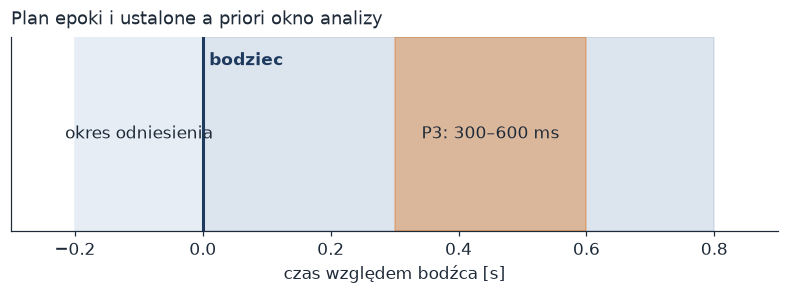

In [2]:
fig, ax = plt.subplots(figsize=(9, 2.3))
ax.axvspan(EPOCH_TMIN, 0, color=PALE, label="okres odniesienia")
ax.axvspan(0, EPOCH_TMAX, color=MIST, alpha=0.35)
ax.axvspan(P3_TMIN, P3_TMAX, color=ACCENT, alpha=0.4, label="okres P3")
ax.axvline(0, color=NAVY, lw=2)
for x, label in ((-0.1, "okres odniesienia"), (0.45, "P3: 300–600 ms")):
    ax.text(x, 0.5, label, ha="center", va="center", fontsize=11, color=INK)
ax.text(0.01, 0.92, "bodziec", color=NAVY, fontweight="bold", va="top")
ax.set(xlim=(-0.3, 0.9), ylim=(0, 1), xlabel="czas względem bodźca [s]")
ax.set_yticks([])
ax.set_title("Plan epoki i ustalone a priori okno analizy", loc="left", pad=8)
plt.show()


Wszystkie decyzje analityczne (okno P3, okres odniesienia) mamy ustalone *przed* oglądaniem wyników. To ważna zasada metodologiczna: dobór okna po obejrzeniu wyników może zawyżyć ocenę istotności statystycznej.

### Interpretacja osi czasu
Pionowa linia przy **0 ms** to moment prezentacji litery. Lewa część (−200–0 ms) jest okresem odniesienia, używanym do usunięcia przesunięcia napięcia sprzed bodźca. Odcinek **300–600 ms** to z góry określony obszar, w którym zostanie policzona średnia amplituda P3. Nie oznacza to, że inne procesy neuronalne w tym czasie przestają występować.

Wybieranie okna na podstawie największego obserwowanego efektu tej samej grupy może prowadzić do zbyt optymistycznych testów statystycznych. Najpierw definiujemy miarę, potem ją obliczamy; sam schemat nie jest jeszcze empirycznym wynikiem EEG.


### Narzędzia do animacji i zapisów pomocniczych
Poniższe funkcje są używane w dodatkowych demonstracjach. Pozwalają osadzić animację bezpośrednio w notatniku oraz, opcjonalnie, zapisać ją jako plik GIF w katalogu `output_P3/`.


In [3]:
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation, PillowWriter

def show_animation(anim, filename=None, fps=5):
    """Wyświetla animację w notatniku i opcjonalnie zapisuje ją jako GIF."""
    try:
        display(HTML(anim.to_jshtml()))
    except Exception as exc:
        print(f"Nie udało się osadzić animacji w notatniku: {exc}")
    if filename is not None:
        out_dir = Path("output_P3")
        out_dir.mkdir(parents=True, exist_ok=True)
        path = out_dir / filename
        try:
            anim.save(path, writer=PillowWriter(fps=fps))
            print(f"Zapisano animację: {path}")
        except Exception as exc:
            print(f"Nie udało się zapisać animacji {filename}: {exc}")
    return anim


## 1. Mapa pojęć: od sygnału EEG do wniosku psychologicznego
Na początku warto uporządkować podstawowe pojęcia. Dzięki temu łatwiej zrozumieć, **co jest surowym pomiarem**, **co jest jednostką analizy**, a **co jest już wynikiem psychologicznym lub statystycznym**.

Kod rysuje uproszczoną mapę pojęć używanych w notatniku.  
Powstaje schemat drogi od surowego EEG do wniosków na poziomie osoby i grupy.


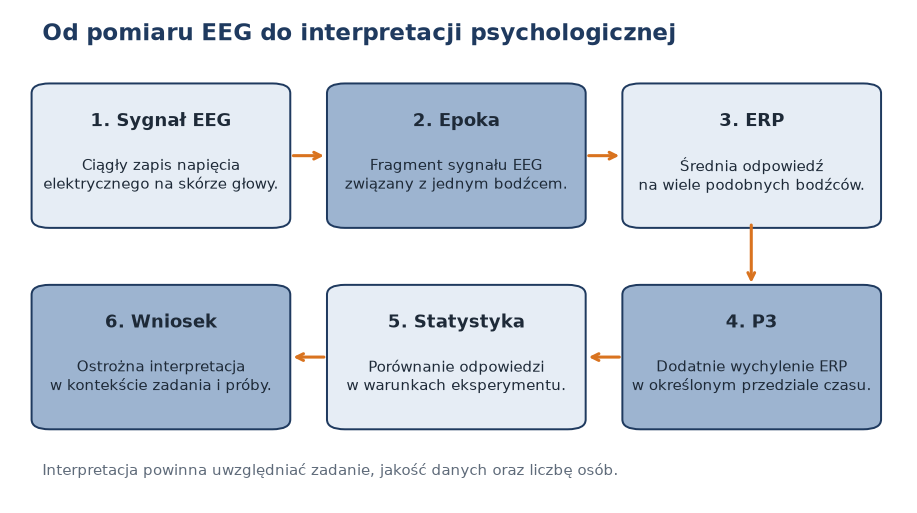

In [4]:
# Mapa pojęć w dwóch rzędach: czytelna również po zapisaniu na stronie A4.
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(10.5, 5.8))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

positions = [(0.035, 0.57), (0.365, 0.57), (0.695, 0.57),
             (0.695, 0.16), (0.365, 0.16), (0.035, 0.16)]
items = [
    ('1. Sygnał EEG', 'Ciągły zapis napięcia\nelektrycznego na skórze głowy.'),
    ('2. Epoka', 'Fragment sygnału EEG\nzwiązany z jednym bodźcem.'),
    ('3. ERP', 'Średnia odpowiedź\nna wiele podobnych bodźców.'),
    ('4. P3', 'Dodatnie wychylenie ERP\nw określonym przedziale czasu.'),
    ('5. Statystyka', 'Porównanie odpowiedzi\nw warunkach eksperymentu.'),
    ('6. Wniosek', 'Ostrożna interpretacja\nw kontekście zadania i próby.'),
]
for i, ((x, y), (title, body)) in enumerate(zip(positions, items)):
    patch = FancyBboxPatch((x,y), 0.265, 0.27, boxstyle='round,pad=0.012,rounding_size=0.02',
                           lw=1.3, edgecolor=NAVY, facecolor=PALE if i%2==0 else MIST)
    ax.add_patch(patch)
    ax.text(x+0.1325,y+0.205,title,ha='center',va='center',fontsize=12,weight='bold',color=INK)
    ax.text(x+0.1325,y+0.095,body,ha='center',va='center',fontsize=10,color=INK)
# Kierunek czytania: lewo -> prawo, następnie na dół i prawo -> lewo.
for a,b in ((0,1),(1,2),(3,4),(4,5)):
    x1,y1=positions[a]; x2,y2=positions[b]
    if a in (3,4):
        ax.annotate('',xy=(x2+0.277,y2+0.135),xytext=(x1-0.012,y1+0.135),
                    arrowprops=dict(arrowstyle='->',lw=2.0,color=ACCENT))
    else:
        ax.annotate('',xy=(x2-0.012,y2+0.135),xytext=(x1+0.277,y1+0.135),
                    arrowprops=dict(arrowstyle='->',lw=2.0,color=ACCENT))
ax.annotate('', xy=(0.827,0.44), xytext=(0.827,0.57),
            arrowprops=dict(arrowstyle='->',lw=2.0,color=ACCENT))
ax.text(0.035,0.94,'Od pomiaru EEG do interpretacji psychologicznej',fontsize=15,weight='bold',color=NAVY)
ax.text(0.035,0.055,'Interpretacja powinna uwzględniać zadanie, jakość danych oraz liczbę osób.',fontsize=10,color=GREY)
plt.show()


EEG to ciągły zapis, a **epoka** to tylko jego krótki wycinek związany z konkretnym bodźcem. **ERP** nie jest pojedynczym pomiarem, lecz **uśrednieniem** wielu podobnych epok. **P3** to jeden z elementów takiej średniej odpowiedzi, a nie odrębny „test uwagi”. Dopiero po statystycznym porównaniu wyników można przejść do **ostrożnego wniosku psychologicznego**. Każdy krok oddala nas od surowego sygnału i przybliża do interpretacji, ale zwiększa też ryzyko nadinterpretacji.


## 2. Przebieg analizy
Poniższy schemat pokazuje **kolejność działań**. W badaniach EEG kolejność ma znaczenie, ponieważ późniejsze wyniki zależą od wcześniejszych decyzji, takich jak filtracja, wybór epok lub korekcja artefaktów.

Kod rysuje drogę analizy od pobrania danych do oceny wyników.  
Powstaje schemat kolejnych etapów analizy.


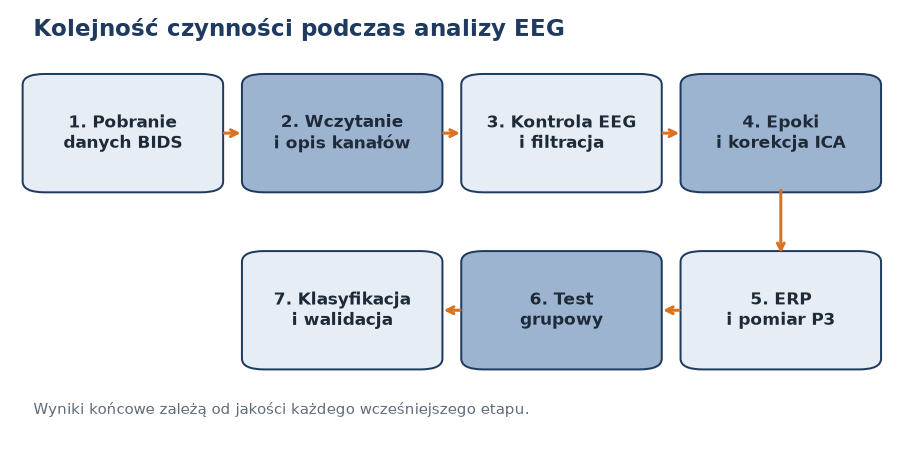

In [5]:
# Schemat procesu analizy w dwóch rzędach, zamiast siedmiu ciasnych pól.
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(10.5, 5.1))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
names = [
    '1. Pobranie\ndanych BIDS',
    '2. Wczytanie\ni opis kanałów',
    '3. Kontrola EEG\ni filtracja',
    '4. Epoki\ni korekcja ICA',
    '5. ERP\ni pomiar P3',
    '6. Test\ngrupowy',
    '7. Klasyfikacja\ni walidacja',
]
positions = [(0.025,0.59),(0.27,0.59),(0.515,0.59),(0.76,0.59),
             (0.76,0.18),(0.515,0.18),(0.27,0.18)]
for i, ((x,y), title) in enumerate(zip(positions,names)):
    ax.add_patch(FancyBboxPatch((x,y),0.20,0.25, boxstyle='round,pad=0.012,rounding_size=0.025',
                                facecolor=PALE if i%2==0 else MIST,edgecolor=NAVY,lw=1.3))
    ax.text(x+0.10,y+0.125,title,ha='center',va='center',fontsize=11,weight='bold')
for a,b in ((0,1),(1,2),(2,3)):
    x1,y1=positions[a]; x2,y2=positions[b]
    ax.annotate('', xy=(x2-0.01,y2+0.125),xytext=(x1+0.21,y1+0.125),
                arrowprops=dict(arrowstyle='->',color=ACCENT,lw=2))
ax.annotate('',xy=(0.86,0.43),xytext=(0.86,0.59),arrowprops=dict(arrowstyle='->',color=ACCENT,lw=2))
for a,b in ((4,5),(5,6)):
    x1,y1=positions[a]; x2,y2=positions[b]
    ax.annotate('',xy=(x2+0.21,y2+0.125),xytext=(x1-0.01,y1+0.125),
                arrowprops=dict(arrowstyle='->',color=ACCENT,lw=2))
ax.text(0.025,0.94,'Kolejność czynności podczas analizy EEG',fontsize=15,weight='bold',color=NAVY)
ax.text(0.025,0.065,'Wyniki końcowe zależą od jakości każdego wcześniejszego etapu.',fontsize=10,color=GREY)
plt.show()


Kontrola jakości pomiaru, przygotowanie sygnału, analiza ERP i ocena klasyfikatora stanowią kolejne etapy tej samej procedury. Nieprawidłowości we wcześniejszych etapach mogą obniżyć wiarygodność wszystkich późniejszych wyników.


## 3. Pobieranie danych z OSF
Poniższa komórka zawiera **skompresowany manifest** (adresy plików P3 na OSF i sumy kontrolne MD5; manifest pochodzi z pakietu *hu-neuro-pipeline*, licencja MIT, zbudowanego z listingu projektu OSF `etdkz`). Funkcja `download_p3` pobiera wybranych uczestników **i sprawdza sumy MD5**; pliki już obecne nie są pobierane ponownie.

Jeżeli serwer OSF jest niedostępny, dane zadania P3 można pobrać z https://osf.io/etdkz/ do katalogu wskazywanego przez `BIDS_ROOT` albo ustawić zmienną środowiskową `ERP_P3_BIDS_ROOT`. Zgodnie z dokumentacją `mne-bids-pipeline` dane udostępniono na licencji CC BY 4.0.

Kod udostępnia zaszyty w notatniku spis źródeł na OSF i sum MD5.  
Powstaje tekst manifestu zakodowany w Base64, rozpakowywany w następnej komórce.

Kod rozpakowuje manifest, pobiera i sprawdza integralność oryginalnych plików.  
W katalogu `data/ERP_CORE/P3` znajdują się pliki BIDS, a lista `SUBJECTS` zawiera identyfikatory uczestników. Integralność istniejących plików jest również sprawdzana.

### Dlaczego pochodzenie danych jest ważne?
W analizie psychologicznej trzeba móc wskazać, **kogo i w jakich warunkach mierzono**. Tutaj wykorzystujemy istniejącą bazę danych ERP CORE, a nie zapis z nowego eksperymentu. Suma MD5 potwierdza zgodność pobranego pliku z manifestem, lecz **nie potwierdza** dobrej jakości sygnału, poprawności odpowiedzi badanego ani trafności interpretacji psychologicznej. Statystyki uczestników i wyniki eksperymentalne są wyznaczane na podstawie faktycznie wczytanych danych.

Zbiór ERP CORE ma udokumentowane źródło i strukturę BIDS. Liczebność próby oraz kryteria wykluczenia wynikają z przebiegu analizy. Brak pobranych danych uniemożliwia przedstawienie wyników empirycznych.


In [6]:
MANIFEST_B64 = (
    "eNq9XduuZLdxfde3jDWsGy9+MxwhCZAYQfIBAi9FS7GsEeaMhSRfn+Lp3T3NfujeG9gcWLKOzhwB61QX11pFFouf9ZcP//j8y4ef8ttPH37Ln7/8XH/+Lf/65cef23f/+cOf/unff/j+y/98+fDTly+/vf3x48f+8y/69n3TP8D3n9769z9/+vg7fPysb5/+8bnq20f90v72fx9/+/zp95+bfn77aD/z9uXT5/xX/fjRA2rsvrGKqjhXEybyiT78vckfsbSWtUjRFHKpXlorLbeuJebUJHz47kt++9sf/oN+1N/11y9v3//326dfT0HlXAjdBY2uUXBRfZbQxL+jarVE8T4U7AISMWdyVAhEi1dX6MN3dxF7+/7L2++nQSo93yDVLLGzvEMKktA3Qq9ErtTQqfaIoBpD4s71AdKpYSr9a5iyYQqqF0zdU9VMOfUW7AOLLRjoFoWQm+v44buW7ePTLz82fauff/7ty8+ffj0bGpXswCUXM8YEVeEdWo2EjbvDxKkkcpIZs6/2460lFvfhu3/71z//8Jf/+uE8JFpvSDgmZFfekXiUDNGyPocALqQCvaeigZFEQ5AP3/35X/70l3/+4b9ORJKmFNJ+QYLBx1pK9hQxVclY2NalgyY1aa7xw3dv/yh/cA4+qv714/b1j7f1p38996Orzt8CFixgJV5gWoqlgCnmJplCC10plFJzcvYvBvTDhuwlWku8E8HG+dPldFkCUVrlaPibkRd3+0iVfPRFHDP0nWAv1HYmjVSXZ7yC73ilqXfiqzGcNNJkGdnJBQPL3hY27cP7i9Yvnz/Zoj4NMzjoNaCrPFYRetOC4twlxthEU7ScoNS676o5huCxoktVU+27MNdPnz63t/99+6J/Py+NL6j9DbWW2tBdIh0CZUtaRM229KtTQEnNkySXvfHp7jTu7cw0poc1597BQmyYjbVNY0xyoJse92Yhbj7n7rTsC/FP+ddf9Zez9bBOEp2NAAbiQj1wKIxYtKBryVjNg/jQu0Llx6TAO8S4FnF1NyEwHk7QUjmCGJ8iPj0hAGew+WI3LGsLla4mXtLNdmhj+zs7S4rgOvjdYM+VDDNjxrKQXcIK3HwIF7U3N4RV1Wg5aIhsoRXN0jLaz0XE3WhPlQz4KsPBZNj5y1rTCFi98ZgYqbEJsJFBTIIInRPEsg/sAsmAdsXbuq006heXVzJk1Uat9FY7A2buqSXngzdhzjtTYZVkxJl8wR2RjOeYF0pGrcFMjjd7Wgxgau6IZFxR0x1q+gaoo8yxxngENT1FvSo/ItwibfVk0+SP5McLzAvWINGN4BKw1VTtHW/mFNQseywQagkecov2h8G8vBXWUffhPZvgrK6/Z+MoF6ELrXB25u5N24qVFqbZpnc9uNwquBx2gV0jzeimQjb6cESaX4f3VGlGmaW5XNZbhpp6d776bt8qo9LosZdACAUrt91gz5Vmo7J7Z1k38z4KYTZWgNa4cDBlYYyknMiKJfLpAS3foeWlK41lToV6iW6zSAoHX1zwCbzhDPG9MCm25Oy/3PDyU7wLObjOfJbTEQ5+jnoZB6dZN+gQB7/AfDanWXZOBLztJ+XqeqyFsiW2Kpjz9BbpXJib2SDaB3YNp43thnvExR/htNfhPZXTzEVOLOEv+RuJRRh7iclbSKOPNXdz9G38RanuBnsup/GDXGyh9T0am3XfJLZUU7WUiYIpEAdnnP0YWrlDK8tXW3IEtozMJlq0o0stHllt8hTzmgS2LJ22qlo7ksDPEZ+ewKy3lEArkqRePE8i+5ZPIibAWMT+F9FqVY1VTeYS7AZ7bgILTNyQ4OJ3eiAj4qDYrZa3BcYYLKfB/hbKvfvdaE+lXuFptaXNQQhKVp9RWvFWmcYmWDyZHerR2Pm2H/wC7AIHIWHmsnaplxunmKP0oqnYD4Ka5TV+gxTYq8o+vOscROLZQVQ54iCuqP0dav8tUKcbak5NQ9EjqP1T1Ctyw8d54cmlwqfseHyrduyArXqkHDEa5GzE0Wkf3lXKEW4+rZWaMfUjyvEC89lk4eX+jCsBXNLYKBldqS6ahbcK2WwENFQqqWZKzPsSYo3MSZnpYjtE3Slzr8N7qsx5N5X21V3C60v0nitZ7Zm6VxDMPToNPRSq2ZfdYM+VOT+b9sTbarPaLZtZR4ognStQZROMWn0BMpv0gDbcoQ2Lk8HPx3OCh0x7eIr4/GToU+baqnsHyxEqidVF5jKjilX3pbuaoBboJZW8G+y5yRBwZga5GOCCIZmFJ0teNBmhhglVzK+bXPcc0m60p9JYkDm0cik3O0dLAQGHUsZpnP2cdxXty9Y5NNwHdoGuhTjxgjrYPE8xr8m5ODWoQBo4s0SLdzZxa20f3lW61m66lko18QpHdO055nWOJ8OtjmsULafLEcdzRR3vUMeFiy7yba/SPnEgz+9oXQ+piPm2Dpywo1kdBh+sdkpkpbNsaONTtAtjnB4yox6J8XPUq7I5yy0vIoVeezuSzS8wL2CMmGalC1uLXRPzwMZmlhje7LwV01A8K0Tk7AH34T1b6SLOR7ZbcKv3Q0g8Y8+eXSyg3ArH0UnFFvN9abzESIQyW59wyEi8Du+pahfDDaw3sObVL7lgqWu1f/Ees48+cg6uWWLX4lhcfVxv6Q5sWpq76WtwyfASXtIhBsil0mhZzcyUbe21BsaBVmEE1uv2SXqKdyGr6bzfHvsRVnuBekkSxzpbtnpoB/A54tM5IuG9BTIHdJE6s5Cd0nvLTPElZAQqEZwPrRWXKO0Ge64wp6+HiD4mp3yROFe4m3cfO1MxWLFnZhOx1veu627gd6M9lR9SnPkhXeq4XlrKkk3PwDROXbA0qELRnJ3lSy77wK7S4/lEriMc0eMNM7ivmMEtx1xw9pblyE4PuOeYF/BwbpMsA/YtL8Y1gRxZW8HMxmXmNQy+I0opXJtZX+E9O4nz1MA/zr8vZNZiB2MMMt41F1wbOKOKJiLVp1RxF9h1olFkTmPKB0RjR4hPpeBMsy5vGxJZIYy2doNvv5BpYEvqfFZ2OUIv+8CuUbjUZtHo7oDC7QjvuaKR5858+9C3SxWVuglJia00RzD2V5tRMkZh37k8oL3rEoa1ze6lTSY402W3skhEqMVoopJ5S3bUfKCGWc2y5b5VnwBP8S5ccnVm4Xakn+4F6mXKkabORbPBR5TjBeazmbjkOS3wcucs5/6eDxZMbb4hdgqCZuA7ixbIu8Geu+hKnHUjXI4/OUkKasmQQw/ItgRjjJbRyYwlxmuhvAPtqQxc/OzUtg5WywhTaDcOO8h5aEVTsn+odh97dmXfilvCwFazT+GVdISBr4jvOoVh9T2C+rX7hLKE0PEIYnyK+PSEqDLdw9PNBltZoQGr9kA1M3V1JJm9q8pQvYTdYM9da1ZpTAZC2taaTylAS6FS7aYWsSeIUgoOQ2Sx3Y32VBqrZc7crVMxWpnGaByWutSxJaHVm9qxZQLUtDcPFqhx1XnH73r9UME+/64pRA6BzY8JYTIazsAmxrgP7yJdqzB1TWXMR3TtOeZ1DqLyjJqOdIPeUN91CMO3uEdgS2van9IjHShAT1Evy48yX02UI1X+K8wL1mDrE2cQXrSDOkRfzC5XhmBOjpmxmhuqITmuSffhPZvgWp0av/LWla/qjIy5kigzjF4On4iipUyuHajtBnuudrQ0lXIifKDRfQfaU2W5zb2V5sUuoTUJHh0cvsRcBKIJXMiWBCKphyL78naN62kwJwMfuT15Q3zXIQyrG7CVp2rZjMMRxPwU8ekJofM1jQ7blIJ38uU6utDsn8DDB4F55m4FvxTeDfbctabztomvF1k2e+mNACoYz3bjXd+5ZrVUtjWnuewP7ak0ZrGc1tp2FOfHLerCQGZynNWYRM4JhhhMLJo22Qd2gUb0+X6Rxe+yq+qsFE7Y2KGhNq1LlggWaMmilsBuH95FOtx42jPph+6SvMC8zvG0OKPmI/c9b6jvOoXhW3QKq5tR+0M+TZ6iXpDPzYW5BN36V4M0ydGROSErQUyjxwGjcbaZihjjtQvwFd6TyaJ9HX6SioENG7P1NMbCxHGkPNLXW7lsyw+NMLLLY27NLrCrFl+djDvBoWOj1wE+Vej618upMEp83QZOgYCPyJbdNabanCsq6guWsVOc8i6wa3xEn41lKIecz+vwnirNzcFsJLauOichd/Pto/ErWOlfJZCOk4JEPhZND2jvOoRhcQN2c2XW53JoB9A/RXx2+ra7uRzv/NC24UiQQ1EycY6xQAISsjXX1Eq5Qk78brDnJgM8WOB66W3v3mqiNka/hYrIOaWe+xgm0cj+/dr+twPtqdQLc5eBT1tXjwhC8wLJCrjG0dsfKHWXpatYVbIP7AJdgzIz2bafFl0kdEyOsYWATN1+F2eZyz6xwM5UWCQVyvN9nX7kFuILzAsdT5puwBAfGeV0Q33XKQzfolO4uynWcevJ3ok6PEW9Ip/xtj+caNwNT1s/dqxZQEQCO8IQFFICqE6qGVCzG/vwnk0WON3aIQebaDifK+XgJBqnEWcMLuUesv1U8J73gV21+B4a3jMeWXyvA3yq0CFPh7Ql0DaRjC05pJZgahJg6J7az9QQ0bza7ez+Odg1PgLm8w2v8YiPeB3ec6UZ41wVte2MoCQpvvlsGZ6yYGmZzMSB6+aT2rWl+Yb2rkEYvkVnfn9g4m1LeCenxaeoV3Aaz3N7ynYXuJs90xYBRzZLzK76Sj6bHYIwWmn24T2b06hPCRzoksCEBj6bSzPjYz9TpUKuSqBWlApg3Qd2Eaf1h6Ou65y6fZz2OsCnchr56eQ+Xg/DjY+RffcawujvKG78UdXSnRCUtgvsGk4jN+8F1kOc9jq853IazZP1QC+c5sZJOcloS4tkvw5b4nIRjwway604uqK96xOGb9CX35ybZbnwEU5Lz1EvyQqeW5JYjszefIH49EXHfe7p0Ivr4RyLuUdbYEJkFIzoa20BkJNTf2tJeg323BQWmH1l9ke6vV6jPVUwxE9ncmU72WAenqIl50SLdJ+dVqqljwFapRXYB3aBGkuedtJ0W2nVnBvVpFRdjVqqoJThd8Yxo5LUfXhXCVybG7DLkVuqV8x41yGMS3vym5/v7PA2LdRDLJ2hcNGsDKJjzHRlHzA3HiNQN2zP8Z6+3Pw8wb6kI82VO9CeutzuhgMMy95Rt77VpGxopYbRXlALQiOmMdM+pOr6LrBrhELqzGb1yNbqq/CuWXDNPRwl9iPTxnekxKni5ukhJdw1JXKnaAWbipcyAsy2Alm5jqHNsC8l1jmeMHNaO3KH/Yb6rksY13WLt9Dmqmhrx/dJ0ErQCs5bJTQMvSs+eKn2SbDHK1h4CfbUfAg87WEHviichvcZJ76n9wIDJBUJ2YJtBVzzRXeDPZd9Q5ynA2wns4XGoQyqoc4NyLyxVR5WMkPrYF/LLrRrCM3fTg/B4jv2no4Q2ov4LlDjOHdNlW0sndV1SAJRPRcrgPIYgmK5a4Q35rpfK6JXeFcR8MPNyX5km/JVVqzjtH6PWp07UsXdUN91CuM36BRuEGbU21WYnajxKepV+QE87wHWI70+rzAvWIMpTXuAtV5Yrlpp6kOD8dZKieyjZ3ANuuMxu551H96z1S7JDHYbqFeNGIo59tIAszlipxiCC30035Fw3A32VLWLbXY/IW6P2bC2nCIEVmdVB1kWgAQLcLcvW9oFdo1+xDBVRyJH9tN2hPdcfU63aW+WpWxUsJ3BMCC2XKSEPG4j9d7JxXFAbksTbvp8RXvXJYxLu9vH2PP7cgO3jttaqeacIXVhsxUj+AJixFCb1VTXuRxIT/Eu5GCd+awdmcvxAvUyDi73RRI5PnIv5hXmszmtPBRJ+SLNLAbLmd3Q2sdB8vi1stVLaHkN1e8L8BqaSHPdDNupxk6aeB3eU1k4z/2Vo1nukgslpzHRNHVOyXJATefUCtKSx7WusBvsuZyW23Si0bc74ZG8q0AxEGDIPebic29NCudIlPAB7V2nMC6+R9BKmeNb4Egy8FPEpydDhelZrusgd1Ci9xfxcFxo9+pNNKIluQmGVazKu8GemwyVJzn2cH1qUFIVo17vDGtuqiBmhVCMzNrtlasdaE+lsRoma9Y4bnd2qoD9BgW5plyspgZwSkDd8qMUtw/sAjWuac7bepkJEL1xrQtg6RDRBJmHiQw0GhfVR6B9eBfpGsJ8Ftf4iK49x7zOQSBPs//MZR5xEFfUdx3CKOsjHWYH4Q9ts8pTzAsjXWfU4ZBXe476dMJo/f64q0e8sJv5nwJjTvaYfGJUB6Z8olyM/ahSpn1gFxCGwox3G8VApUsbHYFYnKVDjFbb5SiuZKs/rQjZHdxTha49uJ6ra0dTkR6jRPPx3FGclcpWc+TEIdXc9uXvEh9R5+u01R+5j7gjvOdKc8uzT9tGMex7ouKG9q5TGFffI9CHvXftR+LrnyI+PX113pRq+XJwxGg2hyGOG8sY1Iy6VfQ+g5kNonLtX90B9txk0DoxQyI64tNeoz2VdvX2FEwLWfx1/zr6ChbNVl1KkrIf74KXDsCxxZzcTrALaLfDdI+AN15wkLqpXVMz6Za0KOORqxS5FVeEq+7Du8g90PyaUcEj86ZeYF7nHmi+/RD5yGslN9R3HcIYvgXqMs32qnjkliqGp6gX5LO6h13AnrcbaN6cRI4diaLa2kxeLfkF2bLEY9+H92SyUDe/V+L7xboDNPCJkrJZzGpMYrSXRmMo++xa3BncVYsvzia4Hhl6siPApwpd1znA7cIUAvYrVCaLccxiGuetGK1JMFu+wLX97wXYNT6iy5y/x/Z7Xof3VGlWd+twhzGwaTxz9y7NJOMGkqUqUmlsOt1QzGZAV1t3tT6gvesQxm9wj6Axzeee4ciEJIxPUa/gNJjn9gSh7R5BHOeF5FwrkmuMYIswQbQ1OiavpX14z+a0uwfDdTwYvj1wLmDfG29c9c6+RKcxdyWnDiyfLUP2gV3EaeweRO7IHfYdAT6T0xT8nA10CbAXn+zDj5bD9v+Y6zhebuO9ZRO+ivuydwmnjUv19+WGuiNzbneE91xOg6lPeAw4uIxyCj3VxD5Q8FZBV6vxe6yxW/3p2F8fc7yhvesTxsUd+Yrzg47Khw6M0lPEp6cvTlsn6LaN7OF2xpNsZoKglDIKfFPlJmwy4sbUnL1gz00GzNO2Sduet0/mJdmQSuZoVbP5CF/H4581AXhm3I32VOrFaTBS1y20EgOLz5HHhQLHuaMO1siJ+jgb3RnaBbqG8xalbi/tSE4wqngKPRe1pE09QKFYHfZ0e4bgFd5VUuHnKk70iFQ8x7zQ8eSpy4APzRq6oqa7TmFaeo9AeRodQVQuuyi5gJV34wENCplYO4q5CKFmvwfIddmRe453VWb02UQcyoxXmM+mCsaprzltVIFmIn0ASeOmBpKxBvRc1SLekxfYB3ZdGgvPIT50ALMjxKcKHdWHEG+F8rifUSRFF53VIebOmuU0uVSUyF8nT70K8RIfQTjtYcdwZLb0jvCeK81377C/++DthXAKMJ4XQ4elEnbOrY/WO6njYV31+oD2rlOYFvePmx7Ppxq5HokvPEV8evqy3omzWI25PbuDibJxF2euozmJiZP34yk/VWNk2A323GSQ+X3PCLBtu5tTSxIKNkBLb8kCqYQSxEEMLu1Geyr5isymcnuLC2MQzNJd8cNWcuvJqmeRmlstxeE+sAvUWOYbv3F7WcW78YQudG5NxtwCtLJeCpmtdOOULuzDu0iNJU1j6cQdGQ3wAvNCgZs7DACO9HLcUN91CNO3uEfg5zEM5dDbcoRPUa/I5+CmerlvIwtbQCUvVVvH2jVlyNQu0zlqxQ778J5NFn5+5soqzcviI7aUNWLWURVpMNDd1ma3TwKF/U6wixafd/PiwyOXNHYE+FShu3s0/j3AW/+UZYc4X+J4wlF6cY0rJDXhQzeOSfdl7xofMT8aT9SPXKzdEd5zpdnnyUhgvzCxlBai16iNlUuChA29QZYo3WSxPqC96xCmb9GX79t8RqBHbnQRPUW9gtMiT1GW7QFK6pXtu5xDcYCuRqxBxo5791LA5314z+a0iBNY1ou3pMxqhByD19rMAJF5NfNCY1B+sHTGfWBXcVqaE6IeOSPYEeBTOS3Mzw3GbdbF2D+LoTmrhpwY2MA1YwD7T4z3zObtAruG08LDhsShSw87wnsup4U+J/D17rJPA7tZ+jzedQwBCMdEEe3JDEQPD2jvOoVp8T0CqzdnfvBH7p4RP0V8evrG+djerPxFkiUimjP2rTUedwmqD4beZyol5ex2gz03GdLMZn6bBhlTGmuM5f1pcOOP1JiCOUyM5jQb70Z7KvWmueXEsvVyS06MwjBH4hKby6HVXDDG7DoaQ+jOPFigaynNeLddNCisYL6XEXDcKWmtsjSCFtV5vM7lfYV3kVQEnKu4radup1Q8x7zO8QR+QH2oiruivusQpm/Rkx++VszBVlc61MtB8hT1svxI07tRcKw8eoH5bMLIs30Pm303l26xrkpF2JVmyqHkvNWhXbuMjppdYBcQRp4b3XXrP1HLBwb2FlXTOLWsIR0P5bXx8pyP+4N7qtDlec7t9XJq7UrNXJsbPo6KthDsj1NzJVkleu2+fQF2jY94uJzKx2rP1+E9V5rz/KCG1ZuXZKipegzM5tTG+WHq3XkvCtKcfRT5Ae1dpzCt726OMG+epCMz38g/x7xgwZU2K3SVbcoMjcfDwFKEx/j/8c5yFGTvSuWgdR/es9mslOmGanN9e+kqj5eXazZLUcT70RWKqeTeJdUY3S6w60QuzueeDQ9tRrwO8amcVuYhIn17YyV1tYTF5E0cNAgOw+EyJlMLDqOA2hXiJZyW+7wD2NsRTnsd3nM5rYTplPZ6dL+v5/aG9q5DmBb3NOvXa+GXltDoj8Q3PEV8evpWf5++1W3P3LeWsjfjEJORF48tKS099kLj/jVe+1d3gD03Gb6+WXxpwG55G7iJIUclFKs+kZP9HpygFArd1EV1N9pTybfO00FTv+RBNTfGLRDZZ25+vpViRNGhRtKeA5R9YBco29c3i80kJvtiw+uao8hODLhKBgiE2Ztomw82j7kzuKvcQ7xJhRmFhulQbfEc80KBq3NFxIcE7or6rkOY1jeNJzdjliPTAig+x7wgm+8uWL/rxnZKS4li44rjlXB1Rmy1+dZj1lah8K2Qe453XWaMubH3bvjYOcyLKJ9NcK1Pvc2mZdubxePQBX0JNG5nmJkrULobrGccksO+EC+R5oeHdbUeavl6Hd5TpfnrrfvRP4Vue7fYeNmL89VJG6OpzB51TMqGu0fvbmdcr8GeK80tz8nA23RpGhciLLYcS/etiDQ/TpXNvHUzSo+hvesUptX3CJSmrZ7qj8w3pfQU8enJoPMRV97GzwejLltj1YIPVsyH9E5ogMn4oZpb2g323GTQOrvKsF3+dSGOSR3mIdMgB2eswGMTrfdSLI13oz2VxnR+Cia3S2itzh830YCx2V/diLmUapihWRZELfvALlC2Pp8d5k0jHBVwVsqbJ8p1vKTZXDIaLog5ObxO9n+Fd5V7CPM9gu1dz53u4TnmhWo8T/6DbQLyTjXeUPNdhzAvbMDu805wx3ZNCwk56Igr5xABSg4SfMncSMIWYnZPwa4h4O7nRO5HGoRfID6f03qf40sX70ARqEvibPZmXNRILmRnoWYkS+LrI2070J7Jad3RFNrrzIgSQYuLlHpQMFY2u5DH+bNgrMn3vA/s+ZzWH0YD5G0WWc++p3Ftq1KvjrrVnlKl9+xsTWKnfXhXcVqf+kCrO3Lu+WrBLeO0PJ/Wojvyormh/n/QdCyP"
)


In [7]:
# Manifest zawiera względną ścieżkę BIDS, URL, MD5 oraz identyfikator sub-XXX.
MANIFEST = pd.read_csv(
    io.StringIO(zlib.decompress(base64.b64decode(MANIFEST_B64)).decode("utf-8")),
    dtype={"participant_id": str},
)

def download_p3(participants, root, manifest=MANIFEST):
    """Pobiera P3 dla N osób. Pooch sprawdza MD5, również dla plików z cache."""
    root = Path(root)
    ids = sorted(manifest["participant_id"].dropna().unique())
    if not 1 <= participants <= len(ids):
        raise ValueError(f"N_PARTICIPANTS musi mieścić się w zakresie 1..{len(ids)}")
    rows = manifest[
        manifest["participant_id"].isna() | manifest["participant_id"].isin(ids[:participants])
    ]
    for _, row in rows.iterrows():
        dest = root / row["rel"]
        dest.parent.mkdir(parents=True, exist_ok=True)
        try:
            pooch.retrieve(url=row["url"], known_hash=row["hash"],
                           fname=dest.name, path=dest.parent,
                           progressbar=str(row["rel"]).endswith((".fdt", ".set")))
        except Exception as exc:
            raise RuntimeError(
                f"Pobranie lub kontrola MD5 nie powiodły się dla {row['rel']}. "
                f"Sprawdź OSF i połączenie albo umieść gotowy zbiór BIDS w {root}."
            ) from exc
    return root

# Własny katalog BIDS nie jest automatycznie modyfikowany ani pobierany z OSF.
if not os.environ.get("ERP_P3_BIDS_ROOT"):
    download_p3(N_PARTICIPANTS, BIDS_ROOT)

# Liczymy wyłącznie osoby z kompletną parą plików EEGLAB i tabelą zdarzeń.
def has_p3_files(participant_dir):
    eeg = participant_dir / "eeg"
    return (any(eeg.glob("*_task-P3_eeg.set"))
            and any(eeg.glob("*_task-P3_eeg.fdt"))
            and any(eeg.glob("*_task-P3_events.tsv")))

SUBJECTS = sorted(p.name.removeprefix("sub-") for p in BIDS_ROOT.glob("sub-*")
                  if p.is_dir() and has_p3_files(p))[:N_PARTICIPANTS]
if len(SUBJECTS) != N_PARTICIPANTS:
    raise FileNotFoundError(
        f"Żądano {N_PARTICIPANTS} osób, wykryto {len(SUBJECTS)} kompletnych zapisów P3 "
        f"w {BIDS_ROOT}. Wskaż poprawny ERP_P3_BIDS_ROOT lub pobierz brakujące pliki."
    )
print("Katalog BIDS:", BIDS_ROOT.resolve())
print("Uczestnicy:", SUBJECTS)
print("Pliki oryginalne pozostają niezmienione; przetwarzanie działa na kopiach w pamięci.")


Katalog BIDS: C:\Users\matpo\repo\app-eeg-mne\notebook\data\ERP_CORE\P3
Uczestnicy: ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010', '011', '012', '013', '014', '015', '016', '017', '018', '019', '020', '021', '022', '023', '024', '025', '026', '027', '028', '029', '030']
Pliki oryginalne pozostają niezmienione; przetwarzanie działa na kopiach w pamięci.


Podczas pobierania wyświetlany jest pasek postępu, a następnie lista identyfikatorów uczestników (`['001', '002', ...]`). Dane jednej osoby zajmują około 55 MB.

Przy ponownym pobieraniu poprawne pliki są pomijane, a uszkodzone identyfikowane na podstawie sum MD5.

### Co oznacza lista uczestników?
Identyfikatory `001`, `002` itd. oznaczają osobne **osoby**, a nie pomiary powtarzane tej samej osoby. Zwiększenie ich liczby poszerza podstawę uogólniania na inne osoby, jednak nawet pełne 40 osób z ERP CORE nie stanowi losowej próby całej populacji. Błąd pobierania czy brak pliku nie świadczy o niespełnieniu kryteriów psychologicznych przez daną osobę.

Liczba wczytanych uczestników oraz liczba osób z wystarczającą liczbą poprawnych epok w obu warunkach określają zakres możliwych analiz.


## 4. **Struktura BIDS**
BIDS [3] porządkuje pliki według konwencji: katalog uczestnika, podkatalog `eeg`, plik z sygnałem (`*_eeg.set` + `*.fdt`), plik zdarzeń (`*_events.tsv`), opis kanałów (`*_channels.tsv`) itd. MNE-BIDS [4] wczytuje to wszystko do obiektu `Raw`.

Kod odczytuje nazwy plików i tabelę zdarzeń pierwszego uczestnika.  
Powstaje ramka `events_tsv` z metadanymi zdarzeń. Wyświetlane są przykładowe wiersze i liczebności poszczególnych etykiet.

### Tłumaczenie struktury plików
Plik **EEG** zawiera serię pomiarów elektrycznych w czasie. Plik **zdarzeń** (*events*) opisuje, **kiedy** zaprezentowano bodziec i **jaki** był jego typ. Dopiero połączenie obu informacji pozwala zestawić reakcję mózgową z konkretnym zdarzeniem psychologicznym. BIDS to konwencja organizacji danych, a nie osobna metoda statystyczna.

Etykieta „bodziec docelowy” w pliku zdarzeń oznacza kategorię bodźca w programie eksperymentalnym; nie oznacza automatycznie, że uczestnik zauważył literę lub odpowiedział prawidłowo.


In [8]:
sub = SUBJECTS[0]
for p in sorted((BIDS_ROOT / f"sub-{sub}").rglob("*")):
    if p.is_file():
        print(f"{str(p.relative_to(BIDS_ROOT)):70s} {p.stat().st_size / 1e6:8.2f} MB")
ev_file = next((BIDS_ROOT / f"sub-{sub}").rglob("*_task-P3_events.tsv"))
events_tsv = pd.read_csv(ev_file, sep="\t")
print("Kolumny tabeli zdarzeń:", list(events_tsv.columns))
display(events_tsv.head(8))
if "trial_type" not in events_tsv:
    raise KeyError("Brak 'trial_type' w events.tsv; sprawdź konwencję tego zbioru BIDS.")
print("Liczebności kategorii zdarzeń: \n", events_tsv["trial_type"].value_counts().head(12))


sub-001\eeg\sub-001_task-P3_channels.tsv                                   0.00 MB
sub-001\eeg\sub-001_task-P3_coordsystem.json                               0.00 MB
sub-001\eeg\sub-001_task-P3_eeg.fdt                                       63.12 MB
sub-001\eeg\sub-001_task-P3_eeg.json                                       0.00 MB
sub-001\eeg\sub-001_task-P3_eeg.set                                        3.96 MB
sub-001\eeg\sub-001_task-P3_electrodes.tsv                                 0.00 MB
sub-001\eeg\sub-001_task-P3_events.tsv                                     0.01 MB
Kolumny tabeli zdarzeń: ['onset', 'duration', 'sample', 'trial_type', 'stim_file', 'value']


,onset,duration,sample,trial_type,stim_file,value
0,9.6211,0.0,9853,response,NaN,202
1,15.1250,0.0,15489,response,NaN,202
2,19.4121,0.2,19879,stimulus,NaN,11
3,19.8926,0.0,20371,response,NaN,201
4,20.8623,0.2,21364,stimulus,NaN,12
5,21.3164,0.0,21829,response,NaN,201
6,22.3779,0.2,22916,stimulus,NaN,14
7,22.7969,0.0,23345,response,NaN,201


Liczebności kategorii zdarzeń: 
 trial_type
response    202
stimulus    200
Name: count, dtype: int64


W `events.tsv` kolumna `trial_type` zawiera opisy zdarzeń (np. `stimulus/11`, `response/201`).

To z nich zbudujemy etykiety celów i niecelów.

### Co można, a czego nie można wywnioskować ze znaczników?
`stimulus/...` opisuje moment i kategorię prezentacji bodźca, a `response/...` może dotyczyć odpowiedzi uczestnika. W tym notatniku klasyfikujemy EEG według **typu prezentowanej litery**, nie według rzeczywiście poprawnych odpowiedzi. Aby badać kontrolę poznawczą, błędy lub szybkość podejmowania decyzji, potrzebna byłaby osobna analiza danych behawioralnych i ich synchronizacja z EEG.


### BIDS: standard organizacji danych i dokumentowania eksperymentu

**BIDS** (*Brain Imaging Data Structure*) to zestaw reguł określających nazewnictwo katalogów i plików, sposób zapisywania zdarzeń oraz metadanych. Nie jest nowym formatem sygnału. Zapis EEG może pozostać w jednym z dopuszczalnych formatów, np. **EEGLAB** (`.set` oraz, jeśli dotyczy, `.fdt`), **BrainVision** (`.vhdr`, `.vmrk`, `.eeg`) lub **EDF** (`.edf`). BIDS pozwala oprogramowaniu odnaleźć dane i powiązać je z opisem zadania bez ręcznego zgadywania nazw plików.

```text
erp-core-p3/
├── dataset_description.json             # nazwa, autorzy i typ zbioru
├── participants.tsv                     # tabela uczestników
├── participants.json                    # opis kolumn (jeżeli występuje)
└── sub-001/
    └── eeg/
        ├── sub-001_task-P3_eeg.set       # właściwy zapis EEG
        ├── sub-001_task-P3_eeg.fdt       # dane towarzyszące plikowi .set (jeśli są)
        ├── sub-001_task-P3_eeg.json      # np. częstość próbkowania, układ odniesienia
        ├── sub-001_task-P3_channels.tsv  # nazwa, typ i stan kanału
        ├── sub-001_task-P3_events.tsv    # chwila i rodzaj zdarzenia
        ├── sub-001_task-P3_events.json   # znaczenie kolumn (jeżeli występuje)
        ├── sub-001_task-P3_electrodes.tsv  # położenie elektrod (jeżeli podano)
        └── sub-001_task-P3_coordsystem.json # układ współrzędnych (jeżeli podano)
```

Powyższe drzewo jest **schematem możliwej struktury**, a nie wykazem plików, które muszą występować w ERP CORE. Obowiązkowość poszczególnych plików zależy od danych i specyfikacji EEG-BIDS. Jeśli dostępny jest `electrodes.tsv`, należy również podać opis układu współrzędnych w `coordsystem.json`.

| Składnik | Co przechowuje | Dlaczego jest ważny |
|---|---|---|
| `*_eeg.set` / `*.fdt` | Sygnał zarejestrowany w czasie | Podstawa dalszego przetwarzania |
| `*_eeg.json` | Parametry rejestracji, np. `SamplingFrequency`, `EEGReference` | Umożliwia poprawną interpretację czasu, jednostek i odniesienia |
| `*_channels.tsv` | Nazwy kanałów, typ (`EEG`, `EOG`), stan (`good`, `bad`) | Pozwala rozróżnić sygnały i wykryć problematyczne kanały |
| `*_events.tsv` | `onset`, `duration`, `trial_type`, opcjonalnie odpowiedź lub czas reakcji | Wiąże fragment EEG z bodźcem i zachowaniem |
| `*_electrodes.tsv` i `*_coordsystem.json` | Położenia elektrod i układ współrzędnych | Potrzebne do interpretacji map topograficznych |
| `participants.tsv` | Dane opisowe uczestników, o ile są udostępnione | Pozwala określić charakterystykę próby |

**`onset` jest czasem w sekundach od początku nagrania**, a nie numerem próbki. Jeżeli bodziec pojawił się po 12,5 s, przy próbkowaniu 256 Hz odpowiada to około 3200 próbek. Należy uwzględniać początek nagrania, przesunięcia i sposób oznaczania zdarzeń przez oprogramowanie. `trial_type` opisuje kategorię zdarzenia, a nie jego automatyczną interpretację poznawczą.

*Elektroda* jest punktem kontaktu ze skórą, natomiast *kanał* opisuje tor pomiaru różnicy potencjałów. Liczba kanałów nie musi odpowiadać liczbie fizycznych elektrod (np. kanały EOG rejestrowane dwubiegunowo).

Szczegółowe informacje znajdują się w [specyfikacji EEG-BIDS](https://bids-specification.readthedocs.io/en/stable/modality-specific-files/electroencephalography.html) i w [dokumentacji MNE-BIDS](https://mne.tools/mne-bids/stable/).

### Odczyt BIDS: surowy sygnał, zdarzenia i metadane

`BIDSPath` nie otwiera pliku. Tworzy **jednoznaczny opis jego położenia** na podstawie jednostek BIDS (`subject`, `task`, `session`, `run`, `datatype`). `read_raw_bids()` wykorzystuje ten opis, wczytuje sygnał do `mne.io.Raw` i odczytuje dostępne metadane. Dzięki temu można użyć tej samej funkcji dla różnych dopuszczalnych formatów EEG.

```python
from pathlib import Path
from mne_bids import BIDSPath, read_raw_bids
import pandas as pd

root = Path('data/ERP_CORE/P3')
bids_path = BIDSPath(subject='001', task='P3', datatype='eeg',
                     suffix='eeg', root=root)
raw_bids = read_raw_bids(bids_path, verbose='warning')
print(raw_bids.info['sfreq'])  # próbek na sekundę
print(raw_bids.ch_names)       # nazwy wszystkich kanałów

# BIDS udostępnia zdarzenia jako osobną tabelę TSV.
events_path = bids_path.copy().update(suffix='events', extension='.tsv')
events_table = pd.read_csv(events_path.fpath, sep='\t')
print(events_table[['onset', 'duration', 'trial_type']].head())
```

Kod powyżej jest **przykładem dokumentacyjnym**. Właściwe wczytywanie w tym notatniku znajduje się w następnych komórkach. Parametr `preload=True` lub wywołanie `raw.load_data()` przenosi próbki do pamięci RAM. Przetwarzanie bez uprzedniego wczytania danych bywa oszczędniejsze, lecz nie każda operacja może pracować bezpośrednio z plikiem na dysku.

`Raw` reprezentuje zapis ciągły, `Epochs` — fragmenty wokół zdarzeń, a `Evoked` — wynik uśrednienia epok. Żaden z tych obiektów nie jest sam w sobie „standardem BIDS”.

### Zapis nowego eksperymentu zgodnie z BIDS

Do utworzenia nowego zbioru EEG służy `write_raw_bids()` z pakietu `mne-bids`. Funkcja zapisuje sygnał w obsługiwanym formacie i przygotowuje powiązane pliki opisowe. Poniższy przykład jest **wzorcem dla nowego eksperymentu**, a nie poleceniem modyfikowania pobranych danych ERP CORE.

```python
from pathlib import Path
import mne
from mne_bids import BIDSPath, write_raw_bids

# Przykład: pomiar zapisany wcześniej przez wzmacniacz BrainVision.
raw_example = mne.io.read_raw_brainvision('moj_pomiar.vhdr', preload=False)
raw_example.set_channel_types({'VEOG': 'eog'})  # tylko jeśli taki kanał istnieje

bids_path_new = BIDSPath(subject='001', session='01', task='oddball',
                         datatype='eeg', root=Path('moj_zbior_BIDS'))
write_raw_bids(raw_example, bids_path_new,
               format='BrainVision', overwrite=False)

# W praktyce trzeba zachować także znaczniki zdarzeń i ich opis,
# a także opis aparatury, układu odniesienia, uczestników i rozmieszczenia elektrod.
```

Jeżeli sygnał został już wczytany do pamięci (`preload=True`), zapis przez `write_raw_bids()` może wymagać `allow_preload=True` i jawnego `format='BrainVision'`. Przy konwersji do BrainVision mogą być potrzebne dodatkowe biblioteki eksportu. Dane źródłowe warto zachować bez zmian. **Przetworzone wyniki** zapisuje się osobno, zazwyczaj w katalogu `derivatives/`, z opisem zastosowanych metod; zapis pochodny nie zastępuje surowego nagrania.

**Kiedy używać zwykłego `raw.save()`?** Plik MNE-FIF (`.fif`) jest wygodny do zachowania obiektu roboczego i dalszej analizy, ale samo polecenie `raw.save()` **nie tworzy kompletnego zbioru BIDS**. Podobnie `DataFrame.to_csv()` zapisuje tabelę, lecz nie dodaje wymaganych informacji o eksperymencie ani jednostkach. Standard BIDS obejmuje zarówno dane, jak i ich opis.

## 5. Wczytanie danych jednego uczestnika
Najpierw przejdziemy cały tor dla **jednej osoby** (kroki 5–19), a następnie zamkniemy go w funkcji i zastosujemy do wszystkich (krok 20). `BIDSPath` wskazuje plik po uczestniku i zadaniu, `read_raw_bids` wczytuje sygnał wraz z nazwami kanałów i informacjami o zdarzeniach.

Kod ładuje zapis EEG do obiektu MNE Raw i weryfikuje wymagane kanały.  
W pamięci dostępne są obiekt `raw` (kanały × próbki) i słownik `CH`. Oryginalne pliki `.set` i `.fdt` pozostają niezmienione.

### Logika analizy jednej osoby
Pierwszą osobę traktujemy jako **przykład pokazujący mechanizm**, a nie jako reprezentanta całej grupy. Obserwacja dodatniej P3 u jednej osoby może być zgodna z hipotezą, lecz test różnic indywidualnych wymaga odpowiedniego planu analizy na poziomie osób. Później te same operacje zostaną zastosowane do wszystkich uczestników. Dzięki temu nie dobieramy osobnych filtrów, progów czy okien tylko po to, aby u poszczególnych osób otrzymać oczekiwaną odpowiedź.


In [9]:
SUB = SUBJECTS[0]
bp = BIDSPath(subject=SUB, task="P3", datatype="eeg", suffix="eeg", root=BIDS_ROOT)
raw = read_raw_bids(bp, verbose="error")
raw.load_data()
CH = {c.lower(): c for c in raw.ch_names}
print("Częstotliwość próbkowania:", raw.info["sfreq"], "Hz")
print("Czas zapisu:", round(raw.times[-1] / 60, 1), "min")
print(f"Kanały ({len(raw.ch_names)}):", raw.ch_names)
required = {"heog_left", "heog_right", "veog_lower", "fp2", "p9", "p10", "pz", "fz", "cz", "oz"}
missing = sorted(required - CH.keys())
if missing:
    raise ValueError(f"Brak kanałów: {missing}. Nazwy w danych: {raw.ch_names}")


Częstotliwość próbkowania: 1024.0 Hz
Czas zapisu: 7.8 min
Kanały (33): ['FP1', 'F3', 'F7', 'FC3', 'C3', 'C5', 'P3', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Oz', 'Pz', 'CPz', 'FP2', 'Fz', 'F4', 'F8', 'FC4', 'FCz', 'Cz', 'C4', 'C6', 'P4', 'P8', 'P10', 'PO8', 'PO4', 'O2', 'HEOG_left', 'HEOG_right', 'VEOG_lower']


Wyświetlane są pierwotna częstotliwość próbkowania, czas trwania rejestracji oraz lista kanałów EEG i kanałów okoruchowych (`HEOG_left`, `HEOG_right`, `VEOG_lower`). Częstotliwość próbkowania zostanie zmniejszona po filtracji.
MNE przechowuje EEG w **woltach** (np. `8e-05 V` = 80 µV). Do wykresów mnożymy przez 10⁶.

### Jak wyobrazić sobie surowy zapis EEG?
EEG to ciągły szereg czasowy, a nie gotowy wykres „uwagi”. **Częstotliwość próbkowania** (Hz) podaje, ile pomiarów wykonano w ciągu sekundy; np. 128 Hz oznacza 128 punktów na sekundę. Większa częstość próbkowania zwiększa rozdzielczość czasową zapisu, ale nie zastępuje dobrej jakości elektrod ani poprawnie przeprowadzonego zadania.

Czy występują oczekiwane elektrody i kanały EOG, czy zapis nie jest zbyt krótki oraz czy parametry techniczne są zgodne z planem analizy. Na tym etapie nie ma jeszcze wyniku dotyczącego P3.


## 6. Kanały okoruchowe (EOG)
Z trzech surowych kanałów tworzymy dwa sygnały **dwubiegunowe**: HEOG = lewy − prawy (ruchy poziome oczu), VEOG = dolny − FP2 (mrugnięcia). Surowe kanały usuwamy, a nowe oznaczamy jako EOG. Dzięki temu ICA (krok 15) może szukać składowych skorelowanych z **rzeczywistym** ruchem oczu, a nie tylko wyglądających na artefakt.

Kod oblicza różnicowe HEOG/VEOG, klasyfikuje je jako EOG i usuwa pomocnicze elektrody.  
W obiekcie `raw` dostępne są dwa kanały EOG obok kanałów EEG. `FP2` pozostaje kanałem EEG.

### Dlaczego mrugnięcia zniekształcają zapis EEG?
Mrugnięcie generuje silne napięcie, które może być widoczne na elektrodach czołowych i imitować zmianę ERP. Jeśli warunki różnią się częstością mrugania lub ruchów oczu, różnica EEG może być częściowo **artefaktem zachowania**, a nie wskaźnikiem przetwarzania celu. Dwa kanały bipolarne EOG pomagają zidentyfikować taką zanieczyszczenie. **HEOG** służy do rejestracji poziomych ruchów oczu, a **VEOG** — pionowych ruchów oczu i mrugania.

Nie interpretuj wielkości EOG jako poziomu uwagi. EOG jest w tym ćwiczeniu przede wszystkim informacją pomocniczą do kontroli jakości sygnału.


In [10]:
def prepare_eog_channels(r):
    """Tworzy HEOG i VEOG z różnic elektrod; zachowuje FP2 jako kanał EEG."""
    names = {c.lower(): c for c in r.ch_names}
    needed = {"heog_left", "heog_right", "veog_lower", "fp2"}
    if not needed.issubset(names):
        raise ValueError(f"Brak kanałów EOG: {sorted(needed - names.keys())}")
    for anode, cathode, new_name in (
        (names["heog_left"], names["heog_right"], "HEOG"),
        (names["veog_lower"], names["fp2"], "VEOG"),
    ):
        mne.set_bipolar_reference(r, anode, cathode, ch_name=new_name,
                                drop_refs=False, copy=False)
    r.set_channel_types({"HEOG": "eog", "VEOG": "eog"})
    r.drop_channels([names["heog_left"], names["heog_right"], names["veog_lower"]])
    return r

raw = prepare_eog_channels(raw)
CH = {c.lower(): c for c in raw.ch_names}
print("EEG:", raw.get_channel_types().count("eeg"),
      "| EOG:", raw.get_channel_types().count("eog"))
print("Sygnały EOG są pomocnicze przy ICA i nie są cechami klasyfikatora.")


EEG: 30 | EOG: 2
Sygnały EOG są pomocnicze przy ICA i nie są cechami klasyfikatora.


Po przetworzeniu sygnału dostępnych jest 30 kanałów EEG i dwa kanały EOG. Elektroda `FP2` jest wykorzystywana zarówno w kanale EEG, jak i do utworzenia VEOG; jej zapis EEG zostaje zachowany i może pomóc w ocenie artefaktów mrugania.

### Co oznaczają dwa dodatkowe kanały?
Wynik nie zwiększa liczby niezależnych „obszarów mózgu”. HEOG i VEOG to pochodne pomiary różnic napięcia wokół oczu. Pozwalają sprawdzić, czy wybrana składowa ICA rzeczywiście przypomina ruch oka. Jeśli brakuje kanału, dalsza automatyczna korekcja może być mniej wiarygodna; w raporcie warto zaznaczyć sposób postępowania z EOG.


## 7. Elektrody i montaż
Montaż `standard_1005` nadaje elektrodom pozycje 3D (potrzebne do map topograficznych). Dopasowanie ignoruje wielkość liter (w zbiorze występują nazwy typu `FP1`), a kanały EOG nie mają pozycji i są pomijane. Na mapie zaznaczono **Pz** (klasyczne miejsce pomiaru P3) oraz **P9, P10** (odniesienie).

Kod wstawia standardowe współrzędne elektrod 10-05 i pokazuje ich rozkład.  
Do obiektu `raw` przypisano montaż standardowy i utworzono schemat topograficzny. Nie są to współrzędne zmierzone na głowie uczestnika.

### Elektroda na głowie to nie lokalizacja funkcji psychicznej
Nazwy Fz, Cz i Pz oznaczają położenia czujników. **Ciemieniowa przewaga P3b** jest opisem rozkładu napięć na skórze głowy, nie dowodem, że tylko kora ciemieniowa odpowiada za rozpoznanie celu. Napięcie mierzone na elektrodzie zależy od rozległych źródeł neuronalnych, przewodnictwa tkanek oraz zastosowanej odniesienia. Montaż umożliwia **rysowanie map**, ale nie zastępuje rekonstrukcji źródeł mózgowych.


Użyty montaż: colin27_1005


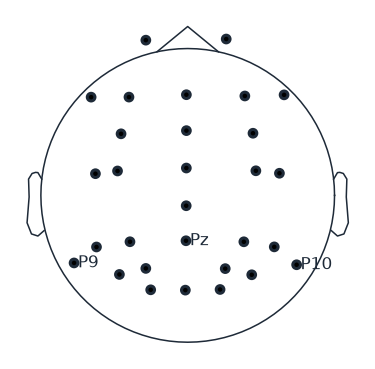

Wyróżnione etykiety: Pz, P9, P10


In [11]:
# MNE <= 1.12: standard_1005; od MNE 1.13: colin27_1005.
montage_name = ("colin27_1005"
                if "colin27_1005" in mne.channels.get_builtin_montages()
                else "standard_1005")
raw.set_montage(montage_name, match_case=False, on_missing="warn")
print("Użyty montaż:", montage_name)
fig, ax = plt.subplots(figsize=(4.4, 4.1))
labels = [CH[c] for c in ("pz", "p9", "p10")]
mne.viz.plot_sensors(raw.info, kind="topomap", show_names=labels,
                     axes=ax, show=True, title="")
ax.set_title("Rozmieszczenie elektrod (standardowy montaż 10-05)")
plt.show()
print("Wyróżnione etykiety:", ", ".join(labels))


To montaż standardowy, nie zmierzone pozycje elektrod danej osoby; mapy topograficzne są więc przybliżone.

### Co właściwie pokazuje mapa topograficzna?
Mapa odpowiada na pytanie: **na których elektrodach odpowiedź była dodatniejsza lub ujemniejsza?** Nie odpowiada wprost na pytanie: **który obszar anatomiczny wytworzył efekt?** Wnioski o sieciach neuronalnych wymagają dodatkowego modelowania i innych danych. W opisie wyników trafniej pisać „efekt o przewadze ciemieniowej” niż „aktywacja płata ciemieniowego”.


---

# CZĘŚĆ II. **Przetwarzanie wstępne**

## 8. Surowy sygnał EEG
Zawsze zaczynamy od **inspekcji**. Rysujemy dziesięciosekundowy odcinek sygnału z wybranych kanałów środkowych, potylicznego oraz VEOG.

Kod pokazuje dziesięć sekund sygnału EEG/EOG po wyrównaniu pionowym śladów.  
Powstaje wykres pięciu kanałów i liczbowe oszacowanie rozstępu VEOG. Przesunięcia na wykresie nie zmieniają próbek.

### Dlaczego oglądamy zapis przed obliczeniem ERP?
Średnia nie naprawia systematycznie złego pomiaru. Nawet gdy później uzyskamy dodatnią falę 300–600 ms, najpierw trzeba wykluczyć proste wyjaśnienia techniczne: dryf elektrod, przerwy sygnału, nasycenie wzmacniacza, zakłócenia i silne mrugnięcia. Inspekcja surowego sygnału jest **kontrolą wiarygodności pomiaru**, a nie analizą hipotezy P3.


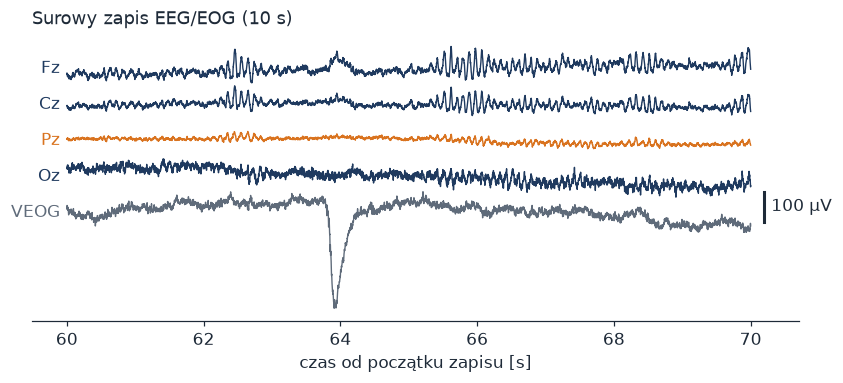

Rozstęp VEOG w oknie: 388.3 µV


In [12]:
t0 = min(60.0, max(0.0, raw.times[-1] - 10.1))
seg = raw.copy().crop(t0, min(t0 + 10, raw.times[-1]))
chs = [CH[c] for c in ("fz", "cz", "pz", "oz")] + ["VEOG"]
data = seg.get_data(picks=chs, units=dict(eeg="uV", eog="uV"))
times_seg = seg.times + t0
fig, ax = plt.subplots(figsize=(9, 3.4))
step = 120  # odstęp linii na wykresie [µV], nie operacja na danych EEG
for i, (channel, trace) in enumerate(zip(chs, data)):
    color = ACCENT if channel == CH["pz"] else (GREY if channel == "VEOG" else NAVY)
    ax.plot(times_seg, trace - trace.mean() - i * step, color=color, lw=0.9)
    ax.text(times_seg[0] - 0.1, -i * step, channel,
            ha="right", va="center", color=color)
ax.plot([times_seg[-1] + 0.2] * 2, [-4 * step - 30, -4 * step + 70],
        color=INK, lw=2, clip_on=False)
ax.text(times_seg[-1] + 0.3, -4 * step + 20, "100 µV", va="center", clip_on=False)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("czas od początku zapisu [s]")
ax.set_title("Surowy zapis EEG/EOG (10 s)", loc="left")
plt.show()
print(f"Rozstęp VEOG w oknie: {np.ptp(data[-1]):.1f} µV")


Mrugnięcia to duże, wolne wychylenia w **VEOG**, które przenikają do kanałów czołowych (i słabiej do Pz). Rozstęp sygnału VEOG można porównać z wahaniami amplitudy EEG, aby wskazać fragmenty zawierające prawdopodobne mrugnięcia. Surowego sygnału nie analizujemy bez kontroli.

### Jak interpretować 10-sekundowy fragment?
Na osi poziomej jest czas, a na pionowej amplituda sygnału. Krótkie duże wychylenie współwystępujące w EEG i EOG sugeruje wpływ oka; bardzo wolna zmiana podstawy zapisu może być dryfem. **Nie każde duże wychylenie jest oznaką silniejszego przetwarzania informacji.** Krótkie okno ma pokazać charakter sygnału, ale nie dowodzi, że cały wielominutowy zapis jest wolny od artefaktów.


## 8a. Orientacyjny układ elektrod na powierzchni głowy
W analizie P3 szczególnie ważna jest elektroda **Pz**, położona nad częścią ciemieniową. Poniższy szkic nie zastępuje rzeczywistego montażu, ale pomaga zrozumieć, **gdzie na głowie znajdują się najczęściej przywoływane punkty odniesienia**.

Kod rysuje uproszczony schemat położenia wybranych elektrod.  
Powstaje orientacyjny schemat głowy z zaznaczonymi elektrodami Fz, Cz, Pz, Oz, P9, P10 i kanałami EOG.


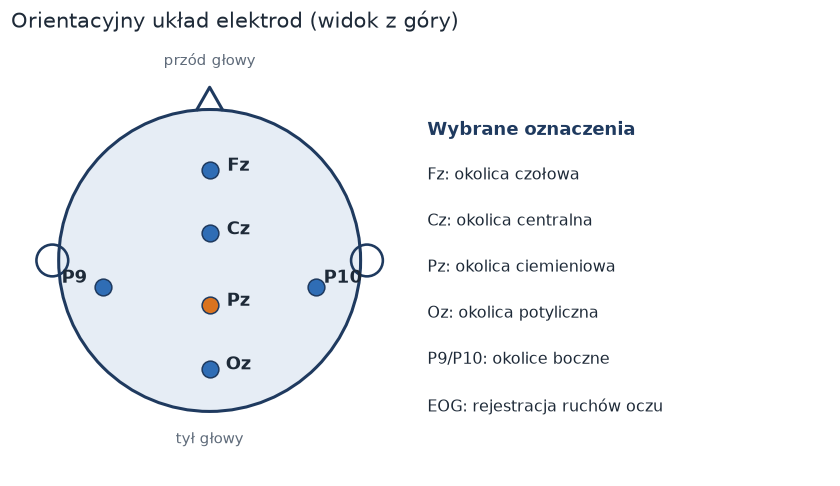

In [13]:
# Uproszczony schemat rozmieszczenia elektrod: widok z góry.
# Pomiary EOG objaśniono w legendzie, bez sugerowania ich lokalizacji na skórze głowy.
from matplotlib.patches import Circle
fig, ax = plt.subplots(figsize=(9.6, 5.3))
ax.set_aspect('equal'); ax.axis('off')
ax.add_patch(Circle((0,0), 0.95, facecolor=PALE, edgecolor=NAVY, lw=2))
ax.plot([-0.08,0,0.08],[0.95,1.09,0.95],color=NAVY,lw=2)
ax.add_patch(Circle((-0.99,0),0.10,fill=False,edgecolor=NAVY,lw=1.7))
ax.add_patch(Circle((0.99,0),0.10,fill=False,edgecolor=NAVY,lw=1.7))
electrodes=[('Fz',0,0.57),('Cz',0,0.17),('Pz',0,-0.28),('Oz',0,-0.68),
            ('P9',-0.67,-0.17),('P10',0.67,-0.17)]
for label,x,y in electrodes:
    col=ACCENT if label=='Pz' else STEEL
    ax.scatter([x],[y],s=120,color=col,edgecolor=NAVY,zorder=5)
    dx,dy = (-0.18,0.06) if label=='P9' else ((0.17,0.06) if label=='P10' else (0.18,0.025))
    ax.text(x+dx,y+dy,label,fontsize=12,weight='bold',ha='center',va='center',color=INK)
ax.text(0,1.23,'przód głowy',ha='center',fontsize=10,color=GREY)
ax.text(0,-1.15,'tył głowy',ha='center',fontsize=10,color=GREY)
ax.text(1.37,0.79,'Wybrane oznaczenia',fontsize=12,weight='bold',color=NAVY)
for y,txt in [(0.51,'Fz: okolica czołowa'),(0.22,'Cz: okolica centralna'),
              (-0.07,'Pz: okolica ciemieniowa'),(-0.36,'Oz: okolica potyliczna'),
              (-0.65,'P9/P10: okolice boczne')]:
    ax.text(1.37,y,txt,fontsize=10.5,color=INK)
ax.text(1.37,-0.95,'EOG: rejestracja ruchów oczu',fontsize=10.5,color=INK)
ax.set_xlim(-1.25,3.9); ax.set_ylim(-1.35,1.35)
ax.set_title('Orientacyjny układ elektrod (widok z góry)',loc='left',fontsize=14,pad=12)
plt.show()


Elektrody oznaczone literą **P** leżą nad okolicą ciemieniową, a **Pz** znajduje się w linii środkowej. W klasycznych zadaniach z rzadkim bodźcem docelowym to właśnie w tej okolicy często obserwuje się wyraźniejszą składową P3. Kanały **VEOG** i **HEOG** nie służą do wnioskowania o procesach poznawczych, lecz pomagają wykrywać artefakty związane z mruganiem i ruchami oczu.


## 9. Znaczniki zdarzeń
Adnotacje to etykiety wstawione przez system stymulacji. Zliczamy kody bodźców i oddzielamy **cele** (kody `11, 22, 33, 44, 55`, czyli obie cyfry równe) od bodźców niedocelowych.

Kod rozpoznaje dozwolone dwucyfrowe kody P3 i liczy rozkład celów/niecelów.  
Dostępne są słowniki `stim` i `ignored`, liczniki `n_t` i `n_n` oraz wykres liczebności zdarzeń.

### „Cel” nie znaczy „poprawna reakcja”
Klasy `target` i `nontarget` określają **kategorię litery w danym bloku eksperymentalnym**. W opisie eksperymentu rozróżniamy co najmniej trzy zjawiska: (1) obiektywne pojawienie się celu, (2) jego świadome lub nieświadome przetworzenie, (3) odpowiedź behawioralną. Notatnik bezpośrednio koduje **punkt (1)** i analizuje związane z nim EEG. Punktów (2) i (3) nie wolno wyprowadzać z samej etykiety bodźca.

Liczba celów powinna być znacznie mniejsza niż niecelów, bo w paradygmacie bodźca rzadkiego (oddball) to rzadki bodziec ma przyciągać uwagę. Warto sprawdzić, czy kodowanie odpowiada dokumentacji zadania.


Kody bodźców: 25 | liczba bodźców: 200
Pozostałe adnotacje (pomijane): {'response/202': 7, 'response/201': 195}


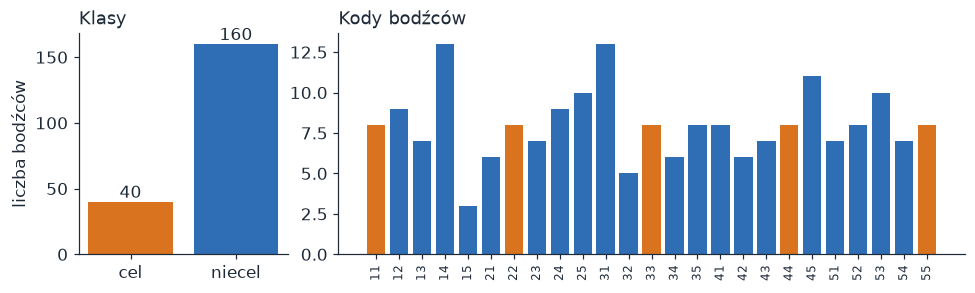

In [14]:
# Tylko dwucyfrowe kody bodźców w zadaniu P3 mają etykiety klas.
STIM_RE = re.compile(r"^stimulus/[1-5]{2}$")
TARGET_RE = re.compile(r"^stimulus/([1-5])\1$")
def is_target(description):
    return bool(TARGET_RE.fullmatch(description))

counts = Counter(raw.annotations.description)
stim = {k: v for k, v in counts.items() if STIM_RE.fullmatch(k)}
ignored = {k: v for k, v in counts.items() if k not in stim}
if not stim or not any(is_target(k) for k in stim):
    raise ValueError(f"Brak rozpoznawalnych kodów P3: {sorted(counts)}")
print(f"Kody bodźców: {len(stim)} | liczba bodźców: {sum(stim.values())}")
print("Pozostałe adnotacje (pomijane):", ignored)
n_t = sum(v for k, v in stim.items() if is_target(k))
n_n = sum(v for k, v in stim.items() if not is_target(k))
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8),
                         gridspec_kw=dict(width_ratios=[1, 3]))
axes[0].bar(["cel", "niecel"], [n_t, n_n], color=[TGT, NTG])
for i, value in enumerate((n_t, n_n)):
    axes[0].text(i, value, str(value), ha="center", va="bottom")
axes[0].set_ylabel("liczba bodźców")
axes[0].set_title("Klasy", loc="left")
ks = sorted(stim)
axes[1].bar(range(len(ks)), [stim[k] for k in ks],
            color=[TGT if is_target(k) else NTG for k in ks])
axes[1].set_xticks(range(len(ks)), [k.split("/")[1] for k in ks], rotation=90, fontsize=8)
axes[1].set_title("Kody bodźców", loc="left")
plt.tight_layout()
plt.show()


Cele są **rzadkie** (istota zadania z bodźcem rzadkim), więc klasy są niezrównoważone. Wróci to przy klasyfikacji: użyjemy ważenia klas i metryk odpornych na nierównowagę (AUC, trafność zrównoważona) [11]. *Znacznik oznacza pojawienie się bodźca, a nie dowód, że osoba wykonała zadanie.*

### Z punktu widzenia wnioskowania
Nierówna liczba prób w dwóch warunkach wpływa na **precyzję średniej ERP**: mniej celów zwykle oznacza większy szum w ich średniej. Wysoka skuteczność klasyfikacji większościowej nie świadczy o odczytywaniu P3. Ważne jest oddzielenie **liczebności prób** od **siły efektu neurofizjologicznego**.


## 10. Widmo mocy
Oszacowanie widmowej gęstości mocy metodą Welcha [7] dla Pz służy **kontroli jakości**: pozwala zauważyć szum sieciowy, dryf i rytm alfa (8–13 Hz).

Kod szacuje metodą Welcha widmową gęstość mocy kanału Pz.  
Powstają wektor częstotliwości, oszacowanie PSD w µV²/Hz i informacja o lokalnym maksimum w paśmie 8–13 Hz.

### Czym jest widmo mocy?
Widmowa gęstość mocy pokazuje, jak moc sygnału EEG rozkłada się w zależności od częstotliwości w wybranym kanale. Nie analizuje jeszcze odpowiedzi na konkretną literę. Pełni to funkcję kontroli technicznej: pomaga rozpoznać zakłócenia i rytmiczne właściwości sygnału, które mogą utrudniać pomiar ERP.


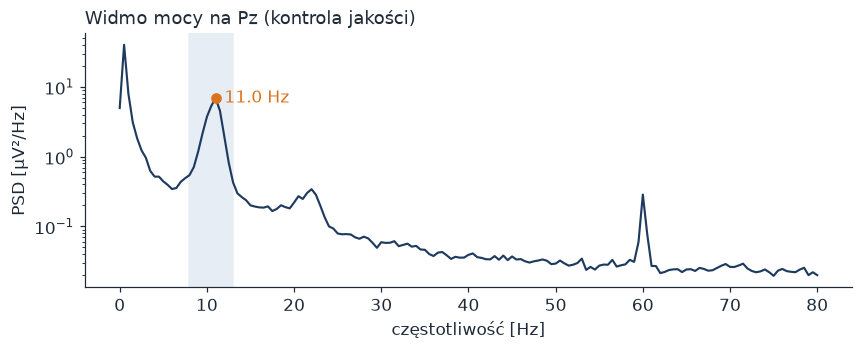

Częstotliwość lokalnego maksimum 8–13 Hz: 11.0 Hz


In [15]:
# fmax ograniczamy do częstotliwości Nyquista; n_fft do liczby dostępnych próbek.
fmax = min(80.0, raw.info["sfreq"] / 2 - 0.1)
spec = raw.compute_psd(method="welch", fmax=fmax,
                       n_fft=min(2048, raw.n_times), picks="eeg")
f = spec.freqs
psd = spec.get_data(picks=[CH["pz"]])[0] * 1e12  # V²/Hz -> µV²/Hz
mask_alpha = (f >= 8) & (f <= 13)
fa = float(f[mask_alpha][np.argmax(psd[mask_alpha])]) if mask_alpha.any() else np.nan
fig, ax = plt.subplots(figsize=(9, 3))
ax.axvspan(8, 13, color=PALE)
ax.semilogy(f, psd, color=NAVY, lw=1.4)
if np.isfinite(fa):
    j = int(np.argmin(abs(f - fa)))
    ax.plot([fa], [psd[j]], "o", color=ACCENT)
    ax.text(fa + 1, psd[j], f"{fa:.1f} Hz", color=ACCENT, va="center")
ax.set(xlabel="częstotliwość [Hz]", ylabel="PSD [µV²/Hz]")
ax.set_title("Widmo mocy na Pz (kontrola jakości)", loc="left")
plt.show()
print("Częstotliwość lokalnego maksimum 8–13 Hz:", round(fa, 1), "Hz")


W wielu zapisach EEG moc zmniejsza się wraz ze wzrostem częstotliwości; niekiedy widoczny jest szczyt w paśmie alfa. Ewentualny szczyt **50/60 Hz** wskazuje na zakłócenia sieciowe, a duża moc poniżej 1 Hz może wskazywać na dryf. P3 jest zjawiskiem wolnym (poniżej ok. 30 Hz), więc alfa zaznaczono tylko dla orientacji.

### Interpretacja i ostrożność
Szczyt w paśmie **8–13 Hz** może być związany z rytmem alfa, lecz jego wielkość sama w sobie nie mówi, czy osoba „bardziej się skupiała”. Alfa zależy np. od warunków wzrokowych i pobudzenia; tutaj widmo służy przede wszystkim do oceny jakości. Wąski szczyt przy 50 Hz może wskazywać na zakłócenia sieciowe, a silna energia najniższych częstotliwości na dryf. **Wykres widma nie jest dowodem obecności ani braku P3**; dotyczy innej własności sygnału.


## 11. Zmiana odniesienia EEG na średnią P9/P10
W EEG rejestruje się **różnicę potencjałów względem wybranego punktu lub układu odniesienia**. Używamy uśrednionych P9 i P10, jak w konfiguracji ERP CORE. Po tej operacji suma P9 + P10 jest równa zeru, więc oba kanały są **lustrzanymi odbiciami** [6].

Kod przelicza kanały EEG względem średniej P9/P10 i kontroluje wynik.  
W pamięci dostępny jest sygnał EEG po zmianie odniesienia oraz porównanie kanałów. Surowe pliki nie są nadpisywane.

### Co znaczy „odniesienie” w EEG?
EEG mierzy **różnicę potencjału**, nigdy absolutny potencjał neuronu. Wybór średniej P9 i P10 jako odniesienia zmienia wartości na wszystkich analizowanych elektrodach. Dlatego amplitud P3 z różnych publikacji nie należy porównywać bez sprawdzenia odniesienia i pozostałych parametrów przygotowania sygnału.

„P3 wyniosła 5 µV” nie jest kompletnym wynikiem. Konieczne są: kanał (tu Pz), przedział (300–600 ms), sposób odniesienia i definicja warunku.


Kontrola referencji (P9 + P10 ≈ 0): True


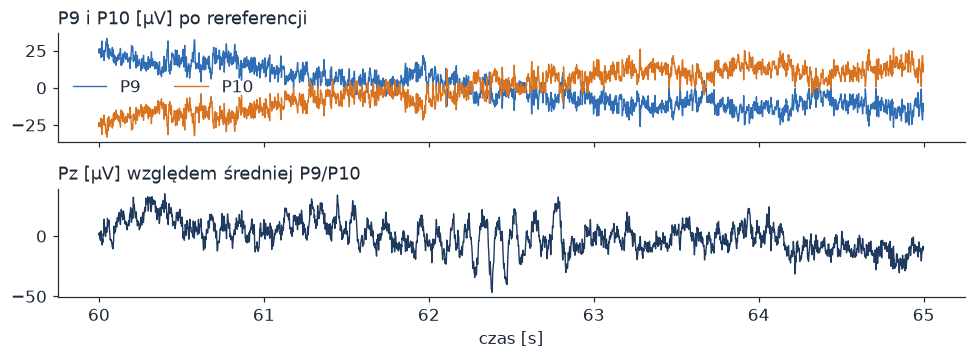

In [16]:
raw.set_eeg_reference([CH["p9"], CH["p10"]])
ref_idx = [raw.ch_names.index(CH[c]) for c in ("p9", "p10")]
ref_data = raw.get_data(picks=ref_idx)
print("Kontrola referencji (P9 + P10 ≈ 0):",
      np.allclose(ref_data[0] + ref_data[1], 0, atol=1e-12))
fs = raw.info["sfreq"]
t_start = min(60.0, max(0.0, raw.times[-1] - 5.1))
i0, i1 = int(t_start * fs), min(int((t_start + 5) * fs), raw.n_times)
tt = np.arange(i0, i1) / fs
fig, axes = plt.subplots(2, 1, figsize=(9, 3.4), sharex=True)
for key, color in (("p9", STEEL), ("p10", ACCENT)):
    signal = raw.get_data(picks=[CH[key]])[0, i0:i1] * 1e6
    axes[0].plot(tt, signal - signal.mean(), color=color,
                 lw=0.9, label=CH[key])
axes[0].legend(ncol=2, frameon=False)
axes[0].set_title("P9 i P10 [µV] po rereferencji", loc="left")
pz_signal = raw.get_data(picks=[CH["pz"]])[0, i0:i1] * 1e6
axes[1].plot(tt, pz_signal - pz_signal.mean(), color=NAVY, lw=0.9)
axes[1].set_title("Pz [µV] względem średniej P9/P10", loc="left")
axes[1].set_xlabel("czas [s]")
plt.tight_layout(); plt.show()


P9 i P10 mają przeciwne znaki, ponieważ po odjęciu ich średniej uzyskuje się wartości przeciwne. Zmiana odniesienia zmienia topografię i amplitudy, więc wyniki przy różnych układach odniesienia nie są wprost porównywalne.

### Czy ujemny potencjał oznacza hamowanie?
Nie. Znak napięcia w EEG jest **względny** i zależy od przyjętego układu odniesienia oraz orientacji źródeł elektrycznych. Ujemny punkt na wykresie nie jest automatycznie „dezaktywacją mózgu” ani świadectwem hamowania poznawczego. Dla interpretacji P3b ważniejsza jest dobrze zdefiniowana **różnica między warunkami** w tej samej konfiguracji pomiaru.


## 12. Filtracja i próbkowanie
Tworzymy dwie kopie: **0,1–30 Hz** do analizy ERP oraz **1–30 Hz** do ICA (ICA działa lepiej bez wolnego dryfu). Łagodny filtr górnoprzepustowy 0,1 Hz lepiej zachowuje wolnozmienną składową P3; zbyt silny filtr mógłby zniekształcić ERP [8]. Po filtracji dolnoprzepustowej po ograniczeniu pasma sygnału zmniejszamy częstość próbkowania do 128 Hz.

Kod tworzy dwie kopie sygnału po filtracji pasmowej: 0,1–30 Hz do analizy ERP i 1–30 Hz do ICA, a następnie zmienia częstość próbkowania na 128 Hz.  
W pamięci dostępne są obiekty `raw_erp` i `raw_ica` oraz wykres porównawczy. Filtracja może zmienić fazę i amplitudę sygnału.

### Co filtry robią z sygnałem?
Filtr przepuszcza określony zakres częstości, a tłumi pozostałe. Filtracja ułatwia wyodrębnienie wolniejszych zmian charakterystycznych dla ERP i ogranicza zakłócenia. Nie jest jednak neutralna: może zmieniać kształt i czas przebiegu oraz wprowadzać zniekształcenia, szczególnie przy źle dobranych granicach pasma. Osobna kopia do ICA służy lepszemu rozpoznaniu artefaktów, a **nie** do obliczania finalnej amplitudy P3.

Wynikiem filtracji są sygnały EEG o ograniczonym paśmie częstotliwości. Nie jest to pomiar „czystszej uwagi” ani oszacowanie procesów psychicznych.


Częstość próbkowania: 128.0 Hz | filtracja ERP: 0.1 – 30.0 Hz


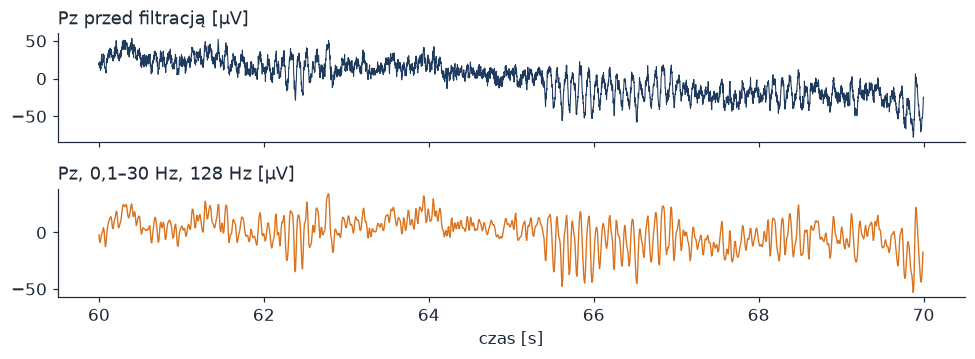

In [17]:
raw_erp = raw.copy().filter(0.1, 30.0, fir_design="firwin")
raw_ica = raw.copy().filter(1.0, 30.0, fir_design="firwin")
for recording in (raw_erp, raw_ica):
    recording.resample(SFREQ_OUT)
print("Częstość próbkowania:", raw_erp.info["sfreq"], "Hz",
      "| filtracja ERP:", raw_erp.info["highpass"], "–", raw_erp.info["lowpass"], "Hz")
fs_orig = raw.info["sfreq"]
t_start = min(60.0, max(0.0, raw.times[-1] - 10.1))
y0 = raw.get_data(picks=[CH["pz"]])[0,
    int(t_start * fs_orig):int((t_start + 10) * fs_orig)] * 1e6
y1 = raw_erp.get_data(picks=[CH["pz"]])[0,
    int(t_start * SFREQ_OUT):int((t_start + 10) * SFREQ_OUT)] * 1e6
fig, axes = plt.subplots(2, 1, figsize=(9, 3.4), sharex=True)
axes[0].plot(np.arange(len(y0)) / fs_orig + t_start,
             y0 - y0.mean(), color=NAVY, lw=0.7)
axes[0].set_title("Pz przed filtracją [µV]", loc="left")
axes[1].plot(np.arange(len(y1)) / SFREQ_OUT + t_start,
             y1 - y1.mean(), color=ACCENT, lw=0.9)
axes[1].set_title("Pz, 0,1–30 Hz, 128 Hz [µV]", loc="left")
axes[1].set_xlabel("czas [s]")
plt.tight_layout(); plt.show()


Filtracja może osłabić powolny dryf i szybkie zakłócenia, ale **nie usuwa selektywnie wszystkich artefaktów**, np. mrugnięć: tłumi składowe częstotliwościowe, niezależnie od ich pochodzenia. Dlatego potrzebujemy ICA.

### Co jest, a co nie jest poprawione?
Zmniejszenie widocznego szumu nie oznacza, że usunięto wszystkie mrugnięcia czy ruchy. Poprawność filtracji należy oceniać z uwzględnieniem charakterystyki częstotliwościowej oraz wyglądu ERP. Nie należy interpretować nowo pojawiającego się ostrego szczytu po filtracji bez sprawdzenia, czy nie jest zniekształceniem przetwarzania sygnału.


### Rodzaje filtrów i ich zastosowania

Filtr **nie rozpoznaje rodzaju procesu biologicznego**. Działa na częstotliwości składowych sygnału. Jeśli zakłócenie i odpowiedź neuronalna zajmują podobne pasmo, filtr nie potrafi rozdzielić ich bezbłędnie. Częstotliwości graniczne określają jedynie, które składowe mają zostać osłabione.

| Rodzaj | Przepuszcza | Tłumi | Typowe zastosowanie w EEG |
|---|---|---|---|
| **Górnoprzepustowy** (*high-pass*) | Składowe powyżej progu, np. 0,1 Hz | Powolne zmiany poziomu sygnału, dryf | Ograniczenie zmian linii podstawowej; zbyt wysoki próg może deformować ERP |
| **Dolnoprzepustowy** (*low-pass*) | Składowe poniżej progu, np. 30 Hz | Szybkie zmiany, część zakłóceń mięśniowych | Analiza wolniejszych składowych ERP, lecz bez możliwości zachowania aktywności powyżej progu |
| **Pasmowoprzepustowy** (*band-pass*) | Zakres, np. 0,1–30 Hz | Składowe poza tym zakresem | Połączenie działania dwóch poprzednich filtrów |
| **Pasmowozaporowy** (*band-stop*) | Częstości spoza określonego przedziału | Wąski przedział | Tłumienie wybranego pasma zakłóceń |
| **Wąskopasmowy filtr zaporowy** (*notch*) | Większość widma | Wąskie otoczenie np. 50 Hz | Ograniczenie zakłóceń sieciowych, jeśli rzeczywiście występują |

Nie ma ostrej granicy między pasmem przepustowym a zaporowym. Rzeczywisty filtr ma pasmo przejściowe. Dla filtrów cyfrowych istotne są również tłumienie w paśmie zaporowym i ewentualne oscylacje charakterystyki. Poniżej wykreślono *przykładowe* charakterystyki filtrów IIR, aby porównać ich działanie. Filtry stosowane właściwie w analizie MNE mogą mieć inne charakterystyki.

Filtr o skończonej odpowiedzi impulsowej (**FIR**) wyznacza wynik z ograniczonej liczby próbek. Może mieć dokładnie liniową fazę, ale wąskie pasma przejściowe wymagają często długiego filtru. Filtr o nieskończonej odpowiedzi impulsowej (**IIR**) wykorzystuje także wcześniejsze wyniki obliczeń; bywa obliczeniowo oszczędniejszy, ale przy jednokierunkowym zastosowaniu zwykle zmienia zależność fazy od częstotliwości. Wybór FIR/IIR nie jest tożsamy z wyborem górno- lub dolnoprzepustowego: są to **dwie niezależne cechy projektu filtru**.

Filtr przyczynowy korzysta tylko z dostępnych już próbek i nadaje się do działania w czasie rzeczywistym, ale może wprowadzać opóźnienie. W analizie zapisów zakończonych można filtrować w obu kierunkach czasu, ograniczając przesunięcie fazowe. Cena: algorytm korzysta także z próbek z przyszłości względem analizowanego momentu i może wywoływać zniekształcenia w pobliżu gwałtownych zmian oraz granic nagrania. Pozorna zmiana przed bodźcem nie musi oznaczać antycypacji.

**Dlaczego w tym notatniku dwa filtry?** Do szacowania ERP stosujemy zakres **0,1–30 Hz**, aby nie usuwać nadmiernie wolnych składowych odpowiedzi. Kopia **1–30 Hz** pomaga wyznaczyć składowe ICA mimo wolnego dryfu. Te same składowe artefaktów są następnie wykorzystywane do oczyszczenia kopii ERP. Właściwego wyniku P3 nie obliczamy z kopii 1–30 Hz.

Jeśli dolna przepustowość kończy się przy 30 Hz, składowa 50 Hz jest już znacznie tłumiona, więc osobny filtr wycinający 50 Hz zwykle nie jest potrzebny. Wybór należy poprzedzić oględzinami widma i dokumentować, ponieważ dodatkowa filtracja także może wprowadzać zniekształcenia.

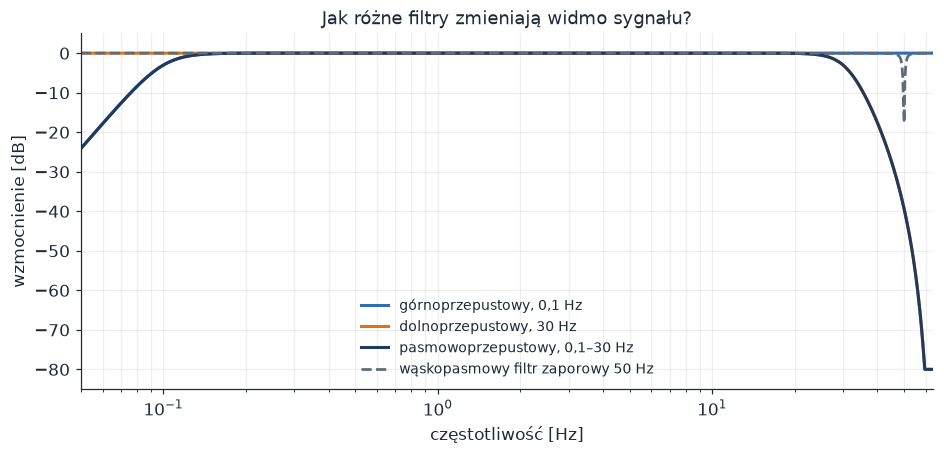

In [18]:
# Przykład dydaktyczny. Projektujemy filtry IIR wyłącznie do porównania ich charakterystyk.
# Ta komórka NIE modyfikuje raw, raw_erp ani raw_ica.
from scipy.signal import butter, sosfreqz, iirnotch, freqz

fs_demo = 128.0
freq = np.geomspace(0.05, fs_demo / 2, 1200)
fig, ax = plt.subplots(figsize=(10, 4.2))
variants = [
    ('górnoprzepustowy, 0,1 Hz', butter(4, 0.1, btype='highpass', fs=fs_demo, output='sos'), STEEL),
    ('dolnoprzepustowy, 30 Hz', butter(4, 30, btype='lowpass', fs=fs_demo, output='sos'), ACCENT),
    ('pasmowoprzepustowy, 0,1–30 Hz', butter(4, [0.1, 30], btype='bandpass', fs=fs_demo, output='sos'), NAVY),
]
for label, sos, color in variants:
    _, response = sosfreqz(sos, worN=freq, fs=fs_demo)
    ax.semilogx(freq, np.maximum(20 * np.log10(np.maximum(np.abs(response), 1e-7)), -80),
                color=color, lw=2, label=label)
# Charakterystyka wycinająca okolice 50 Hz (w tym rysunku osobny przykład).
b, a = iirnotch(50, Q=30, fs=fs_demo)
_, notch_response = freqz(b, a, worN=freq, fs=fs_demo)
ax.semilogx(freq, np.maximum(20 * np.log10(np.maximum(np.abs(notch_response), 1e-7)), -80),
            ls='--', color=GREY, lw=1.8, label='wąskopasmowy filtr zaporowy 50 Hz')
ax.set(xlabel='częstotliwość [Hz]', ylabel='wzmocnienie [dB]',
       title='Jak różne filtry zmieniają widmo sygnału?')
ax.set_ylim(-85, 5)
ax.set_xlim(0.05, 64)
ax.grid(alpha=0.2, which='both')
ax.legend(frameon=False, fontsize=9, loc='lower center')
plt.show()


0 dB oznacza, że składowa przechodzi bez istotnej zmiany amplitudy, a −20 dB oznacza około dziesięciokrotne zmniejszenie amplitudy. Nie należy utożsamiać tego wykresu z pomiarem EEG konkretnego uczestnika — przedstawia odpowiedź matematyczną przykładowych filtrów. Pomiar widmowej gęstości mocy rzeczywistego EEG znajduje się wcześniej, w rozdziale 10.

### Filtracja a próbkowanie: ograniczenie wynikające z twierdzenia Nyquista

Jeśli zapis jest próbkowany z częstością \(f_s\), to częstotliwość Nyquista wynosi \(f_s/2\). Po zmianie próbkowania do **128 Hz** wynosi ona **64 Hz**. Składowe wyższe niż 64 Hz muszą zostać odpowiednio stłumione **przed zmniejszeniem częstości próbkowania**, w przeciwnym razie mogą pojawić się w niższym paśmie jako **aliasing** (pozorne częstości). To zjawisko nie jest usuwane przez późniejsze „wygładzanie” wykresu.

Funkcja `Raw.resample()` w MNE wykonuje własne przetwarzanie przeciwdziałające aliasingowi. W tym notatniku sygnał został dodatkowo ograniczony dolnoprzepustowo do 30 Hz. Zapis 128 próbek/s wystarcza zatem dla analizowanego pasma, choć nie pozwala odzyskać składowych odrzuconych przez filtr ani odtworzyć pierwotnej częstości próbkowania. Zmiana częstości próbkowania **nie zwiększa** informacji w danych.

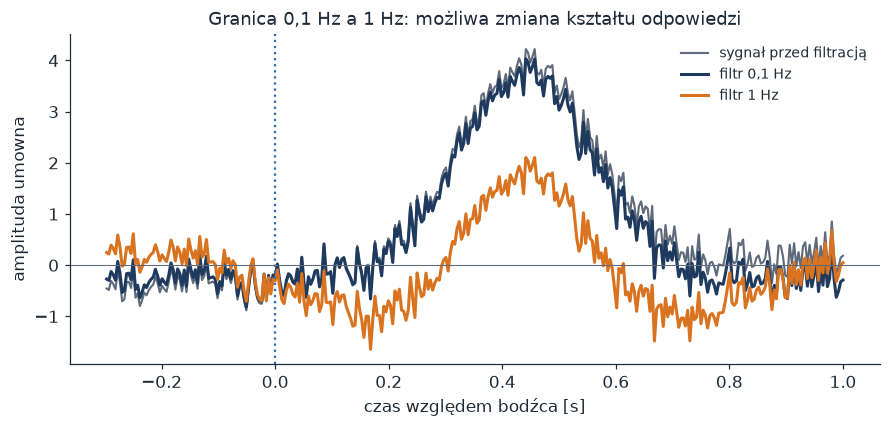

In [19]:
# Oddzielny przykład syntetyczny ilustrujący wpływ granicy filtru górnoprzepustowego.
# Wynik nie pochodzi z EEG ERP CORE i nie służy do obliczania P3.
from scipy.signal import sosfiltfilt

fs_demo = 256
czas = np.arange(0, 30, 1 / fs_demo)
# Powolny dryf, szum i powtarzający się dodatni sygnał przypominający P3.
sygnal = 1.4 * np.sin(2 * np.pi * 0.06 * czas)
for onset in [4, 8, 12, 16, 20, 24]:
    sygnal += 4.0 * np.exp(-0.5 * ((czas - onset - 0.44) / 0.12) ** 2)
rng_demo = np.random.default_rng(SEED)
sygnal += 0.22 * rng_demo.standard_normal(len(czas))

filt_01 = sosfiltfilt(butter(4, 0.1, btype='highpass', fs=fs_demo, output='sos'), sygnal)
filt_10 = sosfiltfilt(butter(4, 1.0, btype='highpass', fs=fs_demo, output='sos'), sygnal)
okno = (czas >= 15.7) & (czas <= 17.0)
fig, ax = plt.subplots(figsize=(9.5, 3.9))
ax.plot(czas[okno] - 16, sygnal[okno], color=GREY, lw=1.4, label='sygnał przed filtracją')
ax.plot(czas[okno] - 16, filt_01[okno], color=NAVY, lw=2, label='filtr 0,1 Hz')
ax.plot(czas[okno] - 16, filt_10[okno], color=ACCENT, lw=2, label='filtr 1 Hz')
ax.axvline(0, color=STEEL, ls=':', lw=1.5)
ax.axhline(0, color=GREY, lw=0.7)
ax.set(xlabel='czas względem bodźca [s]', ylabel='amplituda umowna',
       title='Granica 0,1 Hz a 1 Hz: możliwa zmiana kształtu odpowiedzi')
ax.legend(frameon=False, loc='upper right', fontsize=9)
plt.show()


Na sztucznym sygnale zwiększenie dolnej granicy pasma z 0,1 do 1 Hz nie tylko redukuje dryf, ale może również zmienić wielkość, szerokość i sąsiedztwo szczytu odpowiedzi. Nie należy więc dobierać granicy filtru według tego, która daje „ładniejszy” efekt. Jej wybór trzeba uzasadnić celem badania i właściwościami analizowanej składowej, a następnie odnotować w opisie metody.

Dodatkowa trudność dotyczy **filtracji już wyciętych epok**. Jeśli filtr ma długą odpowiedź impulsową, początek i koniec krótkiej epoki mogą zostać zniekształcone. Dlatego filtrację najczęściej wykonuje się na odpowiednio długim zapisie ciągłym, **przed wycinaniem epok**. Tę kolejność przyjęto również w notatniku.

**Jak granica filtru zmienia przebieg sygnału**

Poniższa animacja wykorzystuje sygnał syntetyczny z wcześniejszej komórki i pokazuje, jak zmienia się odpowiedź po zastosowaniu kolejnych filtrów górnoprzepustowych. Porównanie ujawnia możliwe **zmiany kształtu sygnału związane z doborem parametrów filtracji**, które mogą wpływać na późniejsze oszacowanie składowej ERP.


In [20]:
hp_values = [0.0, 0.1, 0.5, 1.0, 2.0]
labels_hp = ["bez filtracji górnoprzepustowej", "odcięcie 0,1 Hz", "odcięcie 0,5 Hz", "odcięcie 1 Hz", "odcięcie 2 Hz"]
colors_hp = [GREY, NAVY, STEEL, ACCENT, "#7E57C2"]
filtered_hp = []
for hp in hp_values:
    if hp == 0.0:
        filtered_hp.append(sygnal.copy())
    else:
        sos = butter(4, hp, btype='highpass', fs=fs_demo, output='sos')
        filtered_hp.append(sosfiltfilt(sos, sygnal))

mask = (czas >= 15.7) & (czas <= 17.0)
x = czas[mask] - 16
series = [sig[mask] for sig in filtered_hp]
lim = 1.15 * np.max(np.abs(np.concatenate(series)))
fig, ax = plt.subplots(figsize=(9.5, 3.9))

def update(frame):
    ax.clear()
    for j in range(frame + 1):
        alpha = 1.0 if j == frame else 0.18
        lw = 2.6 if j == frame else 1.1
        ax.plot(x, series[j], color=colors_hp[j], lw=lw, alpha=alpha,
                label=labels_hp[j] if j == frame else None)
    ax.axvline(0, color=STEEL, ls=':', lw=1.5)
    ax.axhline(0, color=GREY, lw=0.7)
    ax.set(xlabel='czas względem bodźca [s]', ylabel='amplituda umowna',
           ylim=(-lim, lim))
    ax.set_title(f'Wpływ granicy filtru górnoprzepustowego: {labels_hp[frame]}', loc='left')
    ax.legend(frameon=False, loc='upper right')
    ax.text(0.02, 0.04,
            'Im wyższa dolna granica, tym mniejszy dryf, ale też większe ryzyko zmiany kształtu odpowiedzi.',
            transform=ax.transAxes, fontsize=9, color=INK)

anim_filter = FuncAnimation(fig, update, frames=len(series), interval=1200, repeat=True)
show_animation(anim_filter, 'animacja_filtracja.gif', fps=1)
plt.close(fig)


Zapisano animację: output_P3\animacja_filtracja.gif


## 13. Zdarzenia: bodziec docelowy i niedocelowy
Funkcja `code` mapuje adnotacje na kody liczbowe: **1 = cel**, **2 = bodziec niedocelowy**; pozostałe adnotacje (np. odpowiedzi) pomijamy. `events_from_annotations` zwraca macierz zdarzeń (numer próbki, wartość poprzedzająca, kod).

Kod zamienia zdarzenia w indeksy próbek, zachowując tylko bodźce zadania P3.  
Powstaje macierz `events`, której pierwsza kolumna zawiera numer próbki, a trzecia kod klasy 1 lub 2. Tworzony jest także wykres osi czasu.

### Dlaczego mapowanie kodów musi być jednoznaczne?
Hipoteza badawcza dotyczy **różnicy między celem a niecelem**. Błędne przypisanie kodów odwróciłoby lub rozmyło tę różnicę niezależnie od poprawności pozostałych obliczeń. Program weryfikuje obecność obu klas, ale kontrola badawcza wymaga także odniesienia kodów do instrukcji zadania i dokumentacji zbioru.


Macierz zdarzeń: (200, 3)
Liczba [cel, niecel]: [ 40 160]
Pierwszych 5 zdarzeń: 
 [[2485    0    1]
 [2670    0    2]
 [2864    0    2]
 [3048    0    2]
 [3250    0    2]]


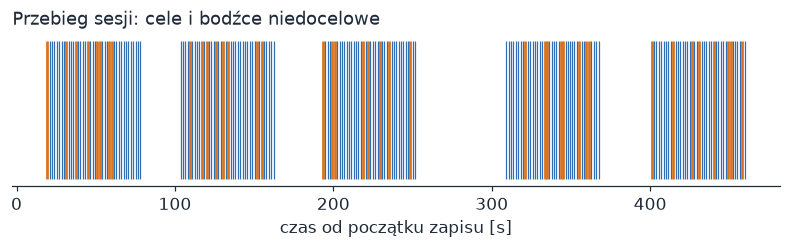

In [21]:
def code(description):
    """Koduje tylko bodźce P3: 1=cel, 2=niecel, None=inne zdarzenia."""
    if STIM_RE.fullmatch(description):
        return 1 if is_target(description) else 2
    return None

events, _ = mne.events_from_annotations(raw_erp, event_id=code)
if not ({1, 2} <= set(events[:, 2])):
    raise ValueError("Do obliczenia ERP potrzebne są zarówno cele, jak i niecele.")
print("Macierz zdarzeń:", events.shape)
print("Liczba [cel, niecel]:", np.bincount(events[:, 2], minlength=3)[1:3])
print("Pierwszych 5 zdarzeń: \n", events[:5])
time_sec = (events[:, 0] - raw_erp.first_samp) / raw_erp.info["sfreq"]
fig, ax = plt.subplots(figsize=(9, 1.8))
for event, sec in zip(events, time_sec):
    ax.vlines(sec, 0, 1, color=TGT if event[2] == 1 else NTG,
              lw=1.8 if event[2] == 1 else 0.8)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("czas od początku zapisu [s]")
ax.set_title("Przebieg sesji: cele i bodźce niedocelowe", loc="left")
plt.show()


Bodźce niedocelowe dominują, cele pojawiają się rzadko i nieregularnie. Pierwsza kolumna macierzy to numer próbki (przy 128 Hz).

### Dane po tym etapie
Każdy wiersz zdarzeń wskazuje konkretny moment bodźca i jego klasę. Pozwala to wyciąć z EEG krótkie odcinki odpowiadające pojedynczym prezentacjom liter. Na tym etapie nie ma jeszcze miary, która wskazywałaby różnicę uwagi między ludźmi. Przy błędnym mapowaniu zdarzeń cały późniejszy wynik może dotyczyć niewłaściwych bodźców.


## 14. Epoki wokół bodźca
Przed ICA tworzymy epoki **bez korekcji linii bazowej**. Korekcję przedbodźcową wykonamy po zastosowaniu ICA, zgodnie z zaleceniami MNE-Python.
Epoki obejmują przedział czasu **−0,2…0,8 s** względem bodźca; korekta względem okresu odniesienia (−0,2…0 s) polega na odjęciu średniej amplitudy sprzed bodźca. Wymiary tablicy: epoki × kanały × próbki [6].

Kod wyznacza epoki 200 ms przed i 800 ms po bodźcu; odejmuje średnią amplitudę z okresu odniesienia.  
Powstają obiekt `epochs` (epoki × kanały × próbki), mapa barwna Pz i przykładowe przebiegi pojedynczych prób.

### Co reprezentuje epoka?
Epoka jest odpowiednikiem **jednej obserwacji powtarzanego bodźca**. Przyjmujemy czas 0 jako prezentację litery. W każdej epoce znajdują się przebiegi z wszystkich elektrod, a nie jeden „wynik uwagi”. Korekta względem okresu odniesienia polega na odjęciu średnie napięcie sprzed bodźca, dzięki czemu łatwiej porównywać późniejsze odpowiedzi. Nie usuwa wszystkich różnic przedbodźcowych ani artefaktów.

Dane w postaci `[liczba epok, liczba kanałów, liczba punktów czasu]` pozwalają zadać pytanie: jak odpowiedź na cel różni się od odpowiedzi na niecel w danej elektrodzie i czasie?


Wymiary: (epoki, kanały, próbki): (200, 32, 129)
Oś czasu: [-0.203  0.797] s


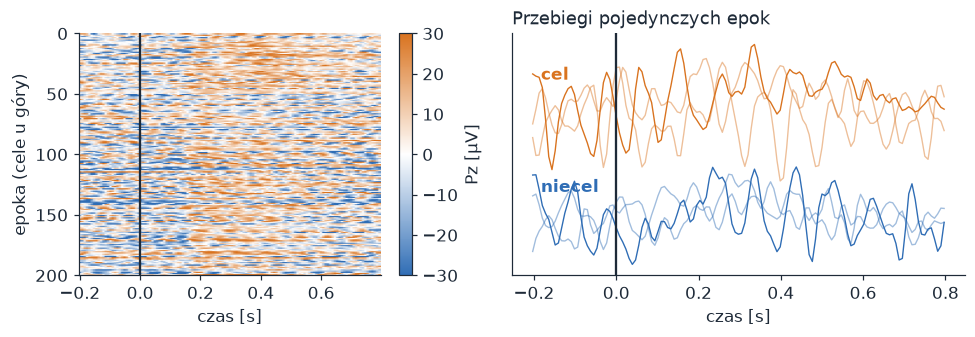

In [22]:
epochs = mne.Epochs(raw_erp, events, event_id={"target": 1, "nontarget": 2},
                    tmin=EPOCH_TMIN, tmax=EPOCH_TMAX,
                    baseline=None, preload=True)
if min(len(epochs["target"]), len(epochs["nontarget"])) < 2:
    raise ValueError("Zbyt mało epok w jednym z warunków do analizy P3.")
print("Wymiary: (epoki, kanały, próbki):", epochs.get_data().shape)
print("Oś czasu:", epochs.times[[0, -1]].round(3), "s")
pz_idx = epochs.ch_names.index(CH["pz"])
epoch_data = epochs.get_data()[:, pz_idx, :] * 1e6
labels = epochs.events[:, 2]
order = np.argsort(labels, kind="stable")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw=dict(width_ratios=[1, 1.2]))
im = axes[0].imshow(epoch_data[order], aspect="auto", cmap=CMAP,
                    vmin=-30, vmax=30,
                    extent=[epochs.times[0], epochs.times[-1], len(epoch_data), 0])
axes[0].axvline(0, color=INK)
axes[0].set(xlabel="czas [s]", ylabel="epoka (cele u góry)")
plt.colorbar(im, ax=axes[0], label="Pz [µV]")
for lab, color, offset, name in ((1, TGT, 0, "cel"), (2, NTG, -60, "niecel")):
    for j, k in enumerate(np.where(labels == lab)[0][:3]):
        axes[1].plot(epochs.times, epoch_data[k] + offset,
                     color=color, lw=0.9, alpha=1 if j == 0 else 0.45)
    axes[1].text(epochs.times[0] + 0.02, offset + 18,
                 name, color=color, fontweight="bold")
axes[1].axvline(0, color=INK)
axes[1].set_yticks([])
axes[1].set_xlabel("czas [s]")
axes[1].set_title("Przebiegi pojedynczych epok", loc="left")
plt.tight_layout(); plt.show()


Pojedyncze epoki są **bardzo zaszumione**; P3 jest widoczny dopiero po uśrednieniu wielu prób (stosunek sygnału do szumu rośnie z pierwiastkiem z liczby prób). Na obrazie (po lewej) cele są u góry; poszukaj ciemniejszego/jaśniejszego pasa po ok. 0,3 s.

### Dlaczego w ERP zwykle uśredniamy wiele prób?
Mózg i organizm generują aktywność niezwiązaną bezpośrednio z daną literą. Przy uśrednianiu wiele składników niesynchronizowanych z prezentacją bodźca częściowo się redukuje, a odpowiedź związana z bodźcem staje się lepiej widoczna. To działa tylko przy poprawnym wyznaczeniu początku epok i dostatecznej liczbie obserwacji.

Widoczna średnia odpowiedź nie oznacza, że u każdego uczestnika i w każdej pojedynczej próbie wystąpiła taka sama fala.


## 15. ICA i kanały EOG
**Analiza składowych niezależnych (ICA)** [9] rozkłada wielokanałowy sygnał EEG na składowe o możliwie niezależnych przebiegach. Dopasowujemy ją na kopii **1–30 Hz** i wykluczamy składowe, których korelacja z **HEOG/VEOG** wyróżnia się na tle pozostałych (próg standaryzowanej wartości korelacji: 3, domyślne kryterium MNE). Następnie stosujemy ICA do epok (kopia 0,1–30 Hz) i ponownie korygujemy linię bazową. Jeżeli ICA nie osiągnie zbieżności, **nie usuwamy automatycznie składowych**, a brak korekcji odnotowujemy w raporcie. Wykluczone składowe zaznaczamy na wykresie.

Kod wyznacza model ICA na kopii 1–30 Hz, identyfikuje składowe EOG i odejmuje je od epok.  
Dostępne są model `ica`, lista `idx`, wyniki korelacji `scores`, epoki po korekcji i topografie składowych.

Składowe ICA wykrywa się osobno dla HEOG i VEOG, a lista wykluczeń jest sumą obu testów. Automatyczne wykrywanie nie zastępuje oceny topografii i przebiegów składowych.

### Co umożliwia ICA?
ICA próbuje odróżnić nakładające się na siebie wzorce sygnałów. Składowe silnie związane z EOG mogą odzwierciedlać mruganie i ruchy oczu; ich usunięcie zmniejsza ryzyko, że artefakt zostanie pomylony z efektem poznawczym. Jednak **automatyczna korekcja może też usuwać sygnał neuronalny**, dlatego ocena jakości obejmuje liczbę i charakter wykluczonych składowych oraz informację o zbieżności algorytmu.

Po zastosowaniu ICA uzyskuje się zmodyfikowane epoki EEG. Nie powstaje nowa zmienna psychologiczna, a sam fakt usunięcia składowych nie dowodzi, że P3 jest prawidłowa.


### Czym ICA różni się od filtracji?

**Filtracja** rozróżnia składowe na podstawie częstotliwości. **Analiza składowych niezależnych (ICA)** poszukuje mieszanin źródeł o różnych przebiegach czasowych i wzorcach przestrzennych. Dlatego ICA bywa przydatna wtedy, gdy mrugnięcia i aktywność EEG mają częściowo podobne pasmo częstotliwości.

ICA nie „wie”, co jest sygnałem mózgowym, a co artefaktem. Składowe trzeba ocenić na podstawie ich przebiegu, rozkładu przestrzennego i związku z EOG; automatyczny wybór wymaga kontroli. Usunięcie zbyt wielu składowych może zniszczyć również sygnał neuronalny. Z kolei brak zbieżności algorytmu oznacza, że rozdzielenie źródeł może być niepewne.

Filtrowanie, zmiana odniesienia, ICA i odrzucanie epok to różne operacje. Żadna nie zastępuje pozostałych; każda powinna być opisana oddzielnie w metodzie badania.

Składowe ICA wykluczone z EEG: [0, 4] z 20 | zbieżność: True | korekcja wykonana: True


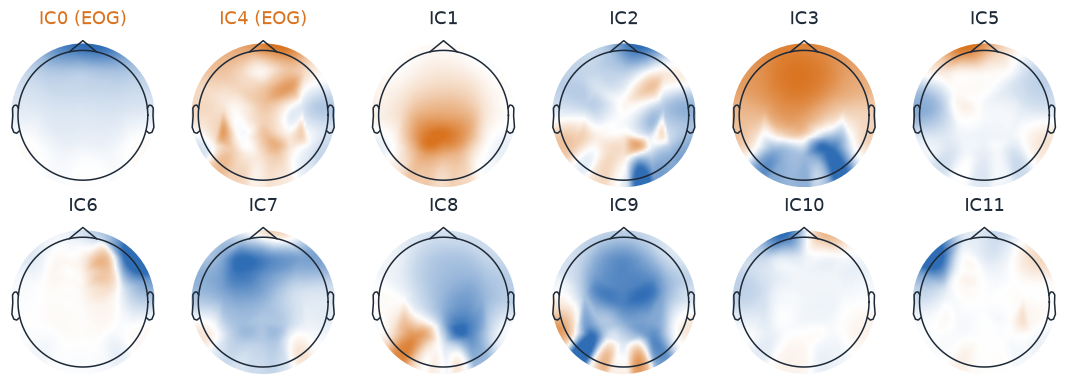

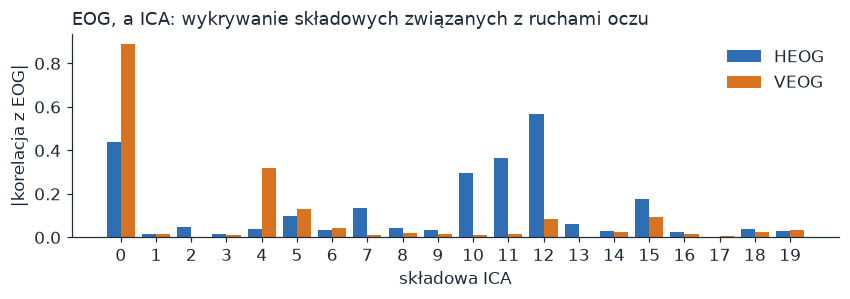

In [23]:
def fit_and_apply_ica(raw_for_ica, ep, seed=SEED):
    """Dopasowuje ICA; przy braku zbieżności pomija automatyczne usuwanie składowych."""
    n_eeg = len(mne.pick_types(raw_for_ica.info, eeg=True, eog=False))
    n_components = min(20, n_eeg - 2)  # zapas uwzględniający spadek rzędu macierzy po zmianie odniesienia
    if n_components < 2:
        raise ValueError("Za mało kanałów EEG do dekompozycji ICA")
    model = mne.preprocessing.ICA(n_components=n_components,
                                  random_state=seed, max_iter=800)
    from sklearn.exceptions import ConvergenceWarning
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(raw_for_ica, picks="eeg")
    model.converged_ = (
        not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        and getattr(model, "n_iter_", model.max_iter) < model.max_iter
    )
    if not model.converged_:
        warnings.warn("ICA nie osiągnęła zbieżności: pominięto automatyczne "
                      "usuwanie składowych EOG.", RuntimeWarning)
        model.exclude = []
        ep.apply_baseline((EPOCH_TMIN, 0))
        empty = np.zeros(model.n_components_, dtype=float)
        return model, [], {"HEOG": empty.copy(), "VEOG": empty.copy()}
    eog_scores = {}
    bad_components = set()
    for channel in ("HEOG", "VEOG"):
        bad, score = model.find_bads_eog(raw_for_ica, ch_name=channel, threshold=3.0)
        bad_components.update(int(i) for i in bad)
        eog_scores[channel] = np.asarray(score, dtype=float)
    model.exclude = sorted(bad_components)
    model.apply(ep)
    ep.apply_baseline((EPOCH_TMIN, 0))
    return model, sorted(bad_components), eog_scores

ica, idx, scores = fit_and_apply_ica(raw_ica, epochs)
print("Składowe ICA wykluczone z EEG:", idx, "z", ica.n_components_, "| zbieżność:", ica.converged_, "| korekcja wykonana:", ica.converged_)
components = ica.get_components()
show = idx + [k for k in range(components.shape[1]) if k not in idx]
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for ax, k in zip(axes.ravel(), show[:12]):
    values = components[:, k]
    mne.viz.plot_topomap(values, ica.info, axes=ax, show=False,
                         cmap=CMAP, vlim=sym(values), sensors=False, contours=0)
    excluded = k in idx
    ax.set_title(f"IC{k}" + (" (EOG)" if excluded else ""),
                 color=ACCENT if excluded else INK)
for ax in axes.ravel()[min(len(show), 12):]: ax.axis("off")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(9, 2.4))
positions = np.arange(ica.n_components_)
for j, (channel, color) in enumerate((("HEOG", STEEL), ("VEOG", ACCENT))):
    ax.bar(positions + (j - 0.5) * 0.4,
           np.abs(scores[channel]), 0.4, color=color, label=channel)
ax.set_xticks(positions)
ax.set(xlabel="składowa ICA", ylabel="|korelacja z EOG|")
ax.legend(frameon=False)
ax.set_title("EOG, a ICA: wykrywanie składowych związanych z ruchami oczu", loc="left")
plt.show()


Składowe oznaczone **(EOG)** to te, których korelacja z kanałami okoruchowymi (wykres słupkowy) najsilniej odstaje od pozostałych; zwykle mają topografię czołową. Tym razem decyzja o wykluczeniu opiera się na **rzeczywistym sygnale okoruchowym**, nie tylko na wyglądzie mapy. Korelacja nie gwarantuje, że składowa jest wyłącznie artefaktem; zawsze zerknij na mapy.

### Jak interpretować wykres składowych?
Silna korelacja składowej z EOG **sugeruje** wspólne źródło związane z oczami, lecz nie jest stuprocentowym dowodem. Po usunięciu składowej warto porównać przebiegi przed i po korekcji i sprawdzić, czy usuwane są typowe artefakty bez zniekształcania odpowiedzi wywołanych. Jeśli ICA nie osiągnęła zbieżności, wynik należy oznaczyć jako wymagający szczególnej kontroli, a nie bezwarunkowo akceptować.


**Ten sam sygnał przed i po ICA**

Porównanie tych samych epok przed zastosowaniem analizy składowych niezależnych i po korekcji pokazuje zmiany w sygnale związane z mrugnięciem lub ruchem gałek ocznych. W pierwszym panelu pokazano elektrodę czołową, gdzie artefakt zwykle jest najbardziej widoczny, a w drugim Pz, czyli kanał kluczowy dla P3.


In [24]:
epochs_before_ica = mne.Epochs(raw_erp, events, event_id={"target": 1, "nontarget": 2},
                               tmin=EPOCH_TMIN, tmax=EPOCH_TMAX,
                               baseline=(EPOCH_TMIN, 0), preload=True, verbose='error')
epochs_after_ica = epochs.copy()
frontal_name = CH.get('fp2', CH.get('fz', CH['pz']))
if 'VEOG' in epochs_before_ica.ch_names:
    blink_metric = np.max(np.abs(epochs_before_ica.get_data(picks=['VEOG'])[:, 0, :]), axis=1)
else:
    blink_metric = np.max(np.abs(epochs_before_ica.get_data(picks=[frontal_name])[:, 0, :]), axis=1)
show_idx = np.argsort(blink_metric)[-min(10, len(blink_metric)):]
show_idx = show_idx[np.argsort(blink_metric[show_idx])[::-1]]

before_frontal = epochs_before_ica.get_data(picks=[frontal_name])[:, 0, :] * 1e6
after_frontal = epochs_after_ica.get_data(picks=[frontal_name])[:, 0, :] * 1e6
before_pz = epochs_before_ica.get_data(picks=[CH['pz']])[:, 0, :] * 1e6
after_pz = epochs_after_ica.get_data(picks=[CH['pz']])[:, 0, :] * 1e6
ylim_f = 1.1 * np.max(np.abs(np.r_[before_frontal[show_idx].ravel(), after_frontal[show_idx].ravel()]))
ylim_p = 1.1 * np.max(np.abs(np.r_[before_pz[show_idx].ravel(), after_pz[show_idx].ravel()]))

fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)

def update(frame):
    epoch_no = show_idx[frame]
    axes[0].clear(); axes[1].clear()
    for ax, yb, ya, name, ylim in [
        (axes[0], before_frontal, after_frontal, frontal_name, ylim_f),
        (axes[1], before_pz, after_pz, CH['pz'], ylim_p),
    ]:
        ax.plot(epochs_before_ica.times, yb[epoch_no], color=MIST, lw=2.0, label='przed ICA')
        ax.plot(epochs_before_ica.times, ya[epoch_no], color=ACCENT, lw=1.8, label='po ICA')
        ax.axvline(0, color=INK, lw=0.8)
        ax.axvspan(P3_TMIN, P3_TMAX, color=PALE, alpha=0.45)
        ax.axhline(0, color=GREY, lw=0.7)
        ax.set_ylabel(f'{name} [µV]')
        ax.set_ylim(-ylim, ylim)
        ax.legend(frameon=False, loc='upper right')
    axes[0].set_title(f'Epoka {epoch_no}: porównanie przed i po ICA', loc='left')
    axes[1].set_xlabel('czas względem bodźca [s]')
    axes[1].text(0.02, 0.06,
                 'Zmniejszenie artefaktu nie jest jeszcze dowodem poprawności wyniku; liczy się także zachowanie sygnału neuronalnego',
                 transform=axes[1].transAxes, fontsize=9, color=INK)

anim_ica = FuncAnimation(fig, update, frames=len(show_idx), interval=1300, repeat=True)
show_animation(anim_ica, 'animacja_ica_przed_po.gif', fps=1)
plt.close(fig)


Zapisano animację: output_P3\animacja_ica_przed_po.gif


## 16. Kontrola jakości epok
Po ICA odrzucamy epoki z resztkowymi artefaktami. Próg wyznaczamy metodą **odporną na wartości odstające**: mediana maksymalnych rozstępów napięcia w epokach + 3 × przeskalowane medianowe odchylenie bezwzględne (MAD), **bez użycia etykiet klas** i osobno dla każdej osoby (stały próg, np. 100 µV, bywa nieodpowiedni dla danych o innej skali).

Kod oblicza maksymalny rozstęp napięcia między szczytem a minimum w każdej epoce EEG i próg odporny na wartości odstające.  
Wyniki obejmują statystyki `qc_one`, listę zachowanych epok i histogram artefaktów. Odrzucone epoki nie trafiają do ERP.

Próg wyznaczany na podstawie mediany i 3 × MAD jest regułą pomocniczą demonstracyjną, a nie uniwersalnym kryterium klinicznym. Rejestrujemy oddzielnie odrzucenia celów i niecelów, ponieważ nierównomierna selekcja prób może obciążyć efekt P3. Dla każdej osoby przedstawiane są próg odrzucania w µV oraz liczba odrzuconych epok.

### Co oznacza „odrzucenie próby”?
Nie usuwamy uczestnika dlatego, że jego odpowiedź poznawcza jest „zbyt słaba”. Usuwamy **epokę z podejrzanie dużym rozstępem napięć**, który może wskazywać na ruch, usterkę elektrody lub inny artefakt. Próg liczony z rozkładu sygnału zależy od danych konkretnej osoby, dlatego przy silnie zaburzonym sygnale również próg może być zawodny. Dobrą praktyką jest obejrzenie odrzuconych epok i zapisanie odsetka utraconych prób.

Należy ustalić, czy odrzucenia są podobne w obu warunkach? Jeśli znikają przede wszystkim reakcje na cele, średnia ERP może być obciążona selekcją prób.


Próg: 144.3 µV | zachowano 190 z 200 epok


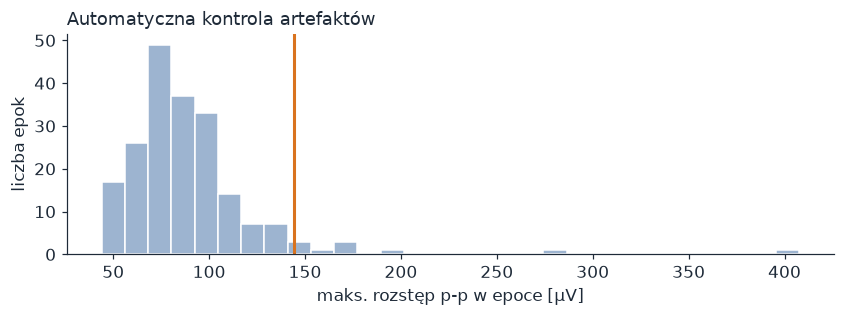

In [25]:
def reject_artifact_epochs(ep):
    """Odrzuca epoki na podstawie maksymalnej amplitudy p-p po wszystkich EEG"""
    data = ep.get_data(picks="eeg")
    if len(data) == 0:
        raise ValueError("Brak epok do kontroli jakości.")
    peak_to_peak = np.ptp(data, axis=2).max(axis=1)  # [V] na epokę
    med = float(np.median(peak_to_peak))
    mad = float(st.median_abs_deviation(peak_to_peak, scale="normal"))
    threshold = max(med + 3 * mad, 1e-9)
    n_before = len(ep)
    before_target = len(ep["target"])
    before_nontarget = len(ep["nontarget"])
    ep.drop_bad(reject={"eeg": threshold})
    ep.pick("eeg")
    if len(ep) == 0 or min(len(ep["target"]), len(ep["nontarget"])) < 2:
        raise ValueError("Kontrola jakości usunęła zbyt wiele epok; sprawdź dane i próg")
    return ep, {"n_before_qc": n_before, "n_after_qc": len(ep),
                "n_rejected_target": before_target - len(ep["target"]),
                "n_rejected_nontarget": before_nontarget - len(ep["nontarget"]),
                "rejected_fraction": (n_before - len(ep)) / n_before,
                "threshold_uV": threshold * 1e6}, peak_to_peak

epochs, qc_one, pp = reject_artifact_epochs(epochs)
canonical_channels = list(epochs.ch_names)
thr = qc_one["threshold_uV"]
print(f"Próg: {thr:.1f} µV | zachowano {len(epochs)} z {len(pp)} epok")
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.hist(pp * 1e6, bins=30, color=MIST, edgecolor="white")
ax.axvline(thr, color=ACCENT, lw=2)
ax.set(xlabel="maks. rozstęp p-p w epoce [µV]", ylabel="liczba epok")
ax.set_title("Automatyczna kontrola artefaktów", loc="left")
plt.show()


Większość epok tworzy zwarty rozkład, a ogon po prawej to epoki z artefaktami. 

Ocena jakości danych obejmuje próg i liczbę odrzuconych epok. Kryteria automatycznego odrzucania wymagają sprawdzenia na analizowanym zbiorze danych.

### Interpretacja histogramu
Oś pozioma pokazuje **największy rozstęp napięcia w epoce** (µV), oś pionowa liczbę epok o takiej wartości. Pionowa linia oznacza przyjęty próg: epoki przekraczające próg są odrzucane. Duży odsetek odrzuconych obserwacji osłabia precyzję ERP i może zaburzyć porównywalność uczestników.

W hipotetycznym przykładzie zachowanie 700 z 1000 epok oznacza 70% zachowanych i 30% odrzuconych epok. Nie są to wartości uzyskane z danych ERP CORE. Sam odsetek nie potwierdza poprawności pomiaru. Sam histogram nie rozstrzyga o jakości poznawczej wykonania zadania.


---

# CZĘŚĆ III. **Analiza ERP**

## 17. Uśrednianie: bodźce docelowe i niedocelowe
Średnia po epokach (`epochs.average()`) daje obiekt `Evoked`. Poniżej średnia dla Pz z pasmem przedstawiającym **błąd standardowy średniej** (między próbami). **Oczekiwanie z literatury** [10]: dla celów wolne, dodatnie wychylenie w oknie ok. 300–600 ms (P3). To oczekiwanie, nie wynik: sprawdzamy, czy potwierdza się w analizowanych danych.

Kod uśrednia osobno epoki celu i niecelu oraz wyznacza błąd standardowy średniej (SEM) w każdej chwili.  
Powstają dwa obiekty `Evoked` (`t` i `n`) oraz wykres przebiegów Pz z pasmami błędu standardowego.

Pasy SEM opisują zmienność epok *wewnątrz pojedynczej osoby* i nie stanowią testu istotności między warunkami. Nakładanie się pasów nie przesądza o wyniku testu.

### Związek średniej ERP z hipotezą badawczą
Porównanie warunków „bodziec docelowy” i „bodziec niedocelowy” jest pierwszym bezpośrednim sprawdzianem hipotezy o innym przetwarzaniu bodźców istotnych dla zadania. Patrzymy, czy średnia odpowiedź na cel jest dodatniejsza w oknie P3, a także **na ilu epokach** opiera się każda średnia. Wykres jednej osoby jest ilustracją, nie testem na poziomie populacji.


Liczby epok [cel, niecel]: [37, 153]


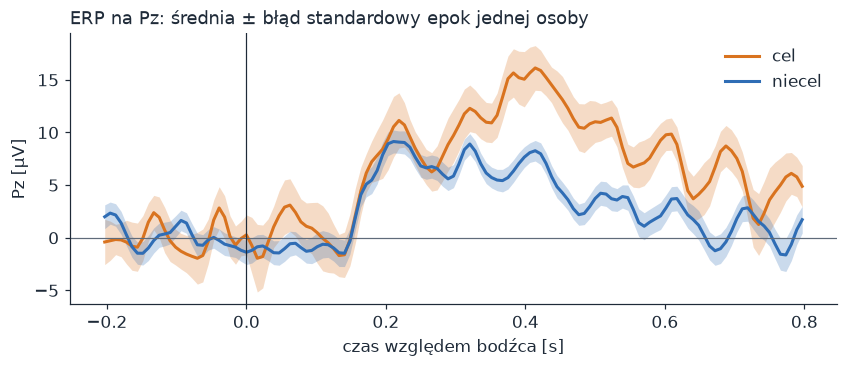

In [26]:
evokeds = {condition: epochs[condition].average()
           for condition in ("target", "nontarget")}
erp_cel, erp_niecel = evokeds["target"], evokeds["nontarget"]
erp_cel.comment, erp_niecel.comment = "target", "nontarget"
print("Liczby epok [cel, niecel]:", [e.nave for e in (erp_cel, erp_niecel)])
pz = epochs.ch_names.index(CH["pz"])
times = epochs.times
fig, ax = plt.subplots(figsize=(9, 3.2))
for condition, color, label in (("target", TGT, "cel"),
                                ("nontarget", NTG, "niecel")):
    signals = epochs[condition].get_data()[:, pz, :] * 1e6
    mean = signals.mean(axis=0)
    se = signals.std(axis=0, ddof=1) / np.sqrt(len(signals))
    ax.fill_between(times, mean - se, mean + se,
                    color=color, alpha=0.25, lw=0)
    ax.plot(times, mean, color=color, lw=2, label=label)
ax.axhline(0, color=GREY, lw=0.8)
ax.axvline(0, color=INK, lw=0.8)
ax.set(xlabel="czas względem bodźca [s]", ylabel="Pz [µV]")
ax.legend(frameon=False)
ax.set_title("ERP na Pz: średnia ± błąd standardowy epok jednej osoby", loc="left")
plt.show()


### Jak czytać dwie krzywe ERP?
Na osi poziomej widzimy **czas od prezentacji litery**, a na pionowej **napięcie na Pz w µV**. Linia „bodziec docelowy” opisuje średnią odpowiedź na literę będącą celem, a linia „bodziec niedocelowy” — średnią odpowiedź na pozostałe litery. Oczekiwany wzorzec P3b to dodatniejsza odpowiedź na cel mniej więcej w oknie 300–600 ms; kształt, amplituda i latencja mogą się różnić między osobami.

Zacieniowane pasy to **±1 błąd standardowy średniej liczony po epokach jednej osoby**. Nie są to 95% przedziały ufności efektu między warunkami ani miara zmienności między uczestnikami. Ich nakładanie się lub brak nakładania **nie stanowi testu istotności statystycznej**. Cele mają zwykle mniej epok, co może skutkować większym błędem ich średniej. Formalne wnioskowanie grupowe wykonujemy dalej, na poziomie uczestników.



## 17. Jak z wielu epok powstaje ERP?
To jedno z najważniejszych pytań dydaktycznych. Pojedyncza odpowiedź EEG po bodźcu jest zwykle bardzo zaszumiona. Dlatego zamiast interpretować jedną próbę, **uśredniamy wiele podobnych epok**.

Kod pokazuje na sztucznym przykładzie kilka pojedynczych epok i ich średnią.  
Powstaje wykres pokazujący, jak uśrednianie uwydatnia wspólny składnik odpowiedzi.


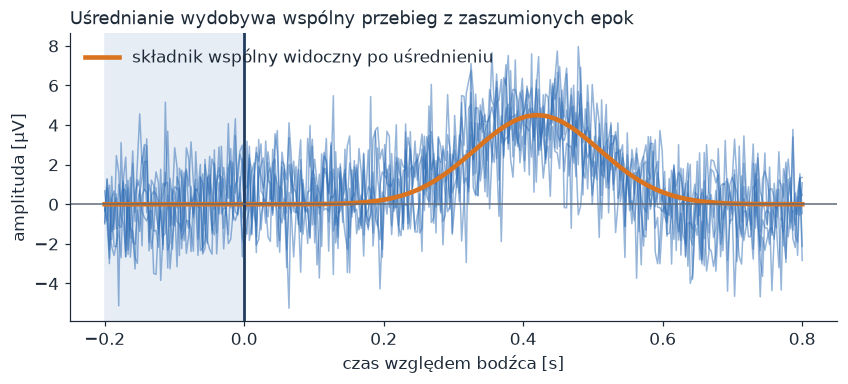

In [27]:
rng = np.random.default_rng(SEED)
t_demo = np.linspace(-0.2, 0.8, 300)
base = 4.5 * np.exp(-0.5 * ((t_demo - 0.42) / 0.09) ** 2)
fig, ax = plt.subplots(figsize=(9, 3.4))
for i in range(6):
    noise = rng.normal(0, 1.6, size=t_demo.size)
    drift = 0.6 * np.sin(2 * np.pi * (t_demo + i/20))
    epoch = base + noise + drift
    ax.plot(t_demo, epoch, lw=1, alpha=0.5, color=STEEL)
ax.plot(t_demo, base, lw=3, color=ACCENT, label='składnik wspólny widoczny po uśrednieniu')
ax.axvline(0, color=NAVY, lw=1.8)
ax.axhline(0, color=GREY, lw=1)
ax.axvspan(-0.2, 0, color=PALE)
ax.set_xlabel('czas względem bodźca [s]')
ax.set_ylabel('amplituda [µV]')
ax.set_title('Uśrednianie wydobywa wspólny przebieg z zaszumionych epok', loc='left')
ax.legend(frameon=False, loc='upper left')
plt.show()


Niebieskawe linie reprezentują pojedyncze epoki, czyli odpowiedzi na pojedyncze bodźce. Każda z nich zawiera zarówno sygnał związany z przetwarzaniem bodźca, jak i przypadkowy szum. Po uśrednieniu wzmacnia się to, co jest **wspólne** dla wielu prób, a osłabia to, co jest przypadkowe. Dlatego uśredniona odpowiedź ułatwia wykrycie zmian regularnie związanych ze zdarzeniem.


**Jak z pojedynczych prób wyłania się ERP**

Animacja przedstawia stopniowe uśrednianie odpowiedzi na bodźce docelowe i niedocelowe. Wraz ze zwiększaniem liczby epok wpływ przypadkowych fluktuacji na średnią maleje, a przebieg związany z prezentacją bodźca staje się lepiej widoczny.


In [ ]:
target_trials = epochs['target'].get_data(picks=[CH['pz']])[:, 0, :] * 1e6
nontarget_trials = epochs['nontarget'].get_data(picks=[CH['pz']])[:, 0, :] * 1e6
max_k = min(len(target_trials), len(nontarget_trials), 40)
if max_k < 2:
    print('Za mało epok do animacji stopniowego uśredniania.')
else:
    n_seq = np.unique(np.linspace(1, max_k, min(20, max_k), dtype=int))
    csum_t = np.cumsum(target_trials, axis=0)
    csum_n = np.cumsum(nontarget_trials, axis=0)
    ylim = 1.1 * np.max(np.abs(np.r_[target_trials[:max_k].ravel(), nontarget_trials[:max_k].ravel()]))
    fig, ax = plt.subplots(figsize=(9, 3.6))
    def update(frame):
        k = int(n_seq[frame])
        mean_t = csum_t[k - 1] / k
        mean_n = csum_n[k - 1] / k
        ax.clear()
        ax.plot(epochs.times, mean_t, color=TGT, lw=2.5, label=f'cel: średnia z {k} epok')
        ax.plot(epochs.times, mean_n, color=NTG, lw=2.5, label=f'niecel: średnia z {k} epok')
        ax.axvline(0, color=INK, lw=0.8)
        ax.axhline(0, color=GREY, lw=0.8)
        ax.axvspan(P3_TMIN, P3_TMAX, color=PALE, alpha=0.45)
        ax.set(xlabel='czas względem bodźca [s]', ylabel='Pz [µV]', ylim=(-ylim, ylim))
        ax.set_title('Powstawanie ERP przez uśrednianie kolejnych epok', loc='left')
        ax.legend(frameon=False, loc='upper left')
        ax.text(0.02, 0.05,
                'W miarę dokładania prób maleje wpływ szumu losowego, a zostaje składnik wspólny dla danego warunku.',
                transform=ax.transAxes, fontsize=9, color=INK)
    anim_avg = FuncAnimation(fig, update, frames=len(n_seq), interval=900, repeat=True)
    show_animation(anim_avg, 'animacja_usrednianie_erp.gif', fps=2)
    plt.close(fig)


## 18. Fala różnicowa i okno P3
**Fala różnicowa** (cel − niecel) odejmuje od siebie uśrednione odpowiedzi obu warunków i uwydatnia różnice między nimi. Okno **300–600 ms** ustaliliśmy a priori [10]; szczyt wybieramy tylko w jego obrębie.

Kod odejmuje ERP niecelu od ERP celu i oblicza średnią i maksimum w zadanym oknie.  
Powstają obiekt `Evoked` o nazwie `diff`, średnia amplituda w µV, maksimum w µV i czas jego wystąpienia w ms.

### Dlaczego fala różnicowa jest użyteczna?
Krzywa „cel minus niecel” podaje bezpośrednio **w jakim kierunku i o ile µV** warunki różnią się na danej elektrodzie. Wynik `+3 µV` w ustalonym oknie oznacza, że średnia odpowiedź na cel była o 3 µV dodatniejsza niż na niecel. Nie oznacza „o 3 jednostki lepszej uwagi”. Oprócz średniej program wskazuje najwyższy punkt krzywej i jego czas, ale szczyt jest bardziej podatny na szum i nie jest tutaj osobnym testem statystycznym.


In [ ]:
diff = mne.combine_evoked([erp_cel, erp_niecel], weights=[1, -1])
diff.comment = "target-minus-nontarget"
w = diff.copy().pick(CH["pz"]).crop(P3_TMIN, P3_TMAX)
k = int(w.data[0].argmax())
print(f"Średnia różnica na Pz (300–600 ms): {w.data.mean() * 1e6:.2f} µV")
print(f"Maksimum w zadanym oknie: {w.times[k] * 1e3:.0f} ms, {w.data[0, k] * 1e6:.2f} µV")
fig, ax = plt.subplots(figsize=(9, 3))
ax.axvspan(P3_TMIN, P3_TMAX, color=PALE)
ax.plot(diff.times, diff.data[pz] * 1e6, color=NAVY, lw=2)
ax.plot([w.times[k]], [w.data[0, k] * 1e6], "o", color=ACCENT)
ax.axhline(0, color=GREY, lw=0.8)
ax.axvline(0, color=INK, lw=0.8)
ax.set(xlabel="czas względem bodźca [s]", ylabel="cel − niecel [µV]")
ax.set_title("Fala różnicowa na Pz", loc="left")
plt.show()


Dodatnie wychylenie w zacieniowanym oknie to P3. Latencja szczytu bywa zmienna między osobami. Gdybyśmy wybrali okno po obejrzeniu tej krzywej, zawyżylibyśmy istotność testu (krążenie w rozumowaniu).

### Dwa różne wyniki: amplituda i latencja
**Amplituda średnia [µV]** jest z góry ustaloną miarą wielkości różnicy w okresie 300–600 ms i to ona trafia do testu grupowego. **Latencja maksimum [ms]** to czas, w którym pojedyncza fala różnicowa osiągnęła najwyższe napięcie w tym oknie. Latencji szczytu nie należy utożsamiać z czasem reakcji ani bezpośrednio z „szybkością myślenia”; może ona zmieniać się wskutek szumu i nakładania składowych.

Hipotetyczna średnia różnica +2,6 µV z maksimum po 440 ms ilustruje wartości opisujące ERP, ale nie dowodzi istotności statystycznej ani sprawniejszego funkcjonowania poznawczego badanej osoby.


### Schemat: amplituda i latencja składowej P3
Amplituda i latencja to dwa najczęściej opisywane parametry składowej ERP. Przed interpretacją warto określić, **jak te wielkości wyznacza się na wykresie**.

Kod rysuje schematyczny przebieg ERP z zaznaczeniem amplitudy i latencji P3.  
Powstaje wykres objaśniający amplitudę i latencję składowej P3.


In [ ]:
tt = np.linspace(-0.2, 0.8, 400)
wave = 0.8*np.exp(-0.5*((tt-0.12)/0.05)**2) - 1.2*np.exp(-0.5*((tt-0.22)/0.04)**2) + 4.7*np.exp(-0.5*((tt-0.43)/0.09)**2)
peak_idx = np.argmax(wave[(tt>=0.3)&(tt<=0.6)]) + np.where(tt>=0.3)[0][0]
peak_t, peak_a = tt[peak_idx], wave[peak_idx]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(tt, wave, color=ACCENT, lw=2.8)
ax.axhline(0, color=GREY, lw=1)
ax.axvline(0, color=NAVY, lw=1.8)
ax.axvspan(0.3, 0.6, color=MIST, alpha=0.5)
ax.vlines(peak_t, 0, peak_a, color=STEEL, lw=2, linestyles='--')
ax.hlines(peak_a, 0.02, peak_t, color=STEEL, lw=2, linestyles='--')
ax.scatter([peak_t], [peak_a], s=90, color=NAVY, zorder=5)
ax.text(peak_t+0.02, peak_a+0.15, 'szczyt P3', fontsize=10, weight='bold')
ax.text(peak_t/2, peak_a+0.2, """latencja
(czas do szczytu)""", ha='center', fontsize=10)
ax.text(0.08, peak_a/2, """amplituda
(wysokość względem linii odniesienia)""", va='center', fontsize=10)
ax.set_xlabel('czas względem bodźca [s]')
ax.set_ylabel('amplituda [µV]')
ax.set_title('Co oznaczają amplituda i latencja P3?', loc='left')
plt.show()


**Amplituda** mówi, jak duże jest wychylenie sygnału, a **latencja** mówi, kiedy to wychylenie osiąga maksimum. Sama w sobie większa amplituda nie oznacza automatycznie „lepszej uwagi”, a dłuższa latencja nie oznacza automatycznie „gorszego działania”. Interpretacja zależy od zadania, grupy badanej, jakości danych i porównania z odpowiednim warunkiem odniesienia.


## 19. Topografia P3
Trzy mapy uśrednione w oknie 300–600 ms: cel, niecel i różnica. **Oczekiwany wzorzec** [10]: wyraźna dodatnia różnica nad okolicą ciemieniową, w pobliżu Pz.

Kod rysuje interpolowane mapy napięć EEG z 300–600 ms.  
Powstają trzy mapy topograficzne i wartości skrajne różnicy przestrzennej. Mapy nie lokalizują źródeł korowych.

### Co ma wspólnego topografia z P3b?
P3b w klasycznym zadaniu z bodźcem rzadkim jest często najsilniej dodatnia nad okolicami ciemieniowymi. Jeśli mapa „cel minus niecel” ma dodatni obszar w pobliżu Pz, jest to **zgodne z oczekiwanym wzorcem przestrzennym**, ale mapa sama nie ustala mechanizmu poznawczego. Trzeba także sprawdzić przebieg w czasie, stabilność między osobami i zachowanie uczestników, jeżeli jest dostępne.


In [ ]:
info = epochs.info
def average_window(e):
    return e.copy().crop(P3_TMIN, P3_TMAX).data.mean(axis=1) * 1e6
vals = [average_window(e) for e in (erp_cel, erp_niecel, diff)]
limit_common = sym(np.concatenate(vals[:2]))
names = [name if name.lower() in ("pz", "cz") else "" for name in info.ch_names]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, values, title, limits in zip(
    axes, vals, ("cel", "niecel", "cel − niecel"),
    (limit_common, limit_common, sym(vals[2]))
):
    image, _ = mne.viz.plot_topomap(values, info, axes=ax, show=False,
                                    cmap=CMAP, vlim=limits, names=names,
                                    sensors=True, contours=4)
    ax.set_title(title)
    plt.colorbar(image, ax=ax, shrink=0.7, label="µV")
plt.tight_layout(); plt.show()
print("Różnica amplitudy P3: maksimum", info.ch_names[int(np.argmax(vals[2]))],
      f"{np.max(vals[2]):.1f} µV; minimum", info.ch_names[int(np.argmin(vals[2]))],
      f"{np.min(vals[2]):.1f} µV")


Pomarańczowy = potencjał dodatni, niebieski = ujemny (wspólna skala dla map cel/niecel). Zmiana potencjału na elektrodzie nie wskazuje jednoznacznie źródła neuronalnego; przewodnictwo objętościowe rozmywa rozkład.

### Jak porównywać kolory na trzech mapach?
Pierwsze dwie mapy mają **wspólną skalę kolorów**, dlatego można porównywać ich amplitudy. Mapa **różnicy** ma **osobną skalę**, dobraną do wartości cel − niecel: jej intensywności koloru nie wolno porównywać wprost z intensywnością na dwóch pierwszych mapach. Barwa odzwierciedla znak i wielkość napięcia, a nie rodzaj emocji ani „aktywację” określonej funkcji psychicznej.

Na mapie można wskazać elektrody, nad którymi odnotowano największą dodatnią różnicę potencjału między warunkami. Sama topografia EEG nie pozwala jednak przypisać określonemu obszarowi mózgu odpowiedzialności za uwagę badanej osoby.


**Zmiany rozkładu potencjału na powierzchni głowy**

Animacja przedstawia zmiany różnicy potencjału między bodźcem docelowym a niedocelowym w kolejnych chwilach. Mapa topograficzna przedstawia rozkład napięć na powierzchni głowy, a nie anatomiczną lokalizację źródeł aktywności mózgu.


In [ ]:
picks_eeg = mne.pick_types(diff.info, eeg=True, eog=False)
info_topo = mne.pick_info(diff.info, picks_eeg)
times_topo = np.arange(0.0, min(0.81, diff.times[-1] + 1e-9), 0.04)
idx_topo = [int(np.argmin(np.abs(diff.times - tt))) for tt in times_topo]
values_all = diff.data[picks_eeg][:, idx_topo] * 1e6
vlim_topo = sym(values_all.ravel())
fig, ax = plt.subplots(figsize=(5.2, 4.8))

def update(frame):
    ax.clear()
    idx_t = idx_topo[frame]
    values = diff.data[picks_eeg, idx_t] * 1e6
    mne.viz.plot_topomap(values, info_topo, axes=ax, show=False,
                         cmap=CMAP, vlim=vlim_topo, sensors=True, contours=4)
    ax.set_title(f'Cel − niecel: {diff.times[idx_t]*1e3:.0f} ms', loc='left')
    ax.text(0.03, 0.03, 'Skala barw jest stała dla wszystkich klatek.',
            transform=ax.transAxes, fontsize=9, color=INK)

anim_topo = FuncAnimation(fig, update, frames=len(idx_topo), interval=350, repeat=True)
show_animation(anim_topo, 'animacja_topografia_p3.gif', fps=4)
plt.close(fig)


## 20. Wszyscy uczestnicy
Dotąd pracowaliśmy na jednej osobie. Poniższa funkcja `process_subject` wykonuje **dokładnie kroki 5–16** dla dowolnego uczestnika i zwraca oczyszczone epoki (tylko EEG). Wynik dla pierwszej osoby powinien zgadzać się z tym, co policzyliśmy wyżej (kontrola na końcu komórki).

Kod powtarza wstępne przetwarzanie dla wszystkich uczestników z tą samą konfiguracją.  
Dostępne są lista `eps` z epokami uczestników, tabela kontroli jakości `qc_df` i wykres liczby zachowanych epok.

### Dlaczego trzeba przejść od przykładu do grupy?
Aby mówić o zjawisku wykazującym pewną regularność, potrzebujemy wyników dla **wielu niezależnych osób**. Ten sam algorytm jest stosowany do każdego uczestnika, dzięki czemu różnice między osobami nie wynikają z ręcznego dobierania parametrów. Dane jakościowe są zapisywane osobno, bo osoba z dużą liczbą artefaktów może wnosić większą niepewność do wyniku niż osoba z czystym zapisem.


In [ ]:
def process_subject(sub, seed=SEED):
    """Powtarza identyczne etapy EOG → montaż → referencja → filtry → ICA → QC."""
    bids_path = BIDSPath(subject=sub, task="P3", datatype="eeg",
                         suffix="eeg", root=BIDS_ROOT)
    r = read_raw_bids(bids_path, verbose="error")
    r.load_data()
    prepare_eog_channels(r)
    ch = {c.lower(): c for c in r.ch_names}
    r.set_montage(montage_name, match_case=False, on_missing="warn")
    r.set_eeg_reference([ch["p9"], ch["p10"]])
    r_erp = r.copy().filter(0.1, 30.0, fir_design="firwin")
    r_ica = r.copy().filter(1.0, 30.0, fir_design="firwin")
    for recording in (r_erp, r_ica):
        recording.resample(SFREQ_OUT)
    ev, _ = mne.events_from_annotations(r_erp, event_id=code)
    ep = mne.Epochs(r_erp, ev, {"target": 1, "nontarget": 2},
                    tmin=EPOCH_TMIN, tmax=EPOCH_TMAX,
                    baseline=None, preload=True)
    model, bad, _ = fit_and_apply_ica(r_ica, ep, seed=seed)
    ep, quality, _ = reject_artifact_epochs(ep)
    ep.reorder_channels(canonical_channels)
    quality.update({"subject": sub, "ica_excluded": ",".join(map(str, bad)),
                    "ica_converged": model.converged_,
                    "ica_applied": bool(model.converged_),
                    "ica_n_excluded": len(bad),
                    "n_target": len(ep["target"]),
                    "n_nontarget": len(ep["nontarget"])})
    return ep, quality

eps, qc_rows = [], []
for subject in SUBJECTS:
    ep, quality = process_subject(subject)
    eps.append(ep)
    qc_rows.append(quality)
if not all(ep.ch_names == canonical_channels for ep in eps):
    raise ValueError("Niezgodne listy kanałów EEG między osobami.")
if not all(np.array_equal(ep.times, eps[0].times) for ep in eps):
    raise ValueError("Niezgodne osie czasu między osobami.")
qc_df = pd.DataFrame(qc_rows)
print("Uczestnicy:", len(eps), "| epoki po QC:", [len(e) for e in eps])
print("Zgodność liczby epok pierwszego uczestnika:", len(eps[0]) == len(epochs))
display(qc_df)
nt = qc_df["n_target"].to_numpy()
nn = qc_df["n_nontarget"].to_numpy()
fig, ax = plt.subplots(figsize=(6, 2.6))
x = np.arange(len(eps))
ax.bar(x, nn, color=NTG, label="niecel")
ax.bar(x, nt, bottom=nn, color=TGT, label="cel")
ax.set_xticks(x, [f"{s}" for s in SUBJECTS])
ax.set(xlabel="uczestnik", ylabel="epoki po kontroli jakości")
ax.legend(frameon=False, ncol=2)
ax.set_title("Liczby epok w obu warunkach", loc="left")
plt.show()


Liczba epok różni się między osobami (artefakty, długość zapisu). Liczba celów jest zawsze znacznie mniejsza niż niecelów. Mała liczba zachowanych epok może uzasadniać wykluczenie uczestnika na podstawie kryteriów określonych przed analizą wyników.

### Jak czytać tabelę jakości dla każdej osoby?
Każdy wiersz to jeden uczestnik. `n_before_qc` i `n_after_qc` opisują liczbę epok przed i po odrzuceniu artefaktów; **odsetek zachowanych epok** to `n_after_qc / n_before_qc`. `n_target` i `n_nontarget` to liczby zachowanych prób obu kategorii. `threshold_uV` to próg, a `ica_excluded` i `ica_converged` dokumentują korekcję artefaktów. Wynik P3 konkretnej osoby należy czytać **wraz** z tymi miarami jakości.

Podobne liczby epok nie gwarantują podobnej jakości zapisu, a małego odsetka zachowanych epok nie można automatycznie przypisywać słabszej koncentracji uwagi. Kryteria minimalnej liczby prób i zasady kontroli jakości powinny być ustalone przed analizą wyników.


## 21. Porównanie amplitudy w grupie P3
Dla **każdej osoby** liczymy średnią amplitudę w oknie 300–600 ms na Pz osobno dla celów i niecelów. Następnie stosujemy test t dla prób zależnych **na poziomie uczestników**: jednostką obserwacji jest osoba, a nie epoka (epoki jednej osoby nie są niezależne) [6]. Podajemy też wielkość efektu **d_z** i przedział ufności różnicy.

Kod wyznacza pary amplitud P3 każdego uczestnika i, gdy to możliwe, test dla prób zależnych.  
Powstają macierz `a`, różnice `d` w µV, statystyki grupowe i dwa wykresy. Każdy uczestnik ma równą wagę.

W przypadku jednej lub dwóch osób wyniki należy przedstawiać opisowo. Wnioskowanie grupowe wymaga liczby uczestników wystarczającej do wiarygodnego oszacowania zmienności.

### Jednostka statystyczna: osoba, nie próba EEG
Każda osoba dostarcza **parę** liczb: średnią amplitudę na cele i na niecele. Odjęcie tych wartości daje **indywidualny efekt P3**. Dla pięciu osób mamy pięć niezależnych różnic, choć epok może być kilka tysięcy. Ta zasada chroni przed pseudoreplikacją i fałszywym zawyżeniem istotności.

W teście dwustronnym hipoteza zerowa (H₀) zakłada, że średnia różnica `cel − niecel` w populacji wynosi 0 µV, natomiast hipoteza alternatywna (H₁), że różni się ona od 0 µV. Jeżeli hipoteza przewiduje efekt dodatni, jej kierunek należy określić osobno. W interpretacji wyników należy uwzględnić rozkład różnic i obserwacje odstające na poziomie uczestników, ponieważ test t przy małej próbie może być wrażliwy na naruszenie założeń.


In [ ]:
def p3_amplitude(ep, condition):
    """Średnia amplituda Pz w 300–600 ms, w mikrovoltach (µV)."""
    evoked = ep[condition].average().pick(CH["pz"]).crop(P3_TMIN, P3_TMAX)
    return float(evoked.data.mean() * 1e6)

a = np.array([[p3_amplitude(ep, c) for c in ("target", "nontarget")]
              for ep in eps])
d = a[:, 0] - a[:, 1]
qc_df["p3_target_uV"] = a[:, 0]
qc_df["p3_nontarget_uV"] = a[:, 1]
qc_df["p3_difference_uV"] = d
print(f"Średnia różnica P3 w grupie: {d.mean():.2f} µV (n={len(d)})")
print("Na Pz w okresie 300–600 ms odpowiedź na cel była średnio",
      "dodatniejsza" if d.mean() > 0 else
      ("bardziej ujemna" if d.mean() < 0 else "równa odpowiedzi na bodziec niedocelowy"),
      "w porównaniu z odpowiedzią na bodziec niedocelowy.")
print(f"Udział osób z dodatnią różnicą: {(d > 0).sum()}/{len(d)}. "
      "Opis ten nie stanowi oceny klinicznej ani samodzielnego testu istotności.")
if len(d) >= 3 and np.std(d, ddof=1) > 0:
    test = st.ttest_rel(a[:, 0], a[:, 1])
    dz = d.mean() / d.std(ddof=1)
    ci = st.t.interval(0.95, len(d)-1, loc=d.mean(), scale=st.sem(d))
    print(f"95% CI średniej różnicy: [{ci[0]:.2f}, {ci[1]:.2f}] µV; "
          f"t({len(d)-1})={test.statistic:.2f}, p={test.pvalue:.3g}, dz={dz:.2f}")
else:
    print("Nie wykonano testu t (n<3 lub zerowa zmienność różnic).")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw=dict(width_ratios=[1, 2]))
for row in a:
    axes[0].plot([0, 1], [row[1], row[0]], color=MIST,
                 lw=1, marker="o", mfc=NAVY, mec="none", ms=5)
axes[0].plot([0, 1], [a[:, 1].mean(), a[:, 0].mean()],
             color=ACCENT, lw=3, marker="o", ms=8)
axes[0].set_xticks([0, 1], ["niecel", "cel"])
axes[0].set_xlim(-0.3, 1.3)
axes[0].set_ylabel("Pz, 300–600 ms [µV]")
axes[0].set_title("Wyniki sparowane", loc="left")
D = np.array([(ep["target"].average().data - ep["nontarget"].average().data)
              [ep.ch_names.index(CH["pz"])] * 1e6 for ep in eps])
for trace in D:
    axes[1].plot(eps[0].times, trace, color=MIST, lw=1)
axes[1].plot(eps[0].times, D.mean(axis=0), color=NAVY, lw=2.5)
axes[1].axvspan(P3_TMIN, P3_TMAX, color=PALE, zorder=0)
axes[1].axhline(0, color=GREY, lw=0.8)
axes[1].set(xlabel="czas [s]", ylabel="cel − niecel [µV]")
axes[1].set_title("Fale różnicowe uczestników i średnia grupowa", loc="left")
plt.tight_layout(); plt.show()


Po lewej każda linia to jedna osoba (od niecelu do celu); jeśli większość linii rośnie, efekt jest spójny. Po prawej fale różnicowe poszczególnych osób i średnia. Przy niewielkiej liczbie osób test ma małą moc, a oszacowanie wielkości efektu `dz` jest niepewne nawet przy dużej wartości punktowej. Niepewność należy ocenić na podstawie przedziału ufności. Epok pojedynczych uczestników nie wolno traktować jako niezależnych obserwacji w analizie grupowej.

### Interpretacja testu grupowego
Na wykresie po lewej cienka linia oznacza jedną osobę i łączy jej amplitudy w obu warunkach. Linia rosnąca oznacza dodatnią różnicę cel − niecel. Gruba linia pokazuje średnie obu warunków. Na wykresie po prawej cienkie krzywe to indywidualne fale różnicowe, gruba to ich średnia. Duży rozrzut może oznaczać zróżnicowanie odpowiedzi między uczestnikami lub problemy pomiarowe.

| Wynik | Jak interpretować? | Czego nie oznacza? |
|---|---|---|
| Średnia różnica [µV] | Kierunek i wielkość efektu *w tej próbie* | Wielkość „poprawy uwagi” |
| 95% CI różnicy | Zakres niepewności oszacowania średniej przy założeniach testu | Zakres obejmujący na pewno 95% pojedynczych osób |
| `p` testu t | Zgodność danych z H₀ w zastosowanym modelu statystycznym | Prawdopodobieństwo, że H₀ jest prawdziwa |
| `dz` | Średnia różnica podzielona przez SD **różnic sparowanych** | Efekt kliniczny ani bezpośrednie porównanie z Cohenowskim `d` dla grup niezależnych |


**Jak stabilizuje się średnia grupowa**

Średnia grupowa powstaje z przebiegów poszczególnych uczestników. Animacja przedstawia zmianę średniego przebiegu po uwzględnieniu kolejnych osób. Stabilność średniej zależy od rozkładu odpowiedzi indywidualnych; niekiedy pojedyncze obserwacje mogą wywierać istotny wpływ na wynik.


In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.4))
order_group = np.arange(len(D))

def update(frame):
    k = frame + 1
    ax.clear()
    for j in order_group[:k]:
        ax.plot(eps[0].times, D[j], color=MIST, lw=1.0, alpha=0.85)
    mean_now = D[order_group[:k]].mean(axis=0)
    ax.plot(eps[0].times, mean_now, color=NAVY, lw=2.8)
    ax.axvspan(P3_TMIN, P3_TMAX, color=PALE, alpha=0.5)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.axvline(0, color=INK, lw=0.8)
    ax.set(xlabel='czas [s]', ylabel='cel − niecel [µV]')
    ax.set_title(f'Stabilizacja średniej grupowej po dodaniu {k}/{len(D)} osób', loc='left')
    ax.text(0.02, 0.05,
            f'Bieżąca średnia różnica w oknie P3: {D[order_group[:k]].mean():.2f} µV',
            transform=ax.transAxes, fontsize=9, color=INK)

anim_group = FuncAnimation(fig, update, frames=len(D), interval=900, repeat=True)
show_animation(anim_group, 'animacja_srednia_grupowa.gif', fps=1)
plt.close(fig)


---

# CZĘŚĆ IV. **Uczenie maszynowe**

## 22. Przygotowanie danych
Składamy macierz `X` (epoki × kanały × czas), wektor etykiet `y` (**1 = cel**, 0 = niecel) oraz `groups` (numer uczestnika, kluczowy dla walidacji) [11]. Klasy są niezrównoważone, więc zastosujemy ważenie klas i miary jakości takie jak **AUC** oraz **trafność zrównoważona**.

Kod łączy oczyszczone epoki w dane do modelowania i zachowuje numery uczestników.  
Powstają macierz `X` (epoki × kanały EEG × czas), etykiety `y` (0/1) i identyfikatory uczestników `groups`.

### Po co klasyfikacja, skoro mamy ERP?
Analiza ERP odpowiada na pytanie, **czy średnia aktywność jest inna**. Klasyfikacja EEG zadaje pokrewne, lecz inne pytanie: **czy wzorzec napięć w pojedynczej epoce pozwala odróżnić cel od niecelu u nowej osoby?** Powodzenie modelu wskazuje na obecność informacji rozróżniającej warunki w EEG. Nie oznacza, że program odczytuje myśli, rozpoznaje intencje ani mierzy inteligencję.

W uczeniu maszynowym należy szczególnie pilnować, aby epoki tej samej osoby nie były jednocześnie podczas uczenia i teście, jeśli badamy generalizację na nowych ludzi.


In [ ]:
X = np.concatenate([ep.get_data(picks="eeg") for ep in eps])
y = np.concatenate([(ep.events[:, 2] == 1).astype(int) for ep in eps])
groups = np.repeat(np.arange(len(eps)), [len(ep) for ep in eps])
times = eps[0].times
if X.shape[0] != len(y) or len(y) != len(groups):
    raise AssertionError("Niezgodne wymiary X, y i groups")
print("Macierz danych [epoki, kanały, próbki]:", X.shape)
print("y [niecel=0, cel=1]:", np.bincount(y, minlength=2))
print("Grupy uczestników [liczba epok na osobę]:", np.bincount(groups))
print(f"Udział celów: {100 * y.mean():.1f}%")


Odsetek **niecelów** to dokładność klasyfikatora zawsze odpowiadającego „bodziec niedocelowy” (dlatego zwykła dokładność jest myląca, a trafność zrównoważona tej bazowej strategii wynosi 0,5).

### Jak interpretować rozmiary danych do modelu?
`X` zawiera dla **każdej epoki** napięcia wielu elektrod w kolejnych momentach czasu. `y` oznacza **prawdziwy typ bodźca** (0 = niecel, 1 = cel), a `groups` przypisuje każdą epokę do konkretnego uczestnika. Etykieta nie informuje o poprawności zachowania. Procent celów mówi o **nierównowadze klas**, nie o odsetku trafnych reakcji.

Jeżeli cele stanowią 20% prób, klasyfikator stale przypisujący etykietę „bodziec niedocelowy” uzyska 80% zwykłej trafności, mimo że nie wykryje żadnego celu. Dlatego dalej używamy AUC i trafności zrównoważonej.


## 23. Dekodowanie w czasie
`SlidingEstimator` dopasowuje **osobny klasyfikator w każdej chwili pomiaru** (na wektorze amplitud ze wszystkich kanałów). Ocena: walidacja krzyżowa **według uczestników** (`GroupKFold`): model testowany na osobach, których nie widział [12]. Miara: AUC (0,5 = przypadek).

Kod dopasowuje osobny klasyfikator w każdej chwili w walidacji według uczestników.  
Dostępne są wartości AUC dla poszczególnych części walidacyjnych i punktów czasu, średnia AUC oraz zmienność między częściami walidacyjnymi. Dane grupy testowej nie służą do dopasowania modelu.

Jeśli dostępna jest tylko jedna osoba, komórki modelowania międzyosobniczego pomijają obliczenia bez błędu. Obszar ±1 SD między częściami walidacyjnymi nie jest przedziałem ufności modelu.

### Co daje analiza dekodowania w czasie?
Dla każdego punktu osi czasu uczymy nowy model rozróżniający cel i niecel. Dzięki temu możemy zobaczyć, **w jakim okresie zapisu EEG warunki stają się rozróżnialne**. Nie wyznacza to jednak dokładnego „momentu podjęcia decyzji” przez badaną osobę ani nie dowodzi, że wykryto konkretną składową P3b: model korzysta z wielu elektrod i może wykrywać również inne różnice między bodźcami.


In [ ]:
from mne.decoding import SlidingEstimator, cross_val_multiscore
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Standaryzacja odbywa się wewnątrz procedury walidacji: parametry wyznacza tylko zbiór uczący.
clf = make_pipeline(StandardScaler(), LogisticRegression(
    class_weight="balanced", max_iter=1500, random_state=SEED))
can_group_cv = len(eps) >= 2
cv = ms.GroupKFold(n_splits=min(5, len(eps))) if can_group_cv else None
kw = {"groups": groups, "cv": cv} if can_group_cv else {}
if not can_group_cv:
    print("Dekodowanie międzyosobnicze pominięto: potrzeba >=2 uczestników.")
else:
    sl = SlidingEstimator(clf, scoring="roc_auc", n_jobs=1, verbose=False)
    sc = cross_val_multiscore(sl, X, y, **kw)
    m_, s_ = sc.mean(axis=0), sc.std(axis=0)
    print("AUC: [foldy, punkty czasu] =", sc.shape)
    print(f"Maksymalne średnie AUC: {m_.max():.3f} przy {times[m_.argmax()]*1e3:.0f} ms")
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.axvspan(P3_TMIN, P3_TMAX, color=PALE)
    ax.fill_between(times, m_ - s_, m_ + s_, color=STEEL, alpha=0.25, lw=0)
    ax.plot(times, m_, color=NAVY, lw=2)
    ax.axhline(0.5, color=GREY, ls="--")
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_ylim(0.35, 1.02)
    ax.set(xlabel="czas względem bodźca [s]", ylabel="AUC")
    ax.set_title("Dekodowanie w czasie: walidacja według uczestników", loc="left")
    plt.show()


Przed bodźcem (t < 0) oczekujemy poziomu przypadku (AUC ≈ 0,5); wzrost po bodźcu oznacza, że w sygnale jest informacja o klasie. Zacieniowany pas wokół krzywej to odchylenie standardowe między częściami walidacyjnymi. Samo oddalenie od 0,5 nie jest formalnym testem istotności (wymaga osobnej procedury). Przy małej liczbie osób części walidacyjne są mało liczne, a pas szeroki.

### Jak interpretować AUC w kolejnych milisekundach?
**AUC = 0,5** to przeciętnie brak rozróżnienia klas przez ranking modelu; **AUC = 1,0** oznacza idealne rozróżnienie w analizowanych danych, a wynik poniżej 0,5 wskazuje na ranking przeciwny do przyjętego kierunku. Hipotetyczna wartość AUC równa 0,72 w okolicach 420 ms sugerowałaby, że EEG zawiera wtedy informację o kategorii bodźca, częściowo uogólniającą się na niewidzianych uczestników.

Nie należy wskazywać pojedynczego najwyższego punktu krzywej jako odkrycia statystycznego: **testujemy wiele chwil naraz**, a maksimum jest wybierane po obejrzeniu wyników. Zacieniowany pas **±SD między częściami walidacyjnymi** nie jest przedziałem ufności ani testem istotności. W tym etapie wykres służy przede wszystkim do **eksploracji czasu występowania informacji**, nie do potwierdzenia istotności każdej milisekundy. Utrzymujący się efekt **przed bodźcem** może sygnalizować przeciek informacji, sekwencyjność bodźców lub inne różnice, które trzeba zbadać.


**Generalizacja w czasie**

Klasyczny wykres dekodowania mówi, kiedy wzorzec EEG pozwala odróżnić warunki. Mapa generalizacji w czasie umożliwia sprawdzenie: **czy wzorzec nauczony w jednej chwili działa także w innych chwilach?** Jeśli tak, może to oznaczać, że reprezentacja neuronalna utrzymuje się przez pewien czas, a nie pojawia się tylko jako krótkotrwały błysk.


In [ ]:
from mne.decoding import GeneralizingEstimator
if not can_group_cv:
    print('Generalizacja w czasie pominięta: potrzeba co najmniej dwóch uczestników.')
else:
    decim = 2  # demonstracyjnie zmniejszamy liczbę punktów czasu, aby skrócić obliczenia
    Xg = X[:, :, ::decim]
    times_g = times[::decim]
    gen = GeneralizingEstimator(clf, scoring='roc_auc', n_jobs=1, verbose=False)
    tg_scores = cross_val_multiscore(gen, Xg, y, groups=groups, cv=cv)
    tg_mean = tg_scores.mean(axis=0)
    fig, ax = plt.subplots(figsize=(5.6, 4.8))
    vmin = min(0.5, float(np.nanmin(tg_mean)))
    vmax = max(0.7, float(np.nanmax(tg_mean)))
    im = ax.imshow(tg_mean, origin='lower', aspect='auto', cmap=CMAP,
                   extent=[times_g[0], times_g[-1], times_g[0], times_g[-1]],
                   vmin=vmin, vmax=vmax)
    ax.axvline(0, color=INK, lw=0.8)
    ax.axhline(0, color=INK, lw=0.8)
    ax.set(xlabel='czas testu [s]', ylabel='czas uczenia [s]',
           title='Generalizacja w czasie (AUC)')
    plt.colorbar(im, ax=ax, shrink=0.8, label='AUC')
    plt.show()


## 24. Klasyfikacja w oknie P3
Zamiast osobnego klasyfikatora w każdym punkcie czasu użyjemy **jednego okna**: uśredniamy amplitudę 300–600 ms dla każdego kanału (30 cech) i uczymy regresję logistyczną z ważeniem klas. Porównujemy z klasyfikatorem bazowym (zawsze „bodziec niedocelowy”). Każda predykcja pochodzi od klasyfikatora, którego parametry uczono bez etykiet danego uczestnika; preprocessing tego uczestnika wykonano wcześniej na jego całym sygnale.

Kod uśrednia EEG w oknie 300–600 ms i ocenia klasyfikator na niewidzianych uczestnikach.  
Powstają macierz `Xw` (epoki × kanały), predykcje z walidacji krzyżowej, krzywa ROC, macierz pomyłek i wartość trafności zrównoważonej.

### Co oznacza model w oknie P3?
Zamiast analizować każdy punkt czasu osobno, redukujemy całą epokę do średniej amplitudy na każdej elektrodzie w oknie 300–600 ms. Model na tej podstawie ocenia prawdopodobny **typ bodźca**, nie jakość wykonania zadania przez badanego. To bardziej oszczędny opis, łatwiejszy do zestawienia z analizą ERP.

Sprawdzamy, czy wzorzec EEG typowy dla rozpoznawania celu jest na tyle powtarzalny, że pomaga rozpoznawać cele także w danych innej osoby?


In [ ]:
from sklearn.dummy import DummyClassifier
selection = (times >= P3_TMIN) & (times <= P3_TMAX)
Xw = X[:, :, selection].mean(axis=-1)  # 1 wektor 30 amplitud na każdą epokę [V]
print("Cechy w oknie P3 [epoki, kanały]:", Xw.shape)
if can_group_cv:
    dec = {"method": "decision_function"}
    s = ms.cross_val_predict(clf, Xw, y, **kw, **dec)
    auc_fold = ms.cross_val_score(clf, Xw, y, **kw, scoring="roc_auc")
    auc = float(auc_fold.mean())  # właściwa metryka, zgodna z permutation_test_score
    auc_oof = float(sm.roc_auc_score(y, s))  # tylko opisowo: różne skale decyzji w foldach
    y_hat = (s > 0).astype(int)
    ba = sm.balanced_accuracy_score(y, y_hat)
    dummy = DummyClassifier(strategy="most_frequent")
    y_base = ms.cross_val_predict(dummy, Xw, y, **kw)
    ba_base = sm.balanced_accuracy_score(y, y_base)
    print(f"Średnia AUC foldów={auc:.3f}; AUC połączonych OOF={auc_oof:.3f} (opisowo); "
          f"trafność zrównoważona={ba:.3f}; odniesienie={ba_base:.3f}")
    print("Interpretacja: AUC opisuje zdolność porządkowania prób według klasy, "
          "a zbalansowana trafność równoważy rozpoznawanie celów i niecelów. "
          "To ocena algorytmu, nie skuteczności zachowania uczestników.")
    cm = sm.confusion_matrix(y, y_hat, labels=[0, 1])
    fpr, tpr, _ = sm.roc_curve(y, s)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.1))
    axes[0].plot(fpr, tpr, color=NAVY, lw=2)
    axes[0].plot([0, 1], [0, 1], color=GREY, ls="--")
    axes[0].set(xlabel="FPR", ylabel="TPR", title=f"ROC łączonych OOF ({auc_oof:.2f})")
    axes[1].imshow(cm, cmap=LinearSegmentedColormap.from_list(
        "seq", ["#FFFFFF", MIST, NAVY]))
    for i in range(2):
        for j in range(2):
            axes[1].text(j, i, int(cm[i, j]), ha="center", va="center",
                         fontsize=14, color="white" if cm[i, j] > cm.max()/2 else INK)
    axes[1].set_xticks([0, 1], ["niecel", "cel"])
    axes[1].set_yticks([0, 1], ["niecel", "cel"])
    axes[1].set(xlabel="przewidziana klasa", ylabel="rzeczywista klasa", title="Macierz pomyłek")
    vals = [ba_base, ba]
    axes[2].bar([0, 1], vals, color=[MIST, ACCENT], width=0.6)
    axes[2].set_xticks([0, 1], ["odniesienie", "okres P3"])
    axes[2].set_ylim(0, 1.1)
    axes[2].set(ylabel="trafność zrównoważona", title="Porównanie z klasyfikatorem odniesienia")
    plt.tight_layout(); plt.show()
else:
    auc = auc_oof = auc_fold = ba = ba_base = None


Im bardziej krzywa ROC zbliża się do lewego górnego rogu, tym lepsze jest rozróżnianie klas; przekątna odpowiada wynikowi losowemu. Macierz pomyłek umożliwia osobną ocenę klasyfikacji celów, stanowiących rzadszą klasę. Trafność zrównoważona powyżej bazowych 0,5 pokazuje, że model uczy się czegoś więcej niż rozkładu klas. Wynik dotyczy niewielkiej liczby uczestników.

### Przewodnik po trzech wykresach modelu
Krzywa ROC przedstawia zależność między wykrywaniem celów (czułość, TPR) a fałszywymi alarmami, czyli błędnym oznaczaniem niecelów jako celów (FPR). AUC podsumowuje zdolność modelu do **porządkowania prób zgodnie z klasą** przy różnych progach decyzji; nie jest procentem poprawnie sklasyfikowanych prób.

W macierzy pomyłek wiersze oznaczają **faktyczny typ bodźca**, kolumny **odpowiedź algorytmu**. Szczególnie ważne: prawidłowo wykryte cele (prawy dolny narożnik), przeoczone cele (lewy dolny), fałszywe alarmy dla niecelów (prawy górny). To są **błędy klasyfikatora EEG**, a nie błędy popełnione przez uczestnika eksperymentu.

Trafność zrównoważona (ang. *balanced accuracy*) jest średnią czułości dla celów i swoistości dla niecelów. Model odpowiadający zawsze „bodziec niedocelowy” daje około 0,5 bez względu na przewagę tej klasy. Hipotetyczne wartości AUC = 0,76 i trafności zrównoważonej równej 0,68 wskazywałyby na częściową rozróżnialność warunków w EEG, ale nie na „68% sprawności poznawczej”.

Wykres modelu przedstawia predykcje uzyskane w walidacji na niewidzianych osobach, lecz przy małej próbie wynik może być bardzo niestabilny. Dodatkowo **AUC policzone z połączonych predykcji z różnych części walidacyjnych** może różnić się od średniej AUC liczonej osobno w każdym foldzie, ponieważ skale wyników modeli nie muszą być identyczne. Główną metryką jest średnia AUC z części walidacyjnych, ponieważ skale funkcji decyzyjnych różnych modeli nie muszą być porównywalne; AUC połączonych predykcji OOF oraz wykres ROC mają charakter opisowy.


### Jak czytać ocenę klasyfikatora?
Skuteczność klasyfikacji opisują różne miary. Dwa uzupełniające się sposoby jej przedstawiania to **macierz pomyłek** i **krzywa ROC**. Poniższe rysunki mają charakter poglądowy.

Kod rysuje wzorcową krzywą ROC i prostą macierz pomyłek.  
Powstają dwa rysunki objaśniające krzywą ROC i macierz pomyłek.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
# ROC
ax = axes[0]
fpr = np.array([0.0, 0.05, 0.12, 0.22, 0.38, 1.0])
tpr = np.array([0.0, 0.38, 0.62, 0.78, 0.90, 1.0])
ax.plot([0, 1], [0, 1], '--', color=GREY, label='przypadek (AUC = 0,5)')
ax.plot(fpr, tpr, color=ACCENT, lw=2.5, label='przykładowy klasyfikator rozróżniający klasy')
ax.set_xlabel('odsetek fałszywych alarmów')
ax.set_ylabel('odsetek trafień')
ax.set_title('Krzywa ROC', loc='left')
ax.legend(frameon=False, fontsize=9, loc='lower right')
# confusion matrix
ax = axes[1]
cm = np.array([[34, 6], [8, 22]])
ax.imshow(cm, cmap=CMAP, vmin=0)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha='center', va='center', fontsize=12, weight='bold', color=INK)
ax.set_xticks([0, 1], labels=["""przewidziano
niecel""", """przewidziano
cel"""])
ax.set_yticks([0, 1], labels=["""rzeczywisty
niecel""", """rzeczywisty
cel"""])
ax.set_title('Macierz pomyłek', loc='left')
plt.tight_layout()
plt.show()


Na wykresie ROC linia przerywana oznacza wynik przypadkowy, a krzywa położona wyżej świadczy o tym, że model rozróżnia klasy lepiej niż losowanie. W macierzy pomyłek przekątna zawiera odpowiedzi poprawne, a pola poza przekątną pokazują typowe błędy. Nie należy oceniać modelu wyłącznie na podstawie jednego wskaźnika. Warto sprawdzić **czy model rozpoznaje oba typy bodźców**, a nie tylko częstszy z nich.


**Przewidywania modelu i odsłonięcie prawdziwych etykiet**

Animacja przedstawia wyniki klasyfikacji dla wybranych epok jednego uczestnika. Najpierw wyświetlane są wyniki przypisane przez algorytm do klasy „bodziec docelowy”, a następnie rzeczywiste etykiety bodźców. Pozwala to porównać decyzje klasyfikatora z informacją o faktycznie prezentowanych bodźcach.


In [ ]:
from scipy.special import expit
if not can_group_cv:
    print('Animacja przewidywań pominięta: potrzeba walidacji między uczestnikami.')
else:
    subject_demo = int(np.argmax(np.bincount(groups)))
    idx_demo = np.where(groups == subject_demo)[0]
    rng_demo = np.random.default_rng(SEED)
    if len(idx_demo) > 18:
        idx_demo = np.sort(rng_demo.choice(idx_demo, 18, replace=False))
    prob_demo = expit(s[idx_demo])
    pred_demo = (prob_demo >= 0.5).astype(int)
    true_demo = y[idx_demo]
    order = np.argsort(prob_demo)
    prob_demo = prob_demo[order]
    pred_demo = pred_demo[order]
    true_demo = true_demo[order]
    x = np.arange(len(prob_demo))
    n_epok_pokaz = len(prob_demo)
    fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), gridspec_kw={'height_ratios':[3, 1]}, sharex=True)
    def update(frame):
        axes[0].clear(); axes[1].clear()
        visible = min(frame + 1, n_epok_pokaz)
        reveal = max(0, frame + 1 - n_epok_pokaz)
        bar_colors = [TGT if p == 1 else NTG for p in pred_demo[:visible]]
        axes[0].bar(x[:visible], prob_demo[:visible], color=bar_colors, width=0.8)
        axes[0].axhline(0.5, color=GREY, ls='--', lw=1)
        axes[0].set_ylim(0, 1.05)
        axes[0].set_ylabel('P(cel)')
        axes[0].set_title(f'Uczestnik {subject_demo + 1}: przewidywania modelu', loc='left')
        axes[0].text(0.02, 0.05,
                     'Pomarańczowy = model skłania się ku „celowi”, niebieski = ku „niecelowi”.',
                     transform=axes[0].transAxes, fontsize=9, color=INK)
        axes[1].set_ylim(0, 1)
        axes[1].set_yticks([])
        axes[1].set_xlabel('kolejne epoki wybranego uczestnika')
        for j in range(visible):
            axes[1].add_patch(plt.Rectangle((j - 0.4, 0.2), 0.8, 0.6,
                               facecolor='#E0E0E0', edgecolor='white'))
            txt = '?' if j >= reveal else ('cel' if true_demo[j] == 1 else 'niecel')
            color = INK if j >= reveal else (TGT if true_demo[j] == 1 else NTG)
            axes[1].text(j, 0.5, txt, ha='center', va='center', fontsize=9, color=color,
                         fontweight='bold' if j < reveal else 'normal')
        phase = 'odsłaniamy prawdziwe etykiety' if frame >= n_epok_pokaz else 'na razie znamy tylko przewidywania'
        axes[1].set_title(phase, loc='left')
    anim_reveal = FuncAnimation(fig, update, frames=2 * n_epok_pokaz, interval=500, repeat=True)
    show_animation(anim_reveal, 'animacja_klasyfikator.gif', fps=2)
    plt.close(fig)


## 25. Walidacja: według uczestników, losowa i permutacje
Porównujemy dwa podziały. Losowy `StratifiedKFold` **miesza epoki tej samej osoby** między zbiory uczący i testowy, więc model może „rozpoznać osobę” zamiast zjawiska i wynik bywa zawyżony [13]. Dodatkowo **test permutacyjny**: 200 razy mieszamy etykiety i sprawdzamy, jak wysoki wynik daje model przy braku informacji.

Kod porównuje dwa podziały CV i przeprowadza eksploracyjny test permutacyjny.  
Wyniki obejmują AUC obu podziałów, rozkład zerowy AUC i wartość p z permutacji w obrębie uczestników.

Permutacje wykonujemy *w obrębie uczestników* (`groups`), zachowując przypisanie każdej epoki do osoby. Wynik przy losowym CV epok jest wyłącznie punktem porównania, ponieważ epoki tej samej osoby trafiają do obu części. Permutacja epok nie uwzględnia całej zależności czasowej serii, zatem p ma charakter eksploracyjny.

### Dlaczego „test na innej osobie” jest warunkiem rzetelnego wniosku?
Każdy uczestnik ma indywidualny poziom napięć, cechy sygnału i wzorce artefaktów. Jeśli część jego epok trafi do zbioru uczącego, a część do zbioru testowego, algorytm może korzystać z **sygnatury osoby**, a nie z ogólnego wzorca odpowiedzi na cel. Dlatego przy pytaniu o generalizację na ludzi stosujemy **GroupKFold**, a losowy podział epok pokazujemy wyłącznie jako porównanie metodologiczne.

Test permutacyjny sprawdza, jak często podobnie wysoki wynik mógłby powstać przy losowym przypisaniu etykiet w obrębie osoby. Jest to **eksploracyjny test sprawności modelu**, a nie dowód istnienia konkretnego mechanizmu poznawczego; ważne są założenia o wymienności epok.


In [ ]:
if can_group_cv:
    random_cv = ms.StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    s_random = ms.cross_val_predict(clf, Xw, y, cv=random_cv,
                                    method="decision_function")
    auc_random_fold = ms.cross_val_score(clf, Xw, y, cv=random_cv, scoring="roc_auc")
    auc_random = float(auc_random_fold.mean())
    auc_random_oof = float(sm.roc_auc_score(y, s_random))
    print(f"Średnia AUC foldów (osoby): {auc:.3f}; "
          f"średnia AUC foldów (losowe epoki): {auc_random:.3f}")
    # groups ogranicza permutowanie etykiet do granic każdej osoby.
    # To jest test eksploracyjny: wymienność epok w czasie nie jest gwarantowana.
    perm_score, perm, perm_p = ms.permutation_test_score(
        clf, Xw, y, groups=groups, cv=cv, scoring="roc_auc",
        n_permutations=200, random_state=SEED, n_jobs=1)
    print(f"Test permutacyjny (200, wewnątrz osób): AUC={perm_score:.3f}, "
          f"średnia rozkładu zerowego={perm.mean():.3f}, p={perm_p:.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(9, 3),
                             gridspec_kw={"width_ratios": [1, 2]})
    axes[0].bar([0, 1], [auc, auc_random], color=[ACCENT, MIST], width=0.6)
    axes[0].set_xticks([0, 1], ["według\nosób", "losowe\nepoki"])
    axes[0].set_ylim(0.4, 1.1)
    axes[0].set(ylabel="AUC", title="Sposób podziału")
    axes[1].hist(perm, bins=20, color=MIST, edgecolor="white")
    axes[1].axvline(perm_score, color=ACCENT, lw=2.5)
    axes[1].set(xlabel="AUC po losowym przestawieniu etykiet", ylabel="liczba permutacji")
    axes[1].set_title(f"Rozkład zerowy; p={perm_p:.3f}")
    plt.tight_layout(); plt.show()
else:
    auc_random = auc_random_oof = auc_random_fold = perm_p = perm_score = None


Jeśli AUC przy podziale losowym jest wyraźnie wyższy niż według uczestników, wynik losowy może być zawyżony przez informacje specyficzne dla osoby; w danych o niezależnych próbkach różnica bywa niewielka, ale **ryzyko pozostaje**, dlatego dzielimy według uczestników. W teście permutacyjnym oceniany jest wynik uśredniony po foldach (tak jak główna AUC), a p szacuje udział permutacji o wyniku co najmniej tak dobrym jak rzeczywisty: najmniejsze możliwe p to 1/(liczba permutacji + 1). Przy małej liczbie osób interpretuj ostrożnie.

### Interpretacja wyniku walidacji
Jeżeli AUC testowane na nowych uczestnikach jest wyższe od około 0,5, mamy przesłankę, że sygnał zawiera informację rozróżniającą rodzaje bodźców. Jeśli po losowym podziale epok wynik jest dużo wyższy, **jest to zgodne z ryzykiem przenikania informacji charakterystycznej dla uczestników między zbiorem uczącym a testowym**, ale nie dowodzi samodzielnie, że model dosłownie „rozpoznawał uczestników”. Jeżeli wynik permutacyjny `p` jest mały, dane są mniej zgodne z przyjętym rozkładem zerowym; wartość p zależy od użytej procedury i **200 permutacji daje ograniczoną rozdzielczość**.



## 26. Wzorce klasyfikatora
Do **interpretacji** nadają się *wzorce* (ang. *patterns*), a nie same współczynniki modelu [14]: wagi zależą od korelacji między kanałami i bywają mylące. Dopasowujemy model na wszystkich danych (**wyłącznie do interpretacji**, nie do oceny) i porównujemy wzorzec z obserwowaną różnicą cel − niecel.

Kod dopasowuje model opisowy do kompletu danych i porównuje przestrzenny wzorzec z ERP.  
Powstają wzorzec klas i mapa średniej różnicy P3. Model opisowy nie dowodzi możliwości uogólnienia wyników.

Wzorzec po dopasowaniu do wszystkich epok jest interpretacją opisową, nie nowym wynikiem niezależnej walidacji. Kolorów wzorca i mapy ERP nie należy utożsamiać jednostkowo.

### Jak czytać wzorzec klasyfikatora?
Zwykłe współczynniki klasyfikatora często służą **kompensowaniu korelacji między elektrodami**, dlatego ich znak i wielkość nie odzwierciedlają bezpośrednio siły odpowiedzi mózgowej. Wzorzec modelu można zestawić z mapą różnic ERP, aby sprawdzić, czy analiza wielowymiarowa wykorzystuje podobną topografię. Porównanie jest **opisem zgodności**, a nie identyfikacją struktury mózgu odpowiedzialnej za zachowanie.


In [ ]:
from mne.decoding import LinearModel, get_coef
if can_group_cv:
    # Model opisowy dopasowany do CAŁEGO zbioru, nie jest wynikiem walidacji.
    pattern_model = make_pipeline(
        StandardScaler(), LinearModel(LogisticRegression(
            class_weight="balanced", max_iter=1500, random_state=SEED)))
    pattern_model.fit(Xw, y)
    pat = np.ravel(get_coef(pattern_model, "patterns_", True))
    info = eps[0].info
    channel_names = eps[0].ch_names
    # Jednostkę wzorca odczytujemy z metody LinearModel; nie jest to potencjał w µV.
    dmap = np.mean([
        ep["target"].average().copy().crop(P3_TMIN, P3_TMAX).data.mean(axis=1)
        - ep["nontarget"].average().copy().crop(P3_TMIN, P3_TMAX).data.mean(axis=1)
        for ep in eps
    ], axis=0) * 1e6
    names = [name if name.lower() in ("pz", "cz") else "" for name in channel_names]
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
    for ax, values, title in (
        (axes[0], pat, "Wzorzec klasyfikatora (jedn. umowne)"),
        (axes[1], dmap, "Cel − niecel, 300–600 ms [µV]")
    ):
        image, _ = mne.viz.plot_topomap(values, info, axes=ax, show=False,
                                        cmap=CMAP, vlim=sym(values), names=names,
                                        sensors=True, contours=4)
        ax.set_title(title)
        plt.colorbar(image, ax=ax, shrink=0.7)
    plt.tight_layout(); plt.show()
    correlation = np.corrcoef(pat, dmap)[0, 1]
    print("Największa bezwzględna wartość wzorca:",
          channel_names[int(np.abs(pat).argmax())],
          f"| korelacja wzorca z różnicą ERP: {correlation:.2f}")
else:
    print("Nie wyznaczono wzorców klasyfikatora: brak walidacji między uczestnikami.")


Podobieństwo obu map (zgodna korelacja) oznacza, że klasyfikator opiera się na tej samej strukturze przestrzennej, co ERP. To zgodność korelacyjna, nie dowód przyczynowości ani lokalizacji źródeł.

### Interpretacja map wzorców i ERP
Podobieństwo układu przestrzennego wzorca i mapy ERP oznacza, że **informacja wykorzystywana przez model wykazuje podobieństwo do rozkładu efektu ERP**. Nie wolno mówić, że model „potwierdził mechanizm uwagi”, „znalazł ośrodek P3” ani że większa korelacja oznacza klinicznie lepszy wynik. Mapy mogą mieć odmienne jednostki i skalowania; porównujemy ich **rozmieszczenie**, a nie wielkości kolorów. Wzorzec obliczono na wszystkich danych i służy tylko wizualizacji, nie jest niezależną próbą testową.


---

# CZĘŚĆ V. **Reprodukowalność i podsumowanie**

## 27. Eksport wyników
Minimum reprodukowalności [15]: uśrednione ERP pierwszej osoby i grupy, tabela jakości dla każdego uczestnika, wyniki liczbowe i **wersje oprogramowania**. Surowych danych nie zapisujemy: są pobierane automatycznie z OSF.

Kod zapisuje wyniki pochodne pierwszej osoby i grupy oraz metadane analizy.  
W katalogu `output_P3/` powstają dwa pliki `*.fif`, pliki `participants_P3.csv`, `results.json` i `README.md`. Nie zapisuje się tam surowych sygnałów EEG.

Pliki wynikowe mają różne przeznaczenie: `sub-..._ave.fif` dotyczy pierwszej osoby, `group_task-P3_ave.fif` dotyczy uśrednienia osób, a `participants_P3.csv` zawiera wyniki oraz wskaźniki kontroli jakości wszystkich uczestników. Wykresy są prezentowane w notatniku, a surowe dane pozostają w BIDS.

### Słownik danych wynikowych
| Plik / kolumna | Co mierzy? | Jak wykorzystać? |
|---|---|---|
| `participants_P3.csv`, `subject` | Anonimowy identyfikator uczestnika | Łączenie wyników tej samej osoby, bez traktowania jej epok jako niezależnych osób |
| `n_before_qc`, `n_after_qc` | Liczba epok przed i po odrzuceniu artefaktów | Określenie odsetka zachowanych epok i ocena jakości danych |
| `n_target`, `n_nontarget` | Liczba zachowanych prób bodźców obu typów | Ocena precyzji średnich ERP i nierównowagi warunków |
| `ica_converged`, `ica_excluded`, `threshold_uV` | Informacje o działaniu korekcji artefaktów | Wykrywanie uczestników wymagających dodatkowej kontroli jakości |
| `p3_target_uV`, `p3_nontarget_uV` | Średnia amplituda na Pz (300–600 ms) w µV | Porównanie odpowiedzi na cel i niecel **wewnątrz** osoby |
| `p3_difference_uV` | `p3_target_uV − p3_nontarget_uV` | Główna zmienna do testu grupowego; dodatnia = cel bardziej dodatni |
| `results.json`, `group_test` | Wyniki testu t, dz i 95% CI | Wnioskowanie na poziomie uczestników, pod warunkiem kontroli założeń |
| `results.json`, `classifier` | AUC, trafność zrównoważona, test permutacyjny i ustawienia walidacji krzyżowej | Ocena, czy wzorzec EEG pozwala rozróżniać typ bodźca u nowych osób |
| Pliki `.fif` | Krzywe ERP i różnice w formacie MNE; zapis napięć w **woltach** | Ponowna analiza i sporządzanie wykresów (na ilustracjach przeliczamy na **µV**) |

Ocenę rozpoczyna retencja epok i zbieżność ICA, następnie analizowana jest różnica P3 na poziomie poszczególnych osób, rozkład tych różnic i wynik grupowy z przedziałem ufności. Wyniki klasyfikatora są przedstawiane **oddzielnie**; odpowiada on na inne pytanie niż test amplitudy ERP. Pliki `.fif` i CSV nie zawierają wyników testów psychologicznych ani rozpoznań klinicznych.


In [ ]:
# Eksport nie zapisuje surowych pomiarów: tylko wyniki pochodne i metadane.
out = Path("output_P3")
out.mkdir(parents=True, exist_ok=True)

# Obiekty Evoked odtwarzamy z oczyszczonych epok pierwszego uczestnika.
# Dzięki temu eksport nie zależy od nazw zmiennych użytych na innych wykresach.
export_cel = epochs["target"].average()
export_niecel = epochs["nontarget"].average()
export_cel.comment = "target"
export_niecel.comment = "nontarget"
export_roznica = mne.combine_evoked([export_cel, export_niecel], weights=[1, -1])
export_roznica.comment = "target-minus-nontarget"
obiekty_erp = [export_cel, export_niecel, export_roznica]
if not all(isinstance(erp, mne.Evoked) for erp in obiekty_erp):
    raise TypeError("Eksport ERP wymaga obiektów MNE Evoked.")
mne.write_evokeds(out / f"sub-{SUB}_task-P3_ave.fif", obiekty_erp, overwrite=True)
group_target = mne.grand_average([ep["target"].average() for ep in eps])
group_nontarget = mne.grand_average([ep["nontarget"].average() for ep in eps])
group_target.comment = "group-target"
group_nontarget.comment = "group-nontarget"
group_difference = mne.combine_evoked([group_target, group_nontarget], [1, -1])
group_difference.comment = "group-target-minus-nontarget"
mne.write_evokeds(out / "group_task-P3_ave.fif",
                  [group_target, group_nontarget, group_difference], overwrite=True)
qc_df.to_csv(out / "participants_P3.csv", index=False)

results = {
    "task": "P3", "pipeline_version": "1.6.5",
    "participants": SUBJECTS, "n_subjects": len(eps),
    "n_clean_epochs": int(len(y)), "n_targets": int(y.sum()),
    "epoch_window_s": [EPOCH_TMIN, EPOCH_TMAX],
    "p3_window_s": [P3_TMIN, P3_TMAX], "sampling_rate_hz": SFREQ_OUT,
    "reference": "mean(P9,P10)", "erp_filter_hz": [0.1, 30.0],
    "ica_all_subjects_converged": bool(qc_df["ica_converged"].all()),
    "ica_nonconverged_subjects": qc_df.loc[~qc_df["ica_converged"], "subject"].tolist(),
    "n_subjects_with_ica_applied": int(qc_df["ica_applied"].sum()),
    "n_rejected_target": int(qc_df["n_rejected_target"].sum()),
    "n_rejected_nontarget": int(qc_df["n_rejected_nontarget"].sum()),
    "ica_filter_hz": [1.0, 30.0],
    "group_mean_p3_difference_uV": round(float(d.mean()), 3),
    "group_test": None,
    "classifier": None,
    "environment": {
        "python": platform.python_version(), "mne": mne.__version__,
        "mne_bids": __import__("mne_bids").__version__,
        "numpy": np.__version__, "scikit_learn": sklearn.__version__},
}
if len(d) >= 3 and np.std(d, ddof=1) > 0:
    results["group_test"] = {
        "t": float(test.statistic), "df": len(d) - 1,
        "p": float(test.pvalue), "cohen_dz": float(dz),
        "ci_95_uV": [float(ci[0]), float(ci[1])]}
if can_group_cv:
    results["classifier"] = {
        "features": "mean EEG channel amplitude, P3 300-600 ms",
        "unit": "V", "cv": "GroupKFold (by participant)",
        "folds": cv.get_n_splits(groups=groups),
        "roc_auc_fold_mean": float(auc),
        "roc_auc_fold_sd": float(auc_fold.std()),
        "roc_auc_pooled_oof_exploratory": float(auc_oof),
        "balanced_accuracy_oof": float(ba),
        "balanced_accuracy_baseline": float(ba_base),
        "roc_auc_random_epoch_fold_mean": float(auc_random),
        "roc_auc_random_epoch_pooled_oof_exploratory": float(auc_random_oof),
        "permutation_score": float(perm_score), "permutation_p": float(perm_p),
        "permutations": 200, "permutation_scope": "within participant",
        "preprocessing_scope": "participant-wise unsupervised, transductive"}
(out / "results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False),
                                  encoding="utf-8")
(out / "README.md").write_text(
    "# Dane wynikowe analizy P3\n\n"
    f"- `sub-{SUB}_task-P3_ave.fif`: trzy obiekty Evoked pierwszej osoby: "
    "target, nontarget, target-minus-nontarget; amplitudy w V.\n"
    "- `group_task-P3_ave.fif`: średnia po uczestnikach (równa waga osoby) "
    "dla obu warunków i różnicy; amplitudy w V.\n"
    "- `participants_P3.csv`: jeden wiersz na osobę; liczby epok przed/po QC, "
    "próg odrzucenia [µV], składowe i zbieżność ICA, liczby odrzuceń w klasach i średnie P3 [µV].\n"
    "- `results.json`: parametry pipeline, wersje oprogramowania, "
    "test grupowy i metryki walidacji, o ile możliwe.\n\n"
    "Wykresy pojawiają się w notatniku; nie są automatycznie zapisywane "
    "jako obrazy PNG. Surowe dane BIDS nie są kopiowane do katalogu wyników.\n"
    "\n## Jak interpretować dane?\n"
    "W pliku CSV każdy wiersz dotyczy jednej osoby (nie jednej epoki). "
    "Kolumny p3_target_uV i p3_nontarget_uV oznaczają średnie amplitudy na Pz "
    "w oknie 300–600 ms; p3_difference_uV to różnica cel minus niecel.\n"
    "Kolumny n_before_qc i n_after_qc opisują liczbę epok, "
    "a n_target i n_nontarget liczbę zachowanych bodźców obu rodzajów.\n"
    "ica_converged i ica_excluded odnoszą się do korekcji artefaktów, "
    "zaś threshold_uV to przyjęty próg amplitudowy odrzucania epok.\n"
    "Plik results.json zawiera wynik testu sparowanego na poziomie osób "
    "oraz metryki klasyfikacji, jeśli dało się je obliczyć. "
    "Wysokość P3 nie jest bezpośrednim wynikiem testu uwagi, "
    "a AUC nie jest odsetkiem poprawnych odpowiedzi uczestników.\n\n"
    "Wyniki należy interpretować z uwzględnieniem jakości zapisu i przyjętych założeń analizy.\n",
    encoding="utf-8")
print("Utworzone pliki:", [p.name for p in sorted(out.iterdir())])
print(json.dumps(results, indent=2, ensure_ascii=False))


## 28. Podsumowanie

Pobrano dane BIDS, przygotowano sygnał (EOG, odniesienie do średniej P9/P10, filtry 0,1–30 Hz, epoki, ICA z kanałami okoruchowymi, kontrola jakości), wyznaczono P3 na Pz w oknie ustalonym a priori, porównano warunki na poziomie uczestników i oceniono dekodowanie z walidacją międzyosobniczą, podziałem losowym oraz testem permutacyjnym.

Domyślna analiza obejmuje niewielką liczbę osób i ma charakter dydaktyczny, dlatego nie stanowi pełnego badania populacyjnego. Okno P3 i parametry filtracji określono w kodzie bez prerejestracji, a próg jakości obliczono osobno na danych każdej osoby. Zastosowano liniowy klasyfikator wykorzystujący uśrednione amplitudy. Interpretacja wzorców ma charakter korelacyjny, a wyniki należy traktować jako eksploracyjne.

### Możliwe analizy uzupełniające
1. Porównanie stabilności testu grupowego przy różnej liczebności próby (np. `N_PARTICIPANTS = 10` i `20`) oraz ocena zmienności szacunków.
2. Porównanie okien klasyfikacji, np. 250–500 ms i 300–600 ms, przy doborze parametrów niezależnym od zbioru testowego.
3. Porównanie regresji logistycznej z liniową analizą dyskryminacyjną (np. LDA z `shrinkage="auto"`) w tym samym schemacie walidacji.
4. Ocena wpływu korekcji artefaktów okoruchowych metodą ICA na przebieg ERP i wyniki klasyfikacji.
5. Analiza innej składowej ERP CORE z uwzględnieniem właściwych kodów zdarzeń, danych i procedury eksperymentalnej.

## **Bibliografia**
1. E. S. Kappenman, J. L. Farrens, W. Zhang, A. X. Stewart, S. J. Luck, „ERP CORE: An open resource for human event-related potential research,” *NeuroImage*, vol. 225, 117465, 2021, doi:10.1016/j.neuroimage.2020.117465

2. ERP CORE, zadanie P3, dane surowe zgodnie ze standardem BIDS, OSF, https://osf.io/etdkz/ (licencja CC BY 4.0 według dokumentacji pakietu `mne-bids-pipeline`)

3. C. R. Pernet et al., „EEG-BIDS, an extension to the brain imaging data structure for electroencephalography,” *Sci. Data*, vol. 6, 103, 2019, doi:10.1038/s41597-019-0104-8

4. S. Appelhoff et al., „MNE-BIDS: Organizing electrophysiological data into the BIDS format and facilitating their analysis,” *J. Open Source Softw.*, vol. 4, no. 44, 1896, 2019, doi:10.21105/joss.01896

5. A. Gramfort et al., „MEG and EEG data analysis with MNE-Python,” *Front. Neurosci.*, vol. 7, 267, 2013, doi:10.3389/fnins.2013.00267

6. S. J. Luck, *An Introduction to the Event-Related Potential Technique*, 2nd ed. Cambridge, MA: MIT Press, 2014

7. P. D. Welch, „The use of fast Fourier transform for the estimation of power spectra…,” *IEEE Trans. Audio Electroacoust.*, vol. 15, no. 2, pp. 70–73, 1967, doi:10.1109/TAU.1967.1161901

8. A. Widmann, E. Schröger, B. Maess, „Digital filter design for electrophysiological data – a practical approach,” *J. Neurosci. Methods*, vol. 250, pp. 34–46, 2015, doi:10.1016/j.jneumeth.2014.08.002

9. A. Hyvärinen, E. Oja, „Independent component analysis: algorithms and applications,” *Neural Netw.*, vol. 13, no. 4–5, pp. 411–430, 2000, doi:10.1016/S0893-6080(00)00026-5

10. J. Polich, „Updating P300: An integrative theory of P3a and P3b,” *Clin. Neurophysiol.*, vol. 118, no. 10, pp. 2128–2148, 2007, doi:10.1016/j.clinph.2007.04.019

11. F. Pedregosa et al., „Scikit-learn: Machine learning in Python,” *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011

12. J.-R. King, S. Dehaene, „Characterizing the dynamics of mental representations: the temporal generalization method,” *Trends Cogn. Sci.*, vol. 18, no. 4, pp. 203–210, 2014, doi:10.1016/j.tics.2014.01.002

13. G. Varoquaux, „Cross-validation failure: small sample sizes lead to large error bars,” *NeuroImage*, vol. 180, pp. 68–77, 2018, doi:10.1016/j.neuroimage.2017.06.061

14. S. Haufe et al., „On the interpretation of weight vectors of linear models in multivariate neuroimaging,” *NeuroImage*, vol. 87, pp. 96–110, 2014, doi:10.1016/j.neuroimage.2013.10.067

15. C. Pernet et al., „Issues and recommendations from the OHBM COBIDAS MEEG committee for reproducible EEG and MEG research,” *Nat. Neurosci.*, vol. 23, pp. 1473–1483, 2020, doi:10.1038/s41593-020-00709-0

*Parametry przetwarzania obejmują odniesienie do średniej P9/P10, dwubiegunowe kanały EOG, filtrację, epoki −0,2…0,8 s oraz rozróżnianie bodźców docelowych na podstawie kodów 11/22/33/44/55.*


Brak zbieżności ICA, mała liczba zachowanych epok lub brak danych wejściowych uniemożliwiają niektóre analizy i wymagają odnotowania w ocenie jakości danych.


In [ ]:
# ZAPIS CAŁEGO NOTATNIKA DO PDF: tekst, kod, tabele, wykresy i wyniki.
# Komórka służy do eksportu, a nie do ponownego przeliczania danych EEG.

import sys
import subprocess
import re
from pathlib import Path
from datetime import datetime
from html import escape

# Opcjonalnie: ścieżka do zapisanego pliku w lokalnym Jupyter.
# W Google Colab pozostaw None: pobierzemy bieżący stan notatnika z edytora.
NOTEBOOK_SOURCE = None
POBIERZ_PDF_W_COLAB = True
PDF_FILE = Path('output_P3') / 'eeg_P3_ERP_CORE_analiza.pdf'


def _load_current_notebook():
    """Pobiera aktualną zawartość Colab lub zapisany plik .ipynb w Jupyter."""
    import nbformat
    try:
        from google.colab import _message
    except ImportError:
        pass
    else:
        try:
            response = _message.blocking_request('get_ipynb', timeout_sec=30)
            current = response['ipynb']
            notebook = (nbformat.reads(current, as_version=4)
                        if isinstance(current, str)
                        else nbformat.from_dict(current))
            return notebook, 'bieżący notatnik Google Colab'
        except Exception as exc:
            print('Nie udało się pobrać bieżącego notatnika z Colab:',
                  type(exc).__name__, str(exc)[:200])

    candidates = []
    if NOTEBOOK_SOURCE is not None:
        candidates = [Path(NOTEBOOK_SOURCE)]
    else:
        candidates = sorted((p for p in Path.cwd().glob('*.ipynb')
                             if 'eeg' in p.name.lower() and 'p3' in p.name.lower()),
                            key=lambda p: p.stat().st_mtime, reverse=True)
        if len(candidates) > 1:
            raise RuntimeError(
                'Znaleziono kilka notatników EEG P3. Ustaw NOTEBOOK_SOURCE '
                'na ścieżkę do aktualnie używanego pliku .ipynb, aby uniknąć '
                'wyeksportowania nieaktualnej wersji.')
    for candidate in dict.fromkeys(candidates):
        if candidate.is_file():
            return nbformat.read(candidate, as_version=4), str(candidate.resolve())
    raise FileNotFoundError(
        'Nie znaleziono aktualnego notatnika .ipynb. W Google Colab zapisz '
        'notatnik i uruchom komórkę ponownie. W Jupyter ustaw NOTEBOOK_SOURCE '
        'na ścieżkę do zapisanego notatnika.')


def _ensure_pdf_packages():
    """Instaluje brakujące pakiety tylko wtedy, gdy są potrzebne."""
    from importlib.util import find_spec
    required = {'nbformat': 'nbformat', 'nbconvert': 'nbconvert',
                'pypdf': 'pypdf'}
    missing = [pkg for module, pkg in required.items() if find_spec(module) is None]
    if missing:
        print('Instalowanie modułów do eksportu PDF:', ', '.join(missing))
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])


def export_full_notebook_pdf():
    _ensure_pdf_packages()
    from nbconvert import HTMLExporter
    from pypdf import PdfReader, PdfWriter
    from pypdf.generic import NameObject, TextStringObject
    import nbformat

    notebook, source = _load_current_notebook()
    outputs = [output for cell in notebook.cells
               if cell.cell_type == 'code'
               for output in cell.get('outputs', [])]
    figures = sum('image/png' in out.get('data', {}) or
                  'image/svg+xml' in out.get('data', {}) for out in outputs)
    tables = sum('text/html' in out.get('data', {}) for out in outputs)
    has_results = all(Path(p).is_file() for p in
                      ['output_P3/results.json', 'output_P3/participants_P3.csv'])
    status = ('Wykryto zapisane wyniki analizy P3.' if has_results
              else 'Nie wykryto pełnego zestawu plików wynikowych P3. '
                   'Ten PDF może zawierać wyłącznie treści dydaktyczne.')

    exporter = HTMLExporter(template_name='classic')
    exporter.exclude_input = False  # kod jest częścią dokumentacji metody
    exporter.exclude_output = False  # zachowujemy wyniki, tabele i wykresy
    exporter.exclude_input_prompt = True
    exporter.exclude_output_prompt = True
    exporter.embed_images = True
    # Kod eksportera nie wchodzi do wersji publikacyjnej ani załącznika.
    public_notebook = notebook.copy()
    public_notebook.cells = [
        item for item in notebook.cells
        if not (item.cell_type == 'code'
                and 'def export_full_notebook_pdf():' in item.source)
        and not (item.cell_type == 'markdown'
                and 'Zapis raportu PDF wraz z notatnikiem źródłowym' in item.source)
    ]
    forbidden_publication_phrases = (
        'sprawozdani', 'raport', 'prelegent miał', 'co robi kod',
        'co powstaje', 'pytanie kontrolne', 'co sprawdzić',
        'zwróć uwagę', 'uruchom komórkę', 'można napisać',
        'przykładowy opis do',
    )
    publication_markdown = '\n'.join(
        item.source for item in public_notebook.cells
        if item.cell_type == 'markdown'
    ).casefold()
    contamination = [phrase for phrase in forbidden_publication_phrases
                     if phrase in publication_markdown]
    if contamination:
        raise ValueError(
            'Eksport PDF wstrzymano: treści redakcyjne: '
            + ', '.join(contamination)
        )
    html, _ = exporter.from_notebook_node(public_notebook)
    # Domyślne style HTML są przygotowane do przeglądarki i mogą ukrywać
    # komórki podczas drukowania. Usuwamy je, a układ A4 określa CSS poniżej.
    html = re.sub(r'(?is)<style\b[^>]*>.*?</style>', '', html)
    html = re.sub(r'(?is)<script\b[^>]*>.*?</script>', '', html)

    # Tytul obejmuje tylko zakres i ograniczenia analizy.
    date = datetime.now().strftime('%Y-%m-%d %H:%M')
    header = f"""<section class="pdf-cover">
        <p class="pdf-kicker">ANALIZA EEG · ERP CORE</p>
        <h1>Analiza EEG: potencjał P3</h1>
        <p class="pdf-subtitle">Metody, kod, wizualizacje i wyniki analizy</p>
        <p>Dokument wygenerowano {escape(date)}.</p>
        <p>Analiza obejmuje paradygmat oddball, potencjały ERP i dekodowanie typu bodźca.</p>
        <p>{escape(status)}</p>
        <p>Zapisane wyniki i wykresy mogą pochodzić z wcześniejszego wykonania.
           Interpretacja ilościowa wymaga uruchomienia bieżącej wersji kodu
           oraz weryfikacji jakości danych.</p>
    </section>"""
    html = html.replace('<body>', '<body>' + header, 1)

    css_text = r"""
        @page { size: A4; margin: 17mm 15mm 18mm 15mm;
          @bottom-left { content: "EEG / ERP CORE · dokumentacja analizy";
              font: 8pt "DejaVu Sans", sans-serif; color: #526070; }
          @bottom-right { content: counter(page);
              font: 9pt "DejaVu Sans", sans-serif; color: #526070; } }
        html, body { font-family: "DejaVu Sans", "Noto Sans", sans-serif !important;
                     font-size: 9.4pt !important; line-height: 1.44 !important;
                     color: #1E2A38 !important; }
        body { margin: 0 !important; }
        .container, .container-fluid, #notebook-container, .cell,
        .text_cell, .text_cell_render, .rendered_html, .output_wrapper,
        .output, .output_area, .jp-Cell, .jp-OutputArea,
        div#notebook { width: auto !important; max-width: none !important;
                         margin-left: 0 !important; margin-right: 0 !important;
                         padding-left: 0 !important; padding-right: 0 !important; }
        .cell { margin: 0 0 10px 0 !important; border: none !important; }
        a.anchor-link { display: none !important; }
        h1, h2, h3 { font-family: "DejaVu Sans", sans-serif !important;
                     color: #1F3A5F; break-after: avoid; }
        h1 { font-size: 18pt; margin-top: 18pt; }
        h2 { font-size: 14pt; margin-top: 14pt; }
        h3 { font-size: 11.5pt; margin-top: 11pt; }
        h4 { break-after: avoid; }
        p, li { orphans: 3; widows: 3; }
        img, svg, figure, .output_png, .output_svg { max-width: 100% !important;
                  height: auto !important; break-inside: avoid; }
        table { max-width: 100%; width: 100%; table-layout: auto;
                border-collapse: collapse; margin: 8pt 0; font-size: 8pt; }
        th, td { padding: 3pt 4pt !important; border-bottom: 0.5pt solid #b7c7d8;
                 vertical-align: top !important; overflow-wrap: anywhere; }
        tr { break-inside: avoid; }
        th { background: #E6EDF5; }
        code, pre, .highlight, .input_area, .CodeMirror,
        .highlight pre { font-family: "DejaVu Sans Mono", monospace !important;
                         font-size: 7.2pt !important; line-height: 1.3 !important; }
        pre, .highlight pre { white-space: pre-wrap !important;
                             overflow-wrap: anywhere !important;
                             word-break: break-word !important;
                             max-width: 100% !important; }
        .input_area { background: #F5F7FA !important;
                      border: 0.5pt solid #D6DEE8 !important;
                      padding: 5pt !important; }
        .pdf-cover { break-after: page; padding-top: 15mm; }
        .pdf-kicker { color: #D9731F; font-weight: bold; letter-spacing: 0.04em; }
        .pdf-cover h1 { font-size: 25pt; }
        .pdf-subtitle { font-size: 12pt; margin-bottom: 24pt; }
    """
    PDF_FILE.parent.mkdir(parents=True, exist_ok=True)
    # Druk z przeglądarki Chromium/Edge działa w Windows bez bibliotek GTK.
    # Zachowujemy osadzone w HTML obrazy, tabele oraz tekst i kod notatnika.
    from tempfile import TemporaryDirectory
    import shutil
    import os

    def _find_chromium():
        candidates = [
            os.environ.get('PDF_BROWSER'),
            shutil.which('msedge'), shutil.which('chrome'),
            shutil.which('chromium'), shutil.which('chromium-browser'),
            shutil.which('google-chrome'), shutil.which('google-chrome-stable'),
        ]
        if sys.platform == 'win32':
            for key in ('PROGRAMFILES', 'PROGRAMFILES(X86)', 'LOCALAPPDATA'):
                root = os.environ.get(key)
                if not root:
                    continue
                candidates.extend([
                    str(Path(root) / 'Microsoft/Edge/Application/msedge.exe'),
                    str(Path(root) / 'Google/Chrome/Application/chrome.exe'),
                ])
        return next((x for x in candidates if x and Path(x).is_file()), None)

    def _render_pdf_with_browser(html_source, stylesheet, destination):
        browser = _find_chromium()
        if browser is None:
            return False
        with TemporaryDirectory(prefix='eeg-p3-pdf-') as tmp:
            work = Path(tmp)
            html_path = work / 'analiza.html'
            html_source = html_source.replace(
                '</head>', '<style>' + stylesheet + '</style></head>', 1)
            html_path.write_text(html_source, encoding='utf-8')
            args = [
                str(browser), '--headless', '--disable-gpu',
                '--no-first-run', '--no-default-browser-check',
                '--disable-extensions', '--allow-file-access-from-files',
                '--print-to-pdf-no-header',
                '--user-data-dir=' + str(work / 'profil'),
                '--print-to-pdf=' + str(destination.resolve()),
                html_path.resolve().as_uri(),
            ]
            if sys.platform.startswith('linux') and hasattr(os, 'geteuid') and os.geteuid() == 0:
                args.insert(1, '--no-sandbox')
            done = subprocess.run(args, capture_output=True, text=True,
                                  timeout=180, check=False)
            if not destination.is_file() or destination.stat().st_size < 1000:
                raise RuntimeError(
                    'Przeglądarka nie utworzyła PDF. ' +
                    (done.stderr or done.stdout)[-1200:])
        return True

    if sys.platform == 'win32':
        # W Windows WeasyPrint wymaga GTK/Pango, dlatego korzystamy z Edge/Chrome.
        if not _render_pdf_with_browser(html, css_text, PDF_FILE):
            raise RuntimeError(
                'Nie znaleziono Microsoft Edge ani Google Chrome. '
                'Ustaw zmienną PDF_BROWSER na pełną ścieżkę do msedge.exe '
                'lub chrome.exe i ponów eksport.')
    else:
        # W Linux/macOS można wykorzystać WeasyPrint z bibliotekami systemowymi.
        try:
            from weasyprint import HTML, CSS
            HTML(string=html, base_url=str(Path.cwd())).write_pdf(
                str(PDF_FILE), stylesheets=[CSS(string=css_text)])
        except (ImportError, OSError):
            if not _render_pdf_with_browser(html, css_text, PDF_FILE):
                raise RuntimeError(
                    'Nie znaleziono dostępnego mechanizmu eksportu PDF. '
                    'Zainstaluj WeasyPrint z jego bibliotekami systemowymi '
                    'lub udostępnij Chromium/Chrome.')
    # Weryfikacja warstwy tekstowej PDF przed osadzeniem załącznika.
    for page_number, page in enumerate(PdfReader(str(PDF_FILE)).pages, 1):
        page_text = (page.extract_text() or '').casefold()
        found = [phrase for phrase in forbidden_publication_phrases
                 if phrase in page_text]
        if found:
            raise ValueError(
                f'Eksport PDF wstrzymano: strona {page_number} zawiera '
                + ', '.join(found)
            )
    # Dołączamy odbiorczą wersję notatnika jako osadzony plik PDF.

    # PDF zawiera analizę i jej odtwarzalny kod źródłowy.
    notebook_bytes = nbformat.writes(public_notebook).encode('utf-8')
    attachment_name = 'eeg_P3_ERP_CORE.ipynb'
    writer = PdfWriter()
    writer.append(str(PDF_FILE))
    item = writer.add_attachment(attachment_name, notebook_bytes)
    item.description = TextStringObject('Notatnik źródłowy EEG P3 z kodem i zapisanymi wynikami')
    item.associated_file_relationship = NameObject('/Source')
    temp_pdf = PDF_FILE.with_name(PDF_FILE.stem + '_osadzany.pdf')
    writer.write(str(temp_pdf))
    temp_pdf.replace(PDF_FILE)
    # Test zawartości załącznika: bajty w PDF muszą odpowiadać notatnikowi.
    verified = PdfReader(str(PDF_FILE)).attachments.get(attachment_name)
    if not verified or verified[0] != notebook_bytes:
        raise RuntimeError('PDF został zapisany, ale nie udało się potwierdzić integralności załącznika .ipynb.')
    if not PDF_FILE.is_file() or PDF_FILE.stat().st_size < 1000:
        raise RuntimeError('Nie udało się utworzyć poprawnego pliku PDF.')
    print('Zapisano dokument:', PDF_FILE.resolve())
    print('Osadzony załącznik:', attachment_name, '| wielkość:', len(notebook_bytes), 'B')
    print('Rozmiar:', round(PDF_FILE.stat().st_size / 1024 / 1024, 2), 'MiB.')
    print('Stan wyników:', status)
    print('Animacje interaktywne są dostępne w osadzonym notatniku; PDF zawiera zapisane obrazy statyczne.')
    if figures == 0:
        print('Uwaga: w notatniku nie ma zapisanych obrazów wynikowych. '
              'Wykonaj komórki z wykresami i ponów eksport.')
    return PDF_FILE


final_pdf = export_full_notebook_pdf()
try:
    from google.colab import files
except ImportError:
    pass
else:
    if POBIERZ_PDF_W_COLAB:
        files.download(str(final_pdf))
